# Аналіз поведінки користувачів Movie Match

## 1. Завантаження та первинне ознайомлення з даними (Data Ingestion)

In [65]:
# Імпортуємо необхідні бібліотеки для роботи з даними
import pandas as pd
import numpy as np
from pathlib import Path
import json

In [66]:
# Визначаємо шлях до директорії з синтетичними даними
possible_paths = [
    Path("data/simulated"),
    Path("../data/simulated")
]

data_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if data_path is None:
    raise FileNotFoundError("Папку data/simulated не знайдено")

print("Шлях до даних:", data_path.resolve())

Шлях до даних: C:\Users\ACER\github\analytics\data\simulated


In [67]:
# Отримуємо список CSV-файлів у директорії
csv_files = sorted(data_path.glob("*.csv"))

print(f"Кількість знайдених файлів: {len(csv_files)}")

for file in csv_files:
    print(file.name)

Кількість знайдених файлів: 13
01_landing_page.csv
02_authenticated_create_room.csv
02_guest_create_room.csv
03_authenticated_host_room_invite_friends.csv
03_guest_host_room_invite_friends.csv
06_authenticated_swipe_session.csv
06_guest_swipe_session.csv
08_authenticated_results_winners.csv
08_guest_results_winners.csv
09_sign_in.csv
10_sign_up.csv
11_home_signed_in.csv
12_settings.csv


In [68]:
# Завантажуємо кожен CSV-файл в окремий DataFrame
# Зберігаємо всі таблиці у словнику datasets
datasets = {
    file.stem: pd.read_csv(file)
    for file in csv_files
}

# Перевіряємо розмір кожного завантаженого DataFrame
for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} рядків, {df.shape[1]} стовпців")

01_landing_page: 15000 рядків, 29 стовпців
02_authenticated_create_room: 900 рядків, 29 стовпців
02_guest_create_room: 1375 рядків, 29 стовпців
03_authenticated_host_room_invite_friends: 900 рядків, 29 стовпців
03_guest_host_room_invite_friends: 1100 рядків, 29 стовпців
06_authenticated_swipe_session: 16170 рядків, 29 стовпців
06_guest_swipe_session: 21230 рядків, 29 стовпців
08_authenticated_results_winners: 3813 рядків, 29 стовпців
08_guest_results_winners: 3903 рядків, 29 стовпців
09_sign_in: 960 рядків, 29 стовпців
10_sign_up: 636 рядків, 29 стовпців
11_home_signed_in: 3012 рядків, 29 стовпців
12_settings: 432 рядків, 29 стовпців


In [69]:
# Переглядаємо перші п'ять рядків кожної таблиці
for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(name)
    display(df.head())


01_landing_page


,event_id,page_view_id,event_timestamp,event_name,event_value,event_value_type,capture_side,visitor_id,user_id,user_type,...,participant_count,started_at,completed_at,card_position,title,genres_json,release_year,runtime_minutes,vote_average,likes_count
0,EV00000001,PV_LP_000001,2026-09-15T07:36:31Z,create_room_submitted,True,boolean,FRONTEND,visitor_000236,10236.0,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,EV00000002,PV_LP_000001,2026-09-15T07:36:31Z,guest_start_clicked,False,boolean,FRONTEND,visitor_000236,10236.0,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,EV00000003,PV_LP_000001,2026-09-15T07:36:31Z,join_room_clicked,False,boolean,FRONTEND,visitor_000236,10236.0,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,EV00000004,PV_LP_000001,2026-09-15T07:36:31Z,header_sign_in_clicked,False,boolean,FRONTEND,visitor_000236,10236.0,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,EV00000005,PV_LP_000001,2026-09-15T07:36:31Z,sign_up_clicked,False,boolean,FRONTEND,visitor_000236,10236.0,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



02_authenticated_create_room


,event_id,page_view_id,event_timestamp,event_name,event_value,event_value_type,capture_side,visitor_id,user_id,user_type,...,participant_count,started_at,completed_at,card_position,title,genres_json,release_year,runtime_minutes,vote_average,likes_count
0,EV00015001,PV_CREATE_500001,2026-10-21T18:52:02Z,content_type_selected,Movies,string,FRONTEND,visitor_000190,10190,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,EV00015002,PV_CREATE_500001,2026-10-21T18:52:02Z,genres_selected,"[""Romance""]",json,FRONTEND,visitor_000190,10190,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,EV00015003,PV_CREATE_500001,2026-10-21T18:52:02Z,max_duration_selected,120,integer,FRONTEND,visitor_000190,10190,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,EV00015004,PV_CREATE_500001,2026-10-21T18:52:02Z,create_room_clicked,true,boolean,FRONTEND,visitor_000190,10190,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,EV00015015,PV_CREATE_500004,2026-09-15T14:11:08Z,content_type_selected,Movies,string,FRONTEND,visitor_000306,10306,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



02_guest_create_room


,event_id,page_view_id,event_timestamp,event_name,event_value,event_value_type,capture_side,visitor_id,user_id,user_type,...,participant_count,started_at,completed_at,card_position,title,genres_json,release_year,runtime_minutes,vote_average,likes_count
0,EV00015005,PV_CREATE_500002,2026-09-06T13:52:17Z,guest_name_entered,Alice,string,FRONTEND,visitor_000005,NaN,GUEST,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,EV00015006,PV_CREATE_500002,2026-09-06T13:52:17Z,content_type_selected,TV Shows,string,FRONTEND,visitor_000005,NaN,GUEST,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,EV00015007,PV_CREATE_500002,2026-09-06T13:52:17Z,genres_selected,[],json,FRONTEND,visitor_000005,NaN,GUEST,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,EV00015008,PV_CREATE_500002,2026-09-06T13:52:17Z,max_duration_selected,150,integer,FRONTEND,visitor_000005,NaN,GUEST,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,EV00015009,PV_CREATE_500002,2026-09-06T13:52:17Z,create_room_submitted,true,boolean,FRONTEND,visitor_000005,NaN,GUEST,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


... (16 outputs left out)


11_home_signed_in


,event_id,page_view_id,event_timestamp,event_name,event_value,event_value_type,capture_side,visitor_id,user_id,user_type,...,participant_count,started_at,completed_at,card_position,title,genres_json,release_year,runtime_minutes,vote_average,likes_count
0,EV00065988,PV_HOME_10190_1,2026-10-23T07:41:41Z,start_session_clicked,False,boolean,FRONTEND,visitor_000190,10190,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,EV00065989,PV_HOME_10190_1,2026-10-23T07:41:41Z,join_room_clicked,False,boolean,FRONTEND,visitor_000190,10190,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,EV00065990,PV_HOME_10190_1,2026-10-23T07:41:41Z,view_sessions_clicked,False,boolean,FRONTEND,visitor_000190,10190,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,EV00065991,PV_HOME_10190_1,2026-10-23T07:41:41Z,session_details_clicked,False,boolean,FRONTEND,visitor_000190,10190,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,EV00065992,PV_HOME_10190_1,2026-10-23T07:41:41Z,settings_clicked,True,boolean,FRONTEND,visitor_000190,10190,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



12_settings


,event_id,page_view_id,event_timestamp,event_name,event_value,event_value_type,capture_side,visitor_id,user_id,user_type,...,participant_count,started_at,completed_at,card_position,title,genres_json,release_year,runtime_minutes,vote_average,likes_count
0,EV00069000,PV_SETTINGS_00001,2026-10-23T07:46:11Z,profile_photo_upload_clicked,False,boolean,FRONTEND,visitor_000190,10190,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,EV00069001,PV_SETTINGS_00001,2026-10-23T07:46:11Z,change_password_clicked,False,boolean,FRONTEND,visitor_000190,10190,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,EV00069002,PV_SETTINGS_00001,2026-10-23T07:46:11Z,taste_profile_preference_changed,False,boolean,FRONTEND,visitor_000190,10190,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,EV00069003,PV_SETTINGS_00001,2026-10-23T07:46:11Z,delete_account_clicked,False,boolean,FRONTEND,visitor_000190,10190,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,EV00069004,PV_SETTINGS_00002,2026-09-30T11:15:27Z,profile_photo_upload_clicked,False,boolean,FRONTEND,visitor_000190,10190,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Дослідження структури та взаємозв'язків даних (Data Understanding)

In [70]:
# Отримуємо описову статистику для кожного DataFrame

for name, df in datasets.items():
    print(f"\n{'=' * 70}")
    print(f"Набір даних: {name}")

    display(df.describe(include="all").T)


Набір даних: 01_landing_page


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_id,15000,15000,EV00015000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
page_view_id,15000,2500,PV_LP_002500,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_timestamp,15000,2498,2026-10-07T20:34:06Z,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_name,15000,6,create_room_submitted,2500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_value,15000,2,False,12917,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_value_type,15000,1,boolean,15000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
capture_side,15000,1,FRONTEND,15000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visitor_id,15000,2008,visitor_000143,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user_id,3414.0,NaN,NaN,NaN,10222.223199,131.256815,10001.0,10111.0,10218.0,10339.0,10449.0
user_type,15000,3,ANONYMOUS,7074,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Набір даних: 02_authenticated_create_room


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_id,900,900,EV00017265,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
page_view_id,900,225,PV_CREATE_500001,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_timestamp,900,225,2026-10-21T18:52:02Z,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_name,900,4,content_type_selected,225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_value,900,89,true,225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_value_type,900,4,string,225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
capture_side,900,1,FRONTEND,900,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visitor_id,900,177,visitor_000434,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user_id,900.0,NaN,NaN,NaN,10225.2,129.642754,10001.0,10124.0,10214.0,10342.0,10449.0
user_type,900,1,AUTHENTICATED,900,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Набір даних: 02_guest_create_room


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_id,1375,1375,EV00017275,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
page_view_id,1375,275,PV_CREATE_500500,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_timestamp,1375,275,2026-10-06T19:42:04Z,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_name,1375,5,guest_name_entered,275,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_value,1375,136,true,275,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_value_type,1375,4,string,550,NaN,NaN,NaN,NaN,NaN,NaN,NaN
capture_side,1375,1,FRONTEND,1375,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visitor_id,1375,275,visitor_000965,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user_id,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user_type,1375,1,GUEST,1375,NaN,NaN,NaN,NaN,NaN,NaN,NaN


... (16 outputs left out)


Набір даних: 11_home_signed_in


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_id,3012,3012,EV00068999,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
page_view_id,3012,502,PV_HOME_28329_1,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_timestamp,3012,502,2026-09-05T16:00:28Z,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_name,3012,6,start_session_clicked,502,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_value,3012,2,False,2190,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_value_type,3012,1,boolean,3012,NaN,NaN,NaN,NaN,NaN,NaN,NaN
capture_side,3012,1,FRONTEND,3012,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visitor_id,3012,403,visitor_000335,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user_id,3012.0,NaN,NaN,NaN,10997.11753,2814.904067,10001.0,10127.0,10257.5,10380.0,28329.0
user_type,3012,1,AUTHENTICATED,3012,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Набір даних: 12_settings


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_id,432,432,EV00069415,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
page_view_id,432,108,PV_SETTINGS_00001,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_timestamp,432,108,2026-10-23T07:46:11Z,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_name,432,4,profile_photo_upload_clicked,108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_value,432,2,False,409,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_value_type,432,1,boolean,432,NaN,NaN,NaN,NaN,NaN,NaN,NaN
capture_side,432,1,FRONTEND,432,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visitor_id,432,103,visitor_000190,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user_id,432.0,NaN,NaN,NaN,10764.944444,2531.346895,10002.0,10112.25,10242.0,10354.0,25709.0
user_type,432,1,AUTHENTICATED,432,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [71]:
# Формуємо зведену таблицю для аналізу структури та пропущених значень

profile_data = []

for name, df in datasets.items():
    for column in df.columns:

        profile_data.append({
            "dataset": name,
            "column": column,
            "dtype": str(df[column].dtype),
            "total_rows": len(df),
            "non_null": df[column].count(),
            "missing": df[column].isna().sum(),
            "missing_pct": df[column].isna().mean() * 100,
            "unique": df[column].nunique()
        })

data_profile = pd.DataFrame(profile_data)

data_profile.round(2)

,dataset,column,dtype,total_rows,non_null,missing,missing_pct,unique
0,01_landing_page,event_id,object,15000,15000,0,0.0,15000
1,01_landing_page,page_view_id,object,15000,15000,0,0.0,2500
2,01_landing_page,event_timestamp,object,15000,15000,0,0.0,2498
3,01_landing_page,event_name,object,15000,15000,0,0.0,6
4,01_landing_page,event_value,bool,15000,15000,0,0.0,2
...,...,...,...,...,...,...,...,...
372,12_settings,genres_json,float64,432,0,432,100.0,0
373,12_settings,release_year,float64,432,0,432,100.0,0
374,12_settings,runtime_minutes,float64,432,0,432,100.0,0
375,12_settings,vote_average,float64,432,0,432,100.0,0


In [72]:
# Виділяємо колонки, у яких усі значення відсутні

fully_missing = data_profile[
    data_profile["missing"] == data_profile["total_rows"]
]

fully_missing

,dataset,column,dtype,total_rows,non_null,missing,missing_pct,unique
13,01_landing_page,title_id,float64,15000,0,15000,100.0,0
14,01_landing_page,room_title_id,float64,15000,0,15000,100.0,0
15,01_landing_page,interaction_method,float64,15000,0,15000,100.0,0
16,01_landing_page,is_liked,float64,15000,0,15000,100.0,0
17,01_landing_page,content_type,float64,15000,0,15000,100.0,0
...,...,...,...,...,...,...,...,...
372,12_settings,genres_json,float64,432,0,432,100.0,0
373,12_settings,release_year,float64,432,0,432,100.0,0
374,12_settings,runtime_minutes,float64,432,0,432,100.0,0
375,12_settings,vote_average,float64,432,0,432,100.0,0


In [73]:
# Виділяємо колонки з частково пропущеними значеннями

partially_missing = data_profile[
    (data_profile["missing"] > 0) &
    (data_profile["missing"] < data_profile["total_rows"])
]


partially_missing.sort_values(["dataset", "missing_pct"],ascending=[True, False])


,dataset,column,dtype,total_rows,non_null,missing,missing_pct,unique
8,01_landing_page,user_id,float64,15000,3414,11586,77.240000,330
10,01_landing_page,participant_id,float64,15000,7926,7074,47.160000,1321
11,01_landing_page,room_id,float64,15000,7926,7074,47.160000,500
12,01_landing_page,archive_session_id,float64,15000,7926,7074,47.160000,500
165,06_authenticated_swipe_session,started_at,object,16170,1470,14700,90.909091,416
166,06_authenticated_swipe_session,completed_at,object,16170,1470,14700,90.909091,735
158,06_authenticated_swipe_session,title_id,float64,16170,14700,1470,9.090909,3140
159,06_authenticated_swipe_session,room_title_id,float64,16170,14700,1470,9.090909,8320
160,06_authenticated_swipe_session,interaction_method,object,16170,14700,1470,9.090909,4
161,06_authenticated_swipe_session,is_liked,object,16170,14700,1470,9.090909,2


In [74]:
# Перевіряємо кількість подій та пропущені значення для кожного типу події

datasets_to_check = [
    "06_guest_swipe_session",
    "06_authenticated_swipe_session",
    "08_guest_results_winners",
    "08_authenticated_results_winners"
]

columns_to_check = [
    "user_id",
    "participant_id",
    "room_id",
    "archive_session_id",
    "title_id",
    "room_title_id",
    "interaction_method",
    "is_liked",
    "started_at",
    "completed_at",
    "card_position",
    "title",
    "likes_count"
]

for name in datasets_to_check:
    df = datasets[name]

    # Враховуємо лише колонки, які є в таблиці
    available_columns = [
        col for col in columns_to_check
        if col in df.columns
    ]

    # Рахуємо кількість рядків для кожного типу події
    event_counts = (
        df["event_name"]
        .value_counts()
        .rename("event_count")
    )

    # Рахуємо відсоток пропусків для кожного типу події
    missing_by_event = (
        df.groupby("event_name")[available_columns]
        .agg(lambda x: x.isna().mean() * 100)
        .round(2)
    )

    # Об'єднуємо результати
    event_analysis = event_counts.to_frame().join(missing_by_event)

    print(f"\n{'=' * 80}")
    print(f"Набір даних: {name}")

    display(event_analysis)


Набір даних: 06_guest_swipe_session


,event_count,user_id,participant_id,room_id,archive_session_id,title_id,room_title_id,interaction_method,is_liked,started_at,completed_at,card_position,title,likes_count
event_name,,,,,,,,,,,,,,
swipe_right,7628,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,100.0,0.0,0.0,100.0
swipe_left,6309,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,100.0,0.0,0.0,100.0
Like_button,2883,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,100.0,0.0,0.0,100.0
dislike_button,2480,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,100.0,0.0,0.0,100.0
swipe_session_started,965,100.0,0.0,0.0,0.0,100.0,100.0,100.0,100.0,0.0,0.0,100.0,100.0,100.0
swipe_session_completed,965,100.0,0.0,0.0,0.0,100.0,100.0,100.0,100.0,0.0,0.0,100.0,100.0,100.0



Набір даних: 06_authenticated_swipe_session


,event_count,user_id,participant_id,room_id,archive_session_id,title_id,room_title_id,interaction_method,is_liked,started_at,completed_at,card_position,title,likes_count
event_name,,,,,,,,,,,,,,
movie_liked,7995,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,100.0,0.0,0.0,100.0
movie_disliked,6705,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,100.0,0.0,0.0,100.0
swipe_session_started,735,0.0,0.0,0.0,0.0,100.0,100.0,100.0,100.0,0.0,0.0,100.0,100.0,100.0
swipe_session_completed,735,0.0,0.0,0.0,0.0,100.0,100.0,100.0,100.0,0.0,0.0,100.0,100.0,100.0



Набір даних: 08_guest_results_winners


,event_count,user_id,participant_id,room_id,archive_session_id,title_id,room_title_id,interaction_method,is_liked,started_at,completed_at,card_position,title,likes_count
event_name,,,,,,,,,,,,,,
movie_won,1008,100.0,0.0,0.0,0.0,0.0,0.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0
winner_details_clicked,965,100.0,0.0,0.0,0.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
sign_up_clicked,965,100.0,0.0,0.0,0.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
another_round_clicked,965,100.0,0.0,0.0,0.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0



Набір даних: 08_authenticated_results_winners


,event_count,user_id,participant_id,room_id,archive_session_id,title_id,room_title_id,interaction_method,is_liked,started_at,completed_at,card_position,title,likes_count
event_name,,,,,,,,,,,,,,
movie_won,873,0.0,0.0,0.0,0.0,0.0,0.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0
winner_details_clicked,735,0.0,0.0,0.0,0.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
view_sessions_clicked,735,0.0,0.0,0.0,0.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
explore_taste_clicked,735,0.0,0.0,0.0,0.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
another_round_clicked,735,0.0,0.0,0.0,0.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


In [75]:
# Переглядаємо приклади подій початку та завершення голосування

for dataset_name in [
    "06_guest_swipe_session",
    "06_authenticated_swipe_session"
]:
    df = datasets[dataset_name]

    events = df[
        df["event_name"].isin([
            "swipe_session_started",
            "swipe_session_completed"
        ])
    ]

    columns = [
        "event_id",
        "event_name",
        "event_timestamp",
        "participant_id",
        "room_id",
        "archive_session_id",
        "started_at",
        "completed_at"
    ]

    print(f"\n{'=' * 70}")
    print(dataset_name)

    display(
        events[columns]
        .groupby("event_name", group_keys=False)
        .head(3)
    )


06_guest_swipe_session


,event_id,event_name,event_timestamp,participant_id,room_id,archive_session_id,started_at,completed_at
0,EV00019298,swipe_session_started,2026-10-21T19:06:53Z,700002,500001,900001,2026-10-21T19:06:53Z,2026-10-21T19:35:55Z
21,EV00019319,swipe_session_completed,2026-10-21T19:35:55Z,700002,500001,900001,2026-10-21T19:06:53Z,2026-10-21T19:35:55Z
22,EV00019320,swipe_session_started,2026-10-21T19:06:53Z,700003,500001,900001,2026-10-21T19:06:53Z,2026-10-21T19:29:46Z
43,EV00019341,swipe_session_completed,2026-10-21T19:29:46Z,700003,500001,900001,2026-10-21T19:06:53Z,2026-10-21T19:29:46Z
44,EV00019342,swipe_session_started,2026-10-21T19:06:53Z,700004,500001,900001,2026-10-21T19:06:53Z,2026-10-21T19:34:49Z
65,EV00019363,swipe_session_completed,2026-10-21T19:34:49Z,700004,500001,900001,2026-10-21T19:06:53Z,2026-10-21T19:34:49Z



06_authenticated_swipe_session


,event_id,event_name,event_timestamp,participant_id,room_id,archive_session_id,started_at,completed_at
0,EV00019276,swipe_session_started,2026-10-21T19:06:53Z,700001,500001,900001,2026-10-21T19:06:53Z,2026-10-21T19:29:09Z
21,EV00019297,swipe_session_completed,2026-10-21T19:29:09Z,700001,500001,900001,2026-10-21T19:06:53Z,2026-10-21T19:29:09Z
22,EV00019408,swipe_session_started,2026-09-06T14:09:19Z,700007,500002,900002,2026-09-06T14:09:19Z,2026-09-06T14:31:07Z
43,EV00019429,swipe_session_completed,2026-09-06T14:31:07Z,700007,500002,900002,2026-09-06T14:09:19Z,2026-09-06T14:31:07Z
44,EV00019452,swipe_session_started,2026-09-06T14:09:19Z,700009,500002,900002,2026-09-06T14:09:19Z,2026-09-06T14:30:00Z
65,EV00019473,swipe_session_completed,2026-09-06T14:30:00Z,700009,500002,900002,2026-09-06T14:09:19Z,2026-09-06T14:30:00Z


In [76]:
# Перевіряємо узгодженість часових міток початку та завершення голосування

swipe_datasets = [
    "06_guest_swipe_session",
    "06_authenticated_swipe_session"
]

for name in swipe_datasets:
    df = datasets[name].copy()

    # Залишаємо лише події початку та завершення голосування
    df = df[
        df["event_name"].isin([
            "swipe_session_started",
            "swipe_session_completed"
        ])
    ].copy()

    # Перетворюємо часові поля на формат datetime
    time_columns = [
        "event_timestamp",
        "started_at",
        "completed_at"
    ]

    for col in time_columns:
        df[col] = pd.to_datetime(df[col], utc=True, errors="coerce")

    # Виділяємо події початку голосування
    start_events = df[
        df["event_name"] == "swipe_session_started"
    ]

    # Виділяємо події завершення голосування
    completed_events = df[
        df["event_name"] == "swipe_session_completed"
    ]

    # Групуємо події за кімнатою та учасником
    keys = ["room_id", "participant_id"]

    starts = start_events.groupby(keys).agg(
        start_events=("event_id", "count"),
        started_at=("started_at", "first"),
        start_timestamp=("event_timestamp", "first")
    )

    completions = completed_events.groupby(keys).agg(
        completed_events=("event_id", "count"),
        completed_at=("completed_at", "first"),
        completion_timestamp=("event_timestamp", "first")
    )

    # Об'єднуємо інформацію про початок та завершення
    session_check = starts.join(completions, how="outer")

    # Розраховуємо тривалість голосування
    session_check["duration_minutes"] = (
        session_check["completed_at"] - session_check["started_at"]
    ).dt.total_seconds() / 60

    # Перевіряємо відповідність часових міток подіям
    session_check["start_timestamp_valid"] = (
        session_check["started_at"] == session_check["start_timestamp"]
    )

    session_check["completion_timestamp_valid"] = (
        session_check["completed_at"] == session_check["completion_timestamp"]
    )

    # Перевіряємо наявність однієї події початку та завершення
    session_check["one_start_and_completion"] = (
        (session_check["start_events"] == 1) &
        (session_check["completed_events"] == 1)
    )

    print(f"\n{'=' * 70}")
    print(f"Набір даних: {name}")

    display(session_check.head(10))

    print("\nПеревірка:")
    print("Кількість учасників:", len(session_check))
    print(
        "Коректний початок:",
        session_check["start_timestamp_valid"].sum()
    )
    print(
        "Коректне завершення:",
        session_check["completion_timestamp_valid"].sum()
    )
    print(
        "Одна подія початку та завершення:",
        session_check["one_start_and_completion"].sum()
    )
    print(
        "Некоректна тривалість:",
        (session_check["duration_minutes"] <= 0).sum()
    )


Набір даних: 06_guest_swipe_session


start_events                started_at  \
room_id participant_id                                           
500001  700002                     1 2026-10-21 19:06:53+00:00   
        700003                     1 2026-10-21 19:06:53+00:00   
        700004                     1 2026-10-21 19:06:53+00:00   
        700005                     1 2026-10-21 19:06:53+00:00   
500002  700006                     1 2026-09-06 14:09:19+00:00   
        700008                     1 2026-09-06 14:09:19+00:00   
        700010                     1 2026-09-06 14:09:19+00:00   
500003  700011                     1 2026-10-28 17:51:15+00:00   
        700012                     1 2026-10-28 17:51:15+00:00   
        700014                     1 2026-10-28 17:51:15+00:00   

                                 start_timestamp  completed_events  \
room_id participant_id                                               
500001  700002         2026-10-21 19:06:53+00:00                 1   
        700003         2026-10-21 19:06:53+00:00                 1   
        700004         2026-10-21 19:06:53+00:00                 1   
        700005         2026-10-21 19:06:53+00:00                 1   
500002  700006         2026-09-06 14:09:19+00:00                 1   
        700008         2026-09-06 14:09:19+00:00                 1   
        700010         2026-09-06 14:09:19+00:00                 1   
500003  700011         2026-10-28 17:51:15+00:00                 1   
        700012         2026-10-28 17:51:15+00:00                 1   
        700014         2026-10-28 17:51:15+00:00                 1   

                                    completed_at      completion_timestamp  \
room_id participant_id                                                       
500001  700002         2026-10-21 19:35:55+00:00 2026-10-21 19:35:55+00:00   
        700003         2026-10-21 19:29:46+00:00 2026-10-21 19:29:46+00:00   
        700004         2026-10-21 19:34:49+00:00 2026-10-21 19:34:49+00:00   
        700005         2026-10-21 19:30:23+00:00 2026-10-21 19:30:23+00:00   
500002  700006         2026-09-06 14:41:36+00:00 2026-09-06 14:41:36+00:00   
        700008         2026-09-06 14:30:45+00:00 2026-09-06 14:30:45+00:00   
        700010         2026-09-06 14:34:29+00:00 2026-09-06 14:34:29+00:00   
500003  700011         2026-10-28 18:10:58+00:00 2026-10-28 18:10:58+00:00   
        700012         2026-10-28 18:14:32+00:00 2026-10-28 18:14:32+00:00   
        700014         2026-10-28 18:08:20+00:00 2026-10-28 18:08:20+00:00   

                        duration_minutes  start_timestamp_valid  \
room_id participant_id                                            
500001  700002                 29.033333                   True   
        700003                 22.883333                   True   
        700004                 27.933333                   True   
        700005                 23.500000                   True   
500002  700006                 32.283333                   True   
        700008                 21.433333                   True   
        700010                 25.166667                   True   
500003  700011                 19.716667                   True   
        700012                 23.283333                   True   
        700014                 17.083333                   True   

                        completion_timestamp_valid  one_start_and_completion  
room_id participant_id                                                        
500001  700002                                True                      True  
        700003                                True                      True  
        700004                                True                      True  
        700005                                True                      True  
500002  700006                                True                      True  
        700008                                True                      True  
        700010  


Перевірка:
Кількість учасників: 965
Коректний початок: 965
Коректне завершення: 965
Одна подія початку та завершення: 965
Некоректна тривалість: 0

Набір даних: 06_authenticated_swipe_session


start_events                started_at  \
room_id participant_id                                           
500001  700001                     1 2026-10-21 19:06:53+00:00   
500002  700007                     1 2026-09-06 14:09:19+00:00   
        700009                     1 2026-09-06 14:09:19+00:00   
500003  700013                     1 2026-10-28 17:51:15+00:00   
500004  700015                     1 2026-09-15 14:40:03+00:00   
        700016                     1 2026-09-15 14:40:03+00:00   
500005  700017                     1 2026-10-03 10:22:13+00:00   
500008  700023                     1 2026-10-03 13:08:13+00:00   
        700024                     1 2026-10-03 13:08:13+00:00   
        700025                     1 2026-10-03 13:08:13+00:00   

                                 start_timestamp  completed_events  \
room_id participant_id                                               
500001  700001         2026-10-21 19:06:53+00:00                 1   
500002  700007         2026-09-06 14:09:19+00:00                 1   
        700009         2026-09-06 14:09:19+00:00                 1   
500003  700013         2026-10-28 17:51:15+00:00                 1   
500004  700015         2026-09-15 14:40:03+00:00                 1   
        700016         2026-09-15 14:40:03+00:00                 1   
500005  700017         2026-10-03 10:22:13+00:00                 1   
500008  700023         2026-10-03 13:08:13+00:00                 1   
        700024         2026-10-03 13:08:13+00:00                 1   
        700025         2026-10-03 13:08:13+00:00                 1   

                                    completed_at      completion_timestamp  \
room_id participant_id                                                       
500001  700001         2026-10-21 19:29:09+00:00 2026-10-21 19:29:09+00:00   
500002  700007         2026-09-06 14:31:07+00:00 2026-09-06 14:31:07+00:00   
        700009         2026-09-06 14:30:00+00:00 2026-09-06 14:30:00+00:00   
500003  700013         2026-10-28 18:16:08+00:00 2026-10-28 18:16:08+00:00   
500004  700015         2026-09-15 15:04:01+00:00 2026-09-15 15:04:01+00:00   
        700016         2026-09-15 15:07:36+00:00 2026-09-15 15:07:36+00:00   
500005  700017         2026-10-03 10:43:15+00:00 2026-10-03 10:43:15+00:00   
500008  700023         2026-10-03 13:36:26+00:00 2026-10-03 13:36:26+00:00   
        700024         2026-10-03 13:29:07+00:00 2026-10-03 13:29:07+00:00   
        700025         2026-10-03 13:39:27+00:00 2026-10-03 13:39:27+00:00   

                        duration_minutes  start_timestamp_valid  \
room_id participant_id                                            
500001  700001                 22.266667                   True   
500002  700007                 21.800000                   True   
        700009                 20.683333                   True   
500003  700013                 24.883333                   True   
500004  700015                 23.966667                   True   
        700016                 27.550000                   True   
500005  700017                 21.033333                   True   
500008  700023                 28.216667                   True   
        700024                 20.900000                   True   
        700025                 31.233333                   True   

                        completion_timestamp_valid  one_start_and_completion  
room_id participant_id                                                        
500001  700001                                True                      True  
500002  700007                                True                      True  
        700009                                True                      True  
500003  700013                                True                      True  
500004  700015                                True                      True  
        700016                                True                      True  
500005  700017  


Перевірка:
Кількість учасників: 735
Коректний початок: 735
Коректне завершення: 735
Одна подія початку та завершення: 735
Некоректна тривалість: 0


In [77]:
# Аналізуємо унікальність основних ідентифікаторів у кожному наборі даних

id_columns = [
    "event_id",
    "page_view_id",
    "visitor_id",
    "user_id",
    "participant_id",
    "room_id",
    "archive_session_id",
    "title_id",
    "room_title_id"
]

id_summary = []

for name, df in datasets.items():
    for column in id_columns:

        if column in df.columns:
            id_summary.append({
                "dataset": name,
                "identifier": column,
                "total_rows": len(df),
                "non_null": df[column].count(),
                "unique_values": df[column].nunique(),
                "duplicates": (
                    df[column].dropna().duplicated().sum()
                )
            })

id_summary_df = pd.DataFrame(id_summary)

display(id_summary_df)

,dataset,identifier,total_rows,non_null,unique_values,duplicates
0,01_landing_page,event_id,15000,15000,15000,0
1,01_landing_page,page_view_id,15000,15000,2500,12500
2,01_landing_page,visitor_id,15000,15000,2008,12992
3,01_landing_page,user_id,15000,3414,330,3084
4,01_landing_page,participant_id,15000,7926,1321,6605
...,...,...,...,...,...,...
112,12_settings,participant_id,432,432,104,328
113,12_settings,room_id,432,432,95,337
114,12_settings,archive_session_id,432,0,0,0
115,12_settings,title_id,432,0,0,0


In [78]:
# Перевіряємо глобальну унікальність event_id у всіх наборах даних

all_event_ids = pd.concat(
    [df["event_id"] for df in datasets.values()],
    ignore_index=True
)

total_events = len(all_event_ids)
unique_events = all_event_ids.nunique()
duplicate_events = all_event_ids.duplicated().sum()

print(f"Загальна кількість подій: {total_events}")
print(f"Кількість унікальних event_id: {unique_events}")
print(f"Кількість повторів: {duplicate_events}")

Загальна кількість подій: 69431
Кількість унікальних event_id: 69431
Кількість повторів: 0


In [79]:
# Перевіряємо відповідність user_type та user_id

identity_checks = []

for name, df in datasets.items():

    if {"user_type", "user_id"}.issubset(df.columns):

        authenticated_without_id = (
            (df["user_type"] == "AUTHENTICATED") &
            (df["user_id"].isna())
        ).sum()

        guest_with_id = (
            (df["user_type"].isin(["GUEST", "ANONYMOUS"])) &
            (df["user_id"].notna())
        ).sum()

        identity_checks.append({
            "dataset": name,
            "authenticated_without_id": authenticated_without_id,
            "guest_with_id": guest_with_id
        })

identity_checks_df = pd.DataFrame(identity_checks)

identity_checks_df

,dataset,authenticated_without_id,guest_with_id
0,01_landing_page,0,0
1,02_authenticated_create_room,0,0
2,02_guest_create_room,0,0
3,03_authenticated_host_room_invite_friends,0,0
4,03_guest_host_room_invite_friends,0,0
5,06_authenticated_swipe_session,0,0
6,06_guest_swipe_session,0,0
7,08_authenticated_results_winners,0,0
8,08_guest_results_winners,0,0
9,09_sign_in,0,0


In [80]:
# Об'єднуємо інформацію про відвідувачів та перегляди сторінок

tracking_data = pd.concat(
    [
        df.assign(dataset=name)[
            ["dataset", "event_id", "visitor_id",
             "user_id", "user_type", "page_view_id"]
        ]
        for name, df in datasets.items()
    ],
    ignore_index=True
)

# Аналізуємо зв'язок між visitor_id та user_id
visitor_mapping = (
    tracking_data
    .dropna(subset=["visitor_id"])
    .groupby("visitor_id")
    .agg(
        events_count=("event_id", "count"),
        unique_users=("user_id", "nunique"),
        unique_user_types=("user_type", "nunique"),
        page_views=("page_view_id", "nunique")
    )
    .reset_index()
)

# Аналізуємо кількість подій у межах одного перегляду сторінки
page_view_mapping = (
    tracking_data
    .dropna(subset=["page_view_id"])
    .groupby(["dataset", "page_view_id"])
    .agg(
        events_count=("event_id", "count"),
        unique_visitors=("visitor_id", "nunique"),
        unique_users=("user_id", "nunique")
    )
    .reset_index()
)

print("Загальна інформація:")
print("Унікальних visitor_id:", tracking_data["visitor_id"].nunique())
print("Унікальних page_view_id:", tracking_data["page_view_id"].nunique())
print("Подій без visitor_id:", tracking_data["visitor_id"].isna().sum())
print("Подій без page_view_id:", tracking_data["page_view_id"].isna().sum())

print("\nVisitor ID, пов'язані з кількома user_id:")
display(
    visitor_mapping[
        visitor_mapping["unique_users"] > 1
    ].head(10)
)

print("\nPage View ID, пов'язані з кількома відвідувачами:")
display(
    page_view_mapping[
        page_view_mapping["unique_visitors"] > 1
    ].head(10)
)

print("\nРозподіл кількості подій на один перегляд сторінки:")
display(
    page_view_mapping["events_count"].describe()
)

Загальна інформація:
Унікальних visitor_id: 2294
Унікальних page_view_id: 8042
Подій без visitor_id: 0
Подій без page_view_id: 0

Visitor ID, пов'язані з кількома user_id:


,visitor_id,events_count,unique_users,unique_user_types,page_views
81,visitor_000082,76,2,2,9
114,visitor_000115,91,2,2,12
117,visitor_000118,157,2,2,18
147,visitor_000148,90,2,3,12
162,visitor_000163,142,2,3,16
166,visitor_000167,179,2,2,19
241,visitor_000242,87,2,2,10
251,visitor_000252,108,2,2,12
284,visitor_000285,104,2,2,11
303,visitor_000304,179,2,3,19



Page View ID, пов'язані з кількома відвідувачами:


,dataset,page_view_id,events_count,unique_visitors,unique_users



Розподіл кількості подій на один перегляд сторінки:


count    8042.000000
mean        8.633549
std         7.052075
min         3.000000
25%         4.000000
50%         6.000000
75%         6.000000
max        22.000000
Name: events_count, dtype: float64

In [81]:
# Детально перевіряємо visitor_id, пов'язані з кількома користувачами

multi_user_visitors = visitor_mapping[
    visitor_mapping["unique_users"] > 1
]["visitor_id"]

visitor_details = (
    tracking_data[
        tracking_data["visitor_id"].isin(multi_user_visitors)
    ]
    .groupby(["visitor_id", "user_type"], dropna=False)
    .agg(
        events_count=("event_id", "count"),
        unique_users=("user_id", "nunique"),
        user_ids=(
            "user_id",
            lambda x: sorted(x.dropna().astype(str).unique())
        ),
        datasets=("dataset", "nunique")
    )
    .reset_index()
)

display(visitor_details.head(30))

,visitor_id,user_type,events_count,unique_users,user_ids,datasets
0,visitor_000082,AUTHENTICATED,45,2,"[10082.0, 25516.0]",5
1,visitor_000082,GUEST,31,0,[],3
2,visitor_000115,AUTHENTICATED,60,2,"[10115.0, 21279.0]",8
3,visitor_000115,GUEST,31,0,[],3
4,visitor_000118,AUTHENTICATED,126,2,"[10118.0, 14314.0]",7
5,visitor_000118,GUEST,31,0,[],3
6,visitor_000148,ANONYMOUS,6,0,[],1
7,visitor_000148,AUTHENTICATED,59,2,"[10148.0, 16810.0]",7
8,visitor_000148,GUEST,25,0,[],2
9,visitor_000163,ANONYMOUS,6,0,[],1


In [82]:
# Формуємо детальну історію подій для окремого відвідувача

visitor_id_to_check = "visitor_000082"

detail_columns = [
    "event_id",
    "event_timestamp",
    "event_name",
    "visitor_id",
    "user_type",
    "user_id",
    "page_view_id"
]

visitor_events = pd.concat(
    [
        df[detail_columns].assign(dataset=name)
        for name, df in datasets.items()
    ],
    ignore_index=True
)

# Фільтруємо події за вибраним visitor_id
visitor_history = visitor_events[
    visitor_events["visitor_id"] == visitor_id_to_check
].copy()

# Перетворюємо часову мітку для сортування
visitor_history["event_timestamp"] = pd.to_datetime(
    visitor_history["event_timestamp"],
    utc=True,
    errors="coerce"
)

# Сортуємо події за часом
visitor_history = visitor_history.sort_values(
    "event_timestamp"
)

display(visitor_history)

,event_id,event_timestamp,event_name,visitor_id,user_type,user_id,page_view_id,dataset
33333,EV00052012,2026-09-12 09:37:40+00:00,swipe_session_started,visitor_000082,AUTHENTICATED,10082.0,PV_SWIPE_701489,06_authenticated_swipe_session
33334,EV00052013,2026-09-12 09:41:58+00:00,movie_disliked,visitor_000082,AUTHENTICATED,10082.0,PV_SWIPE_701489,06_authenticated_swipe_session
33335,EV00052014,2026-09-12 09:42:38+00:00,movie_disliked,visitor_000082,AUTHENTICATED,10082.0,PV_SWIPE_701489,06_authenticated_swipe_session
33336,EV00052015,2026-09-12 09:44:33+00:00,movie_disliked,visitor_000082,AUTHENTICATED,10082.0,PV_SWIPE_701489,06_authenticated_swipe_session
33337,EV00052016,2026-09-12 09:44:52+00:00,movie_disliked,visitor_000082,AUTHENTICATED,10082.0,PV_SWIPE_701489,06_authenticated_swipe_session
...,...,...,...,...,...,...,...,...
4162,EV00004163,2026-11-09 17:52:37+00:00,sign_up_clicked,visitor_000082,GUEST,NaN,PV_LP_000694,01_landing_page
4161,EV00004162,2026-11-09 17:52:37+00:00,header_sign_in_clicked,visitor_000082,GUEST,NaN,PV_LP_000694,01_landing_page
4160,EV00004161,2026-11-09 17:52:37+00:00,join_room_clicked,visitor_000082,GUEST,NaN,PV_LP_000694,01_landing_page
4159,EV00004160,2026-11-09 17:52:37+00:00,guest_start_clicked,visitor_000082,GUEST,NaN,PV_LP_000694,01_landing_page


In [83]:
# Об'єднуємо необхідні поля з усіх наборів даних для перевірки зв'язків

relationship_columns = [
    "event_id",
    "event_name",
    "user_type",
    "participant_id",
    "room_id",
    "archive_session_id",
    "title_id",
    "room_title_id"
]

relationship_data = pd.concat(
    [
        df[relationship_columns].assign(dataset=name)
        for name, df in datasets.items()
    ],
    ignore_index=True
)

print("Кількість записів:", len(relationship_data))
display(relationship_data.head())

Кількість записів: 69431


,event_id,event_name,user_type,participant_id,room_id,archive_session_id,title_id,room_title_id,dataset
0,EV00000001,create_room_submitted,AUTHENTICATED,700894.0,500266.0,900266.0,NaN,NaN,01_landing_page
1,EV00000002,guest_start_clicked,AUTHENTICATED,700894.0,500266.0,900266.0,NaN,NaN,01_landing_page
2,EV00000003,join_room_clicked,AUTHENTICATED,700894.0,500266.0,900266.0,NaN,NaN,01_landing_page
3,EV00000004,header_sign_in_clicked,AUTHENTICATED,700894.0,500266.0,900266.0,NaN,NaN,01_landing_page
4,EV00000005,sign_up_clicked,AUTHENTICATED,700894.0,500266.0,900266.0,NaN,NaN,01_landing_page


In [84]:
# Перевіряємо функціональні залежності між основними ідентифікаторами

dependencies = [
    (["room_id"], "archive_session_id"),
    (["archive_session_id"], "room_id"),
    (["participant_id"], "room_id"),
    (["room_title_id"], "room_id"),
    (["room_title_id"], "title_id"),
    (["room_id", "title_id"], "room_title_id")
]

dependency_results = []

for determinants, dependent in dependencies:

    valid_data = relationship_data.dropna(
        subset=determinants + [dependent]
    )

    grouped = (
        valid_data
        .groupby(determinants)[dependent]
        .nunique()
    )

    violations = grouped[grouped > 1]

    dependency_results.append({
        "determinants": " + ".join(determinants),
        "dependent": dependent,
        "unique_combinations": len(grouped),
        "violations": len(violations)
    })

    # Виводимо приклади порушень, якщо вони є
    if not violations.empty:
        print(
            f"\nПорушення: {' + '.join(determinants)} → {dependent}"
        )

        display(violations.head(10).to_frame("unique_values"))

dependency_summary = pd.DataFrame(dependency_results)

display(dependency_summary)

,determinants,dependent,unique_combinations,violations
0,room_id,archive_session_id,500,0
1,archive_session_id,room_id,500,0
2,participant_id,room_id,1700,0
3,room_title_id,room_id,10000,0
4,room_title_id,title_id,10000,0
5,room_id + title_id,room_title_id,10000,0


In [85]:
# Перевіряємо кількість унікальних учасників у кожній кімнаті

room_participants = (
    relationship_data
    .dropna(subset=["room_id", "participant_id"])
    .groupby("room_id")
    .agg(
        participants_count=("participant_id", "nunique")
    )
    .reset_index()
)

print("Кількість кімнат:", len(room_participants))

print("\nРозподіл за кількістю учасників:")

display(
    room_participants["participants_count"]
    .value_counts()
    .sort_index()
    .to_frame("rooms_count")
)

# Виділяємо кімнати, що не відповідають обмеженням backend
invalid_rooms = room_participants[
    ~room_participants["participants_count"].between(2, 5)
]

print("Кількість кімнат із некоректною кількістю учасників:",
      len(invalid_rooms))

display(invalid_rooms.head(10))

Кількість кімнат: 500

Розподіл за кількістю учасників:


,rooms_count
participants_count,
2,100
3,175
4,150
5,75


Кількість кімнат із некоректною кількістю учасників: 0


,room_id,participants_count


In [86]:
# Формуємо окремий набір даних із подіями голосування

vote_event_names = {
    "06_guest_swipe_session": [
        "swipe_right",
        "swipe_left",
        "Like_button",
        "dislike_button"
    ],
    "06_authenticated_swipe_session": [
        "movie_liked",
        "movie_disliked"
    ]
}

vote_datasets = []

for name, event_names in vote_event_names.items():

    df = datasets[name].copy()

    # Залишаємо лише події голосування
    votes = df[
        df["event_name"].isin(event_names)
    ].copy()

    # Зберігаємо назву вихідного набору даних
    votes["dataset"] = name

    vote_datasets.append(votes)

# Об'єднуємо голосування Guest та Authenticated
votes_df = pd.concat(
    vote_datasets,
    ignore_index=True
)

print("Загальна кількість голосів:", len(votes_df))

display(
    votes_df[
        [
            "event_id",
            "event_name",
            "participant_id",
            "room_id",
            "title_id",
            "room_title_id",
            "is_liked"
        ]
    ].head()
)

Загальна кількість голосів: 34000


,event_id,event_name,participant_id,room_id,title_id,room_title_id,is_liked
0,EV00019299,swipe_right,700002,500001,801855.0,3000001.0,True
1,EV00019300,swipe_left,700002,500001,801551.0,3000002.0,False
2,EV00019301,swipe_right,700002,500001,800803.0,3000003.0,True
3,EV00019302,swipe_left,700002,500001,800070.0,3000004.0,False
4,EV00019303,swipe_right,700002,500001,801152.0,3000005.0,True


In [87]:
# Перевіряємо кількість унікальних карток у кожній кімнаті

room_cards = (
    votes_df
    .groupby("room_id")
    .agg(
        unique_cards=("room_title_id", "nunique"),
        unique_titles=("title_id", "nunique")
    )
    .reset_index()
)

display(
    room_cards["unique_cards"]
    .value_counts()
    .sort_index()
    .to_frame("rooms_count")
)

# Знаходимо кімнати, в яких кількість карток відрізняється від 20
invalid_card_rooms = room_cards[
    room_cards["unique_cards"] != 20
]

print("Кількість кімнат із некоректною кількістю карток:",
      len(invalid_card_rooms))

display(invalid_card_rooms)

,rooms_count
unique_cards,
20,500


Кількість кімнат із некоректною кількістю карток: 0


,room_id,unique_cards,unique_titles


In [88]:
# Перевіряємо кількість голосів кожного учасника в кожній кімнаті

participant_votes = (
    votes_df
    .groupby(["room_id", "participant_id"])
    .agg(
        total_votes=("event_id", "count"),
        unique_cards=("room_title_id", "nunique")
    )
    .reset_index()
)

display(
    participant_votes["total_votes"]
    .value_counts()
    .sort_index()
    .to_frame("participants_count")
)

# Знаходимо учасників, які проголосували не за 20 карток
invalid_participants = participant_votes[
    (participant_votes["total_votes"] != 20) |
    (participant_votes["unique_cards"] != 20)
]

print("Кількість учасників із некоректною кількістю голосів:",
      len(invalid_participants))

display(invalid_participants.head(10))

,participants_count
total_votes,
20,1700


Кількість учасників із некоректною кількістю голосів: 0


,room_id,participant_id,total_votes,unique_cards


In [89]:
# Перевіряємо повторні голосування за одну картку одним учасником

duplicate_votes = votes_df[
    votes_df.duplicated(
        subset=["room_id", "participant_id", "room_title_id"],
        keep=False
    )
].sort_values(
    ["room_id", "participant_id", "room_title_id"]
)

print("Кількість записів із повторними голосуваннями:",
      len(duplicate_votes))

display(duplicate_votes.head(10))

Кількість записів із повторними голосуваннями: 0


,event_id,page_view_id,event_timestamp,event_name,event_value,event_value_type,capture_side,visitor_id,user_id,user_type,...,started_at,completed_at,card_position,title,genres_json,release_year,runtime_minutes,vote_average,likes_count,dataset


In [90]:
# Перевіряємо відповідність типу голосування та значення is_liked

expected_votes = {
    "swipe_right": True,
    "swipe_left": False,
    "Like_button": True,
    "dislike_button": False,
    "movie_liked": True,
    "movie_disliked": False
}

votes_check = votes_df.copy()

# Визначаємо очікуване значення is_liked
votes_check["expected_is_liked"] = (
    votes_check["event_name"].map(expected_votes)
)

# Нормалізуємо фактичні булеві значення
votes_check["actual_is_liked"] = (
    votes_check["is_liked"]
    .astype(str)
    .str.lower()
    .map({"true": True, "false": False})
)

# Перевіряємо невідповідності
votes_check["is_liked_valid"] = (
    votes_check["expected_is_liked"] ==
    votes_check["actual_is_liked"]
)

# Формуємо зведену таблицю
vote_validation = (
    votes_check
    .groupby("event_name")
    .agg(
        total_votes=("event_id", "count"),
        valid_votes=("is_liked_valid", "sum"),
        actual_true=("actual_is_liked", "sum"),
        missing_is_liked=("actual_is_liked", lambda x: x.isna().sum())
    )
    .reset_index()
)

vote_validation["invalid_votes"] = (
    vote_validation["total_votes"] -
    vote_validation["valid_votes"]
)

display(vote_validation)

# Переглядаємо приклади некоректних записів
invalid_votes = votes_check[
    ~votes_check["is_liked_valid"]
]

print("Кількість некоректних голосів:", len(invalid_votes))

display(invalid_votes.head(10))

,event_name,total_votes,valid_votes,actual_true,missing_is_liked,invalid_votes
0,Like_button,2883,2883,2883,0,0
1,dislike_button,2480,2480,0,0,0
2,movie_disliked,6705,6705,0,0,0
3,movie_liked,7995,7995,7995,0,0
4,swipe_left,6309,6309,0,0,0
5,swipe_right,7628,7628,7628,0,0


Кількість некоректних голосів: 0


,event_id,page_view_id,event_timestamp,event_name,event_value,event_value_type,capture_side,visitor_id,user_id,user_type,...,title,genres_json,release_year,runtime_minutes,vote_average,likes_count,dataset,expected_is_liked,actual_is_liked,is_liked_valid


In [91]:
# Розраховуємо кількість лайків для кожної картки в межах кімнати

votes_for_winners = votes_df.copy()

# Нормалізуємо булеві значення
votes_for_winners["is_liked_bool"] = (
    votes_for_winners["is_liked"]
    .astype(str)
    .str.lower()
    .map({"true": True, "false": False})
)

# Розраховуємо кількість лайків та голосів
card_votes = (
    votes_for_winners
    .groupby(["room_id", "room_title_id", "title_id"])
    .agg(
        total_votes=("event_id", "count"),
        computed_likes=("is_liked_bool", "sum")
    )
    .reset_index()
)

display(card_votes.head())

,room_id,room_title_id,title_id,total_votes,computed_likes
0,500001,3000001.0,801855.0,5,3
1,500001,3000002.0,801551.0,5,2
2,500001,3000003.0,800803.0,5,3
3,500001,3000004.0,800070.0,5,0
4,500001,3000005.0,801152.0,5,2


In [92]:
# Визначаємо максимальну кількість лайків у кожній кімнаті

card_votes["max_likes_in_room"] = (
    card_votes
    .groupby("room_id")["computed_likes"]
    .transform("max")
)

# Вибираємо всі картки з максимальною кількістю лайків
# Якщо максимальна кількість лайків дорівнює нулю, переможця немає

expected_winners = card_votes[
    (card_votes["computed_likes"] == card_votes["max_likes_in_room"]) &
    (card_votes["max_likes_in_room"] > 0)
].copy()

print("Кількість очікуваних переможців:", len(expected_winners))

display(expected_winners.head(10))

Кількість очікуваних переможців: 1881


,room_id,room_title_id,title_id,total_votes,computed_likes,max_likes_in_room
5,500001,3000006.0,800002.0,5,4,4
9,500001,3000010.0,801021.0,5,4,4
24,500002,3000025.0,902845.0,5,5,5
57,500003,3000058.0,800944.0,4,4,4
80,500005,3000081.0,801053.0,2,2,2
81,500005,3000082.0,801496.0,2,2,2
101,500006,3000102.0,801976.0,2,2,2
102,500006,3000103.0,800241.0,2,2,2
110,500006,3000111.0,802210.0,2,2,2
114,500006,3000115.0,802615.0,2,2,2


In [93]:
# Об'єднуємо події movie_won для Guest та Authenticated

result_datasets = [
    "08_guest_results_winners",
    "08_authenticated_results_winners"
]

winner_events = pd.concat(
    [
        datasets[name][
            datasets[name]["event_name"] == "movie_won"
        ].copy()
        for name in result_datasets
    ],
    ignore_index=True
)

print("Загальна кількість подій movie_won:", len(winner_events))

display(
    winner_events[
        [
            "event_id",
            "room_id",
            "archive_session_id",
            "title_id",
            "room_title_id",
            "likes_count"
        ]
    ].head(10)
)

Загальна кількість подій movie_won: 1881


,event_id,room_id,archive_session_id,title_id,room_title_id,likes_count
0,EV00056694,500002,900002,902845.0,3000025.0,5.0
1,EV00056712,500003,900003,800944.0,3000058.0,4.0
2,EV00056743,500006,900006,801976.0,3000102.0,2.0
3,EV00056744,500006,900006,800241.0,3000103.0,2.0
4,EV00056745,500006,900006,802210.0,3000111.0,2.0
5,EV00056746,500006,900006,802615.0,3000115.0,2.0
6,EV00056753,500007,900007,802453.0,3000122.0,2.0
7,EV00056754,500007,900007,800818.0,3000128.0,2.0
8,EV00056755,500007,900007,800409.0,3000129.0,2.0
9,EV00056756,500007,900007,800518.0,3000130.0,2.0


In [94]:
# Порівнюємо очікуваних та фактичних переможців

expected_keys = expected_winners[
    ["room_id", "room_title_id"]
].drop_duplicates()

actual_keys = winner_events[
    ["room_id", "room_title_id"]
].drop_duplicates()

# Картки, які мали перемогти, але відсутні у результатах
missing_winners = expected_keys.merge(
    actual_keys,
    on=["room_id", "room_title_id"],
    how="left",
    indicator=True
).query("_merge == 'left_only'")

# Картки, які позначені переможцями, але не є очікуваними переможцями
unexpected_winners = actual_keys.merge(
    expected_keys,
    on=["room_id", "room_title_id"],
    how="left",
    indicator=True
).query("_merge == 'left_only'")

print("Очікуваних карток-переможців:", len(expected_keys))
print("Фактичних унікальних карток-переможців:", len(actual_keys))
print("Відсутніх переможців:", len(missing_winners))
print("Неочікуваних переможців:", len(unexpected_winners))

display(missing_winners.head())
display(unexpected_winners.head())

Очікуваних карток-переможців: 1881
Фактичних унікальних карток-переможців: 1881
Відсутніх переможців: 0
Неочікуваних переможців: 0


,room_id,room_title_id,_merge


,room_id,room_title_id,_merge


In [95]:
# Перевіряємо відповідність likes_count розрахованій кількості лайків

winner_comparison = winner_events.merge(
    card_votes[
        ["room_id", "room_title_id", "computed_likes"]
    ],
    on=["room_id", "room_title_id"],
    how="left"
)

winner_comparison["likes_count"] = pd.to_numeric(
    winner_comparison["likes_count"],
    errors="coerce"
)

winner_comparison["likes_count_valid"] = (
    winner_comparison["likes_count"] ==
    winner_comparison["computed_likes"]
)

print("Кількість подій movie_won:", len(winner_comparison))
print(
    "Коректна кількість лайків:",
    winner_comparison["likes_count_valid"].sum()
)
print(
    "Некоректна кількість лайків:",
    (~winner_comparison["likes_count_valid"]).sum()
)

display(
    winner_comparison[
        ~winner_comparison["likes_count_valid"]
    ].head(10)
)

Кількість подій movie_won: 1881
Коректна кількість лайків: 1881
Некоректна кількість лайків: 0


,event_id,page_view_id,event_timestamp,event_name,event_value,event_value_type,capture_side,visitor_id,user_id,user_type,...,completed_at,card_position,title,genres_json,release_year,runtime_minutes,vote_average,likes_count,computed_likes,likes_count_valid


In [96]:
# Перевіряємо кількість переможців та нічиїх у кожній кімнаті

# Визначаємо очікуваних переможців
card_votes["is_winner"] = (
    (card_votes["computed_likes"] == card_votes["max_likes_in_room"]) &
    (card_votes["max_likes_in_room"] > 0)
)

# Формуємо статистику за кожною кімнатою
room_results = (
    card_votes
    .groupby("room_id")
    .agg(
        total_cards=("room_title_id", "nunique"),
        max_likes=("computed_likes", "max"),
        total_likes=("computed_likes", "sum"),
        expected_winners=("is_winner", "sum")
    )
    .reset_index()
)

# Кількість фактичних переможців
actual_winners_count = (
    winner_events
    .groupby("room_id")["room_title_id"]
    .nunique()
    .rename("actual_winners")
)

room_results = room_results.merge(
    actual_winners_count,
    on="room_id",
    how="left"
)

room_results["actual_winners"] = (
    room_results["actual_winners"].fillna(0)
)

# Класифікуємо результати
room_results["result_type"] = np.select(
    [
        room_results["max_likes"] == 0,
        room_results["expected_winners"] > 1
    ],
    [
        "NO_WINNER",
        "TIE"
    ],
    default="SINGLE_WINNER"
)

# Перевіряємо відповідність результатів
room_results["winners_match"] = (
    room_results["expected_winners"] ==
    room_results["actual_winners"]
)

# Формуємо підсумкову статистику
display(
    room_results["result_type"]
    .value_counts()
    .to_frame("rooms_count")
)

print(
    "Кімнат із невідповідністю переможців:",
    (~room_results["winners_match"]).sum()
)

display(
    room_results[
        room_results["result_type"] != "SINGLE_WINNER"
    ].head(20)
)

,rooms_count
result_type,
TIE,391
SINGLE_WINNER,108
NO_WINNER,1


Кімнат із невідповідністю переможців: 0


,room_id,total_cards,max_likes,total_likes,expected_winners,actual_winners,result_type,winners_match
0,500001,20,4,47,2,2.0,TIE,True
3,500004,20,0,0,0,0.0,NO_WINNER,True
4,500005,20,2,4,2,2.0,TIE,True
5,500006,20,2,17,4,4.0,TIE,True
6,500007,20,2,21,6,6.0,TIE,True
7,500008,20,3,35,5,5.0,TIE,True
8,500009,20,3,38,2,2.0,TIE,True
9,500010,20,3,33,3,3.0,TIE,True
10,500011,20,4,59,9,9.0,TIE,True
11,500012,20,3,37,6,6.0,TIE,True


In [97]:
# Перевіряємо розподіл булевих значень event_value за типами подій

for name, df in datasets.items():

    # Вибираємо лише події з булевим типом event_value
    boolean_events = df[
        df["event_value_type"].astype(str).str.lower() == "boolean"
    ].copy()

    if boolean_events.empty:
        continue

    # Нормалізуємо значення для коректного групування
    boolean_events["event_value_normalized"] = (
        boolean_events["event_value"]
        .astype(str)
        .str.lower()
    )

    # Рахуємо кількість True та False для кожної події
    value_distribution = (
        boolean_events
        .groupby(["event_name", "event_value_normalized"])
        .size()
        .unstack(fill_value=0)
    )

    print(f"\n{'=' * 70}")
    print(f"Набір даних: {name}")

    display(value_distribution)


Набір даних: 01_landing_page


event_value_normalized,false,true
event_name,,
account_section_sign_in_clicked,2410,90
create_room_submitted,2148,352
guest_start_clicked,2048,452
header_sign_in_clicked,2394,106
join_room_clicked,1537,963
sign_up_clicked,2380,120



Набір даних: 02_authenticated_create_room


event_value_normalized,true
event_name,
create_room_clicked,225



Набір даних: 02_guest_create_room


event_value_normalized,true
event_name,
create_room_submitted,275


... (12 outputs left out)


Набір даних: 11_home_signed_in


event_value_normalized,false,true
event_name,,
explore_taste_clicked,384,118
join_room_clicked,289,213
session_details_clicked,349,153
settings_clicked,394,108
start_session_clicked,387,115
view_sessions_clicked,387,115



Набір даних: 12_settings


event_value_normalized,false,true
event_name,,
change_password_clicked,95,13
delete_account_clicked,108,0
profile_photo_upload_clicked,104,4
taste_profile_preference_changed,102,6


In [98]:
# Перевіряємо, які типи значень використовуються для кожної події

for name, df in datasets.items():

    value_summary = (
        df.groupby(
            ["event_name", "event_value_type"],
            dropna=False
        )
        .agg(
            records=("event_id", "count"),
            unique_values=("event_value", "nunique")
        )
        .reset_index()
    )

    print(f"\n{'=' * 70}")
    print(f"Набір даних: {name}")

    display(value_summary)


Набір даних: 01_landing_page


,event_name,event_value_type,records,unique_values
0,account_section_sign_in_clicked,boolean,2500,2
1,create_room_submitted,boolean,2500,2
2,guest_start_clicked,boolean,2500,2
3,header_sign_in_clicked,boolean,2500,2
4,join_room_clicked,boolean,2500,2
5,sign_up_clicked,boolean,2500,2



Набір даних: 02_authenticated_create_room


,event_name,event_value_type,records,unique_values
0,content_type_selected,string,225,2
1,create_room_clicked,boolean,225,1
2,genres_selected,json,225,83
3,max_duration_selected,integer,225,3



Набір даних: 02_guest_create_room


,event_name,event_value_type,records,unique_values
0,content_type_selected,string,275,2
1,create_room_submitted,boolean,275,1
2,genres_selected,json,275,100
3,guest_name_entered,string,275,30
4,max_duration_selected,integer,275,3


... (16 outputs left out)


Набір даних: 11_home_signed_in


,event_name,event_value_type,records,unique_values
0,explore_taste_clicked,boolean,502,2
1,join_room_clicked,boolean,502,2
2,session_details_clicked,boolean,502,2
3,settings_clicked,boolean,502,2
4,start_session_clicked,boolean,502,2
5,view_sessions_clicked,boolean,502,2



Набір даних: 12_settings


,event_name,event_value_type,records,unique_values
0,change_password_clicked,boolean,108,2
1,delete_account_clicked,boolean,108,1
2,profile_photo_upload_clicked,boolean,108,2
3,taste_profile_preference_changed,boolean,108,2


In [99]:
# Перевіряємо фактичні значення event_value для різних типів подій

events_to_inspect = {
    "01_landing_page": [
        "create_room_submitted",
        "guest_start_clicked"
    ],
    "06_guest_swipe_session": [
        "swipe_right",
        "swipe_left",
        "Like_button",
        "dislike_button",
        "swipe_session_started",
        "swipe_session_completed"
    ],
    "06_authenticated_swipe_session": [
        "movie_liked",
        "movie_disliked",
        "swipe_session_started",
        "swipe_session_completed"
    ],
    "08_guest_results_winners": [
        "movie_won"
    ],
    "08_authenticated_results_winners": [
        "movie_won"
    ]
}

for dataset_name, event_names in events_to_inspect.items():

    df = datasets[dataset_name]

    selected_events = df[
        df["event_name"].isin(event_names)
    ]

    # Формуємо приклади значень та їх кількість
    value_summary = (
        selected_events
        .groupby(["event_name", "event_value_type"], dropna=False)
        .agg(
            records=("event_id", "count"),
            unique_values=("event_value", "nunique"),
            examples=(
                "event_value",
                lambda x: x.dropna()
                .astype(str)
                .drop_duplicates()
                .head(5)
                .tolist()
            )
        )
        .reset_index()
    )

    print(f"\n{'=' * 70}")
    print(dataset_name)

    display(value_summary)


01_landing_page


,event_name,event_value_type,records,unique_values,examples
0,create_room_submitted,boolean,2500,2,"[True, False]"
1,guest_start_clicked,boolean,2500,2,"[False, True]"



06_guest_swipe_session


,event_name,event_value_type,records,unique_values,examples
0,Like_button,string,2883,1,[like_button]
1,dislike_button,string,2480,1,[dislike_button]
2,swipe_left,string,6309,1,[swipe_left]
3,swipe_right,string,7628,1,[swipe_right]
4,swipe_session_completed,timestamp,965,964,"[2026-10-21T19:35:55Z, 2026-10-21T19:29:46Z, 2..."
5,swipe_session_started,timestamp,965,460,"[2026-10-21T19:06:53Z, 2026-09-06T14:09:19Z, 2..."



06_authenticated_swipe_session


,event_name,event_value_type,records,unique_values,examples
0,movie_disliked,string,6705,2,"[dislike_button, swipe_left]"
1,movie_liked,string,7995,2,"[swipe_right, like_button]"
2,swipe_session_completed,timestamp,735,735,"[2026-10-21T19:29:09Z, 2026-09-06T14:31:07Z, 2..."
3,swipe_session_started,timestamp,735,416,"[2026-10-21T19:06:53Z, 2026-09-06T14:09:19Z, 2..."



08_guest_results_winners


,event_name,event_value_type,records,unique_values,examples
0,movie_won,json,1008,1008,"[{""movie"":""title_902845"",""title_id"":902845,""ro..."



08_authenticated_results_winners


,event_name,event_value_type,records,unique_values,examples
0,movie_won,json,873,873,"[{""movie"":""title_800002"",""title_id"":800002,""ro..."


In [100]:
import json

# Перевіряємо коректність JSON-значень у подіях movie_won

result_datasets = [
    "08_guest_results_winners",
    "08_authenticated_results_winners"
]

json_validation = []

for name in result_datasets:

    df = datasets[name]

    movie_won = df[
        df["event_name"] == "movie_won"
    ]

    valid_count = 0
    invalid_count = 0

    for value in movie_won["event_value"].dropna():

        try:
            parsed_value = json.loads(value)

            if isinstance(parsed_value, (dict, list)):
                valid_count += 1
            else:
                invalid_count += 1

        except (json.JSONDecodeError, TypeError):
            invalid_count += 1

    json_validation.append({
        "dataset": name,
        "total_records": len(movie_won),
        "valid_json": valid_count,
        "invalid_json": invalid_count
    })

json_validation_df = pd.DataFrame(json_validation)

display(json_validation_df)

,dataset,total_records,valid_json,invalid_json
0,08_guest_results_winners,1008,1008,0
1,08_authenticated_results_winners,873,873,0


In [101]:
# Формуємо загальний реєстр подій з усіх наборів даних

all_events = pd.concat(
    [
        df.assign(dataset=name)
        for name, df in datasets.items()
    ],
    ignore_index=True
)

# Групуємо події за набором даних, назвою та типом значення
event_registry = (
    all_events
    .groupby(
        ["dataset", "event_name", "event_value_type"],
        dropna=False
    )
    .agg(
        records=("event_id", "count"),
        unique_values=("event_value", "nunique")
    )
    .reset_index()
    .sort_values(["dataset", "event_name"])
)

display(event_registry)

,dataset,event_name,event_value_type,records,unique_values
0,01_landing_page,account_section_sign_in_clicked,boolean,2500,2
1,01_landing_page,create_room_submitted,boolean,2500,2
2,01_landing_page,guest_start_clicked,boolean,2500,2
3,01_landing_page,header_sign_in_clicked,boolean,2500,2
4,01_landing_page,join_room_clicked,boolean,2500,2
5,01_landing_page,sign_up_clicked,boolean,2500,2
6,02_authenticated_create_room,content_type_selected,string,225,2
7,02_authenticated_create_room,create_room_clicked,boolean,225,1
8,02_authenticated_create_room,genres_selected,json,225,83
9,02_authenticated_create_room,max_duration_selected,integer,225,3


In [102]:
# Перевіряємо узгодженість типів значень для однакових подій

event_type_consistency = (
    event_registry
    .groupby("event_name")
    .agg(
        datasets_count=("dataset", "nunique"),
        value_types=(
            "event_value_type",
            lambda x: sorted(x.dropna().unique().tolist())
        )
    )
    .reset_index()
)

display(
    event_type_consistency[
        event_type_consistency["datasets_count"] > 1
    ]
)

,event_name,datasets_count,value_types
2,another_round_clicked,2,[boolean]
4,content_type_selected,2,[string]
6,create_room_submitted,2,[boolean]
9,explore_taste_clicked,2,[boolean]
11,genres_selected,2,[json]
15,join_room_clicked,2,[boolean]
16,max_duration_selected,2,[integer]
19,movie_won,2,[json]
20,participant_count,2,[integer]
22,room_invite_link_copied,2,[boolean]


In [103]:
# Перевіряємо відповідність фактичних значень заявленим типам

def validate_value(value, value_type):

    if pd.isna(value):
        return None

    if value_type == "boolean":
        return isinstance(value, (bool, np.bool_))

    elif value_type == "integer":
        numeric_value = pd.to_numeric(value, errors="coerce")

        return (
            pd.notna(numeric_value) and
            float(numeric_value).is_integer()
        )

    elif value_type == "string":
        return isinstance(value, str)

    elif value_type == "json":
        try:
            parsed = json.loads(value)
            return isinstance(parsed, (dict, list))
        except (json.JSONDecodeError, TypeError):
            return False

    elif value_type == "timestamp":
        return pd.notna(
            pd.to_datetime(value, utc=True, errors="coerce")
        )

    return False


# Об'єднуємо всі дані
all_events = pd.concat(
    [
        df.assign(dataset=name)
        for name, df in datasets.items()
    ],
    ignore_index=True
)

# Перевіряємо кожне значення event_value
all_events["type_valid"] = all_events.apply(
    lambda row: validate_value(
        row["event_value"],
        row["event_value_type"]
    ),
    axis=1
)

# Формуємо зведену таблицю
type_validation = (
    all_events
    .groupby(["dataset", "event_value_type"], dropna=False)
    .agg(
        total_records=("event_id", "count"),
        missing_values=("type_valid", lambda x: x.isna().sum()),
        valid_values=("type_valid", lambda x: (x == True).sum()),
        invalid_values=("type_valid", lambda x: (x == False).sum())
    )
    .reset_index()
)

display(type_validation)

,dataset,event_value_type,total_records,missing_values,valid_values,invalid_values
0,01_landing_page,boolean,15000,0,15000,0
1,02_authenticated_create_room,boolean,225,0,0,225
2,02_authenticated_create_room,integer,225,0,225,0
3,02_authenticated_create_room,json,225,0,225,0
4,02_authenticated_create_room,string,225,0,225,0
5,02_guest_create_room,boolean,275,0,0,275
6,02_guest_create_room,integer,275,0,275,0
7,02_guest_create_room,json,275,0,275,0
8,02_guest_create_room,string,550,0,550,0
9,03_authenticated_host_room_invite_friends,boolean,675,0,0,675


In [104]:
# Перевіряємо фактичні Python-типи Boolean-значень

boolean_data = all_events[
    all_events["event_value_type"] == "boolean"
].copy()

boolean_data["python_type"] = (
    boolean_data["event_value"]
    .apply(lambda x: type(x).__name__)
)

boolean_data["value_as_string"] = (
    boolean_data["event_value"].astype(str)
)

boolean_types = (
    boolean_data
    .groupby(
        ["dataset", "event_name", "python_type", "value_as_string"]
    )
    .size()
    .reset_index(name="records")
)

display(boolean_types)

,dataset,event_name,python_type,value_as_string,records
0,01_landing_page,account_section_sign_in_clicked,bool,False,2410
1,01_landing_page,account_section_sign_in_clicked,bool,True,90
2,01_landing_page,create_room_submitted,bool,False,2148
3,01_landing_page,create_room_submitted,bool,True,352
4,01_landing_page,guest_start_clicked,bool,False,2048
...,...,...,...,...,...
64,12_settings,delete_account_clicked,bool,False,108
65,12_settings,profile_photo_upload_clicked,bool,False,104
66,12_settings,profile_photo_upload_clicked,bool,True,4
67,12_settings,taste_profile_preference_changed,bool,False,102


In [105]:
# Перевіряємо Boolean-значення з урахуванням текстового представлення

def validate_boolean(value):

    if isinstance(value, (bool, np.bool_)):
        return True

    if isinstance(value, str):
        return value.strip().lower() in ["true", "false"]

    return False


boolean_data["is_valid"] = (
    boolean_data["event_value"].apply(validate_boolean)
)

boolean_validation = (
    boolean_data
    .groupby("dataset")
    .agg(
        total_records=("event_id", "count"),
        valid_values=("is_valid", "sum"),
        invalid_values=("is_valid", lambda x: (~x).sum())
    )
    .reset_index()
)

display(boolean_validation)

,dataset,total_records,valid_values,invalid_values
0,01_landing_page,15000,15000,0
1,02_authenticated_create_room,225,225,0
2,02_guest_create_room,275,275,0
3,03_authenticated_host_room_invite_friends,675,675,0
4,03_guest_host_room_invite_friends,825,825,0
5,08_authenticated_results_winners,2940,2940,0
6,08_guest_results_winners,2895,2895,0
7,09_sign_in,960,960,0
8,10_sign_up,636,636,0
9,11_home_signed_in,3012,3012,0


In [106]:
# Перевіряємо відповідність назв подій документації

expected_events = {
    "01_landing_page": [
        "create_room_submitted",
        "guest_start_clicked",
        "join_room_clicked",
        "header_sign_in_clicked",
        "sign_up_clicked",
        "account_section_sign_in_clicked"
    ],
    "02_guest_create_room": [
        "guest_name_entered",
        "content_type_selected",
        "genres_selected",
        "max_duration_selected",
        "create_room_submitted"
    ],
    "02_authenticated_create_room": [
        "content_type_selected",
        "genres_selected",
        "max_duration_selected",
        "create_room_clicked"
    ],
    "03_guest_host_room_invite_friends": [
        "room_invite_link_copied",
        "room_invite_telegram_clicked",
        "start_session_clicked",
        "participant_count"
    ],
    "03_authenticated_host_room_invite_friends": [
        "room_invite_link_copied",
        "room_invite_telegram_clicked",
        "start_session_clicked",
        "participant_count"
    ],
    "06_guest_swipe_session": [
        "swipe_right",
        "Like_button",
        "swipe_left",
        "dislike_button",
        "swipe_session_started",
        "swipe_session_completed"
    ],
    "06_authenticated_swipe_session": [
        "movie_liked",
        "movie_disliked",
        "swipe_session_started",
        "swipe_session_completed"
    ],
    "08_guest_results_winners": [
        "movie_won",
        "winner_details_clicked",
        "sign_up_clicked",
        "another_round_clicked"
    ],
    "08_authenticated_results_winners": [
        "movie_won",
        "winner_details_clicked",
        "view_sessions_clicked",
        "explore_taste_clicked",
        "another_round_clicked"
    ],
    "09_sign_in": [
        "sign_in_clicked",
        "forgot_password_clicked",
        "sign_up_clicked"
    ],
    "10_sign_up": [
        "sign_up_clicked",
        "sign_in_from_sign_up_clicked",
        "sign_up_succeeded"
    ],
    "11_home_signed_in": [
        "start_session_clicked",
        "join_room_clicked",
        "view_sessions_clicked",
        "session_details_clicked",
        "settings_clicked",
        "explore_taste_clicked"
    ],
    "12_settings": [
        "profile_photo_upload_clicked",
        "change_password_clicked",
        "taste_profile_preference_changed",
        "delete_account_clicked"
    ]
}

# Порівнюємо фактичні та очікувані події
event_comparison = []

for dataset_name, expected in expected_events.items():

    actual = set(
        datasets[dataset_name]["event_name"].dropna().unique()
    )

    expected = set(expected)

    missing = sorted(expected - actual)
    unexpected = sorted(actual - expected)

    event_comparison.append({
        "dataset": dataset_name,
        "expected_count": len(expected),
        "actual_count": len(actual),
        "missing_events": missing,
        "unexpected_events": unexpected,
        "status": "OK" if not missing and not unexpected else "CHECK"
    })

event_comparison_df = pd.DataFrame(event_comparison)

display(event_comparison_df)

,dataset,expected_count,actual_count,missing_events,unexpected_events,status
0,01_landing_page,6,6,[],[],OK
1,02_guest_create_room,5,5,[],[],OK
2,02_authenticated_create_room,4,4,[],[],OK
3,03_guest_host_room_invite_friends,4,4,[],[],OK
4,03_authenticated_host_room_invite_friends,4,4,[],[],OK
5,06_guest_swipe_session,6,6,[],[],OK
6,06_authenticated_swipe_session,4,4,[],[],OK
7,08_guest_results_winners,4,4,[],[],OK
8,08_authenticated_results_winners,5,5,[],[],OK
9,09_sign_in,3,3,[],[],OK


In [107]:
# Перевіряємо типи даних у всіх наборах

dtype_summary = []

for name, df in datasets.items():

    for column in df.columns:

        dtype_summary.append({
            "dataset": name,
            "column": column,
            "dtype": str(df[column].dtype),
            "non_null": df[column].count(),
            "missing": df[column].isna().sum()
        })

dtype_summary_df = pd.DataFrame(dtype_summary)

display(
    dtype_summary_df[
        ["column", "dtype"]
    ]
    .drop_duplicates()
    .sort_values(["dtype", "column"])
)

,column,dtype
4,event_value,bool
12,archive_session_id,float64
22,card_position,float64
21,completed_at,float64
17,content_type,float64
24,genres_json,float64
15,interaction_method,float64
16,is_liked,float64
28,likes_count,float64
18,max_duration_minutes,float64


In [108]:
# Перевіряємо коректність перетворення часових полів

timestamp_columns = [
    "event_timestamp",
    "started_at",
    "completed_at"
]

timestamp_results = []

for name, df in datasets.items():

    for column in timestamp_columns:

        if column not in df.columns:
            continue

        original = df[column]

        converted = pd.to_datetime(
            original,
            errors="coerce",
            utc=True
        )

        invalid = original.notna() & converted.isna()

        timestamp_results.append({
            "dataset": name,
            "column": column,
            "total": len(original),
            "non_null": original.notna().sum(),
            "missing": original.isna().sum(),
            "invalid": invalid.sum(),
            "min_date": converted.min(),
            "max_date": converted.max()
        })

timestamp_summary = pd.DataFrame(timestamp_results)

display(timestamp_summary)

,dataset,column,total,non_null,missing,invalid,min_date,max_date
0,01_landing_page,event_timestamp,15000,15000,0,0,2026-09-01 07:24:58+00:00,2026-11-11 21:39:23+00:00
1,01_landing_page,started_at,15000,0,15000,0,NaT,NaT
2,01_landing_page,completed_at,15000,0,15000,0,NaT,NaT
3,02_authenticated_create_room,event_timestamp,900,900,0,0,2026-09-01 10:03:11+00:00,2026-11-10 20:59:29+00:00
4,02_authenticated_create_room,started_at,900,0,900,0,NaT,NaT
5,02_authenticated_create_room,completed_at,900,0,900,0,NaT,NaT
6,02_guest_create_room,event_timestamp,1375,1375,0,0,2026-09-01 08:49:09+00:00,2026-11-10 18:04:13+00:00
7,02_guest_create_room,started_at,1375,0,1375,0,NaT,NaT
8,02_guest_create_room,completed_at,1375,0,1375,0,NaT,NaT
9,03_authenticated_host_room_invite_friends,event_timestamp,900,900,0,0,2026-09-01 10:07:11+00:00,2026-11-10 21:02:29+00:00


In [109]:
# Перевіряємо, чи відбувалися голосування в межах часової сесії

swipe_datasets = {
    "06_guest_swipe_session": [
        "swipe_right",
        "swipe_left",
        "Like_button",
        "dislike_button"
    ],
    "06_authenticated_swipe_session": [
        "movie_liked",
        "movie_disliked"
    ]
}

session_time_checks = []

for name, vote_events in swipe_datasets.items():

    df = datasets[name].copy()

    # Перетворюємо часові поля на datetime
    for col in ["event_timestamp", "started_at", "completed_at"]:
        df[col] = pd.to_datetime(
            df[col],
            utc=True,
            errors="coerce"
        )

    keys = ["room_id", "participant_id"]

    # Отримуємо час початку для кожного учасника
    starts = (
        df[df["event_name"] == "swipe_session_started"]
        .groupby(keys)["started_at"]
        .first()
        .rename("session_start")
    )

    # Отримуємо час завершення для кожного учасника
    completions = (
        df[df["event_name"] == "swipe_session_completed"]
        .groupby(keys)["completed_at"]
        .first()
        .rename("session_end")
    )

    # Об'єднуємо часові межі сесій
    session_times = pd.concat(
        [starts, completions],
        axis=1
    ).reset_index()

    # Отримуємо лише події голосування
    votes = df[
        df["event_name"].isin(vote_events)
    ].copy()

    # Додаємо часові межі до кожного голосу
    votes_with_times = votes.merge(
        session_times,
        on=keys,
        how="left"
    )

    # Перевіряємо, чи відбувся голос у межах сесії
    votes_with_times["within_session"] = (
        votes_with_times["event_timestamp"].between(
            votes_with_times["session_start"],
            votes_with_times["session_end"],
            inclusive="both"
        )
    )

    session_time_checks.append({
        "dataset": name,
        "participants": len(session_times),
        "sessions_without_start": session_times["session_start"].isna().sum(),
        "sessions_without_end": session_times["session_end"].isna().sum(),
        "votes_count": len(votes_with_times),
        "votes_outside_session": (~votes_with_times["within_session"]).sum()
    })

session_time_summary = pd.DataFrame(session_time_checks)

display(session_time_summary)

,dataset,participants,sessions_without_start,sessions_without_end,votes_count,votes_outside_session
0,06_guest_swipe_session,965,0,0,19300,0
1,06_authenticated_swipe_session,735,0,0,14700,0


### Підсумки дослідження структури та взаємозв'язків даних

У межах етапу Data Understanding було досліджено 13 наборів синтетичних даних загальним обсягом 69 431 запис та 29 стовпців у кожному наборі.

**1. Структура та пропущені значення**
- Досліджено структуру всіх таблиць та розподіл пропущених значень.
- Виявлено, що значна частина пропусків пов'язана з особливостями подій та функціоналом окремих сторінок.
- Визначено колонки, які не заповнюються для певних типів подій.
- Підтверджено, що пропущені значення не можна автоматично вважати помилками.

**2. Перевірка ідентифікаторів**
- Усі 69 431 значення event_id є унікальними.
- Події містять visitor_id та page_view_id.
- Не виявлено page_view_id, пов'язаних із кількома visitor_id.
- Виявлено окремі випадки зв'язку одного visitor_id із кількома user_id, які потребують додаткової перевірки.

**3. Перевірка зв'язків між сутностями**
- Перевірено зв'язки між room_id, participant_id, archive_session_id, title_id та room_title_id.
- Порушень перевірених залежностей не виявлено.
- Досліджено 500 кімнат із загальною кількістю 1 700 учасників.
- Усі групи відповідають обмеженням від 2 до 5 учасників.

**4. Перевірка механіки голосування**
- Перевірено 34 000 голосів.
- Кожен учасник проголосував за 20 унікальних карток.
- Усі 500 кімнат містять по 20 унікальних карток.
- Повторних голосувань за одну картку одним учасником не виявлено.
- Усі значення is_liked відповідають типу голосування.

**5. Перевірка результатів і переможців**
- Перевірено 1 881 подію movie_won.
- Усі фактичні переможці відповідають розрахованій кількості лайків.
- Не виявлено відсутніх або неочікуваних переможців.
- Виявлено 391 кімнату з нічиєю, 108 з одним переможцем та 1 кімнату без переможця.
- Усі значення likes_count відповідають розрахованим результатам.

**6. Перевірка типів та часових полів**
- Перевірено відповідність event_value_type фактичним значенням.
- Усі перевірені JSON-значення мають коректний формат.
- Усі часові значення успішно перетворюються на datetime.
- Некоректних часових значень не виявлено.
- Усі події голосування відбулися в межах відповідних часових сесій.

**7. Відповідність специфікації подій**
- 12 із 13 наборів даних повністю відповідають очікуваному переліку подій.
- Виявлено розбіжність у назві події sign_in_from_signup_clicked у наборі 10_sign_up.
- Виявлено відмінності у структурі фіксації голосувань Guest та Authenticated, які потребують урахування під час підготовки аналітичних даних.

За результатами дослідження структура синтетичних даних загалом відповідає закладеній бізнес-логіці Movie Match. Водночас виявлено окремі особливості ідентифікаторів, назв подій та формату зберігання значень, які необхідно врахувати на наступному етапі очищення та підготовки даних.

## 3. Перевірка якості та очищення даних (Data Quality & Cleaning)

In [110]:
# Створюємо копії вихідних датасетів для подальшого очищення

cleaned_datasets = {
    name: df.copy(deep=True)
    for name, df in datasets.items()
}

# Перевіряємо кількість датасетів та записів
print(f"Кількість датасетів: {len(cleaned_datasets)}")

original_rows = sum(len(df) for df in datasets.values())
cleaned_rows = sum(len(df) for df in cleaned_datasets.values())

print(f"Кількість записів в оригінальних даних: {original_rows}")
print(f"Кількість записів у копіях: {cleaned_rows}")

print("Копії створено:", original_rows == cleaned_rows)

Кількість датасетів: 13
Кількість записів в оригінальних даних: 69431
Кількість записів у копіях: 69431
Копії створено: True


In [111]:
# Визначаємо колонки з ідентифікаторами
id_columns = [
    "user_id",
    "participant_id",
    "room_id",
    "archive_session_id",
    "title_id",
    "room_title_id"
]

# Перетворюємо ідентифікатори на цілочисельний тип Int64
id_conversion_results = []

for name, df in cleaned_datasets.items():

    for column in id_columns:

        if column in df.columns:

            df[column] = pd.to_numeric(
                df[column],
                errors="raise"
            ).astype("Int64")

            id_conversion_results.append({
                "dataset": name,
                "column": column,
                "dtype": str(df[column].dtype),
                "status": "Converted"
            })

# Виводимо результати перетворення
id_conversion_summary = pd.DataFrame(id_conversion_results)

display(id_conversion_summary)

,dataset,column,dtype,status
0,01_landing_page,user_id,Int64,Converted
1,01_landing_page,participant_id,Int64,Converted
2,01_landing_page,room_id,Int64,Converted
3,01_landing_page,archive_session_id,Int64,Converted
4,01_landing_page,title_id,Int64,Converted
...,...,...,...,...
73,12_settings,participant_id,Int64,Converted
74,12_settings,room_id,Int64,Converted
75,12_settings,archive_session_id,Int64,Converted
76,12_settings,title_id,Int64,Converted


In [112]:
# Визначаємо колонки, які мають містити цілі числа
integer_columns = [
    "max_duration_minutes",
    "participant_count",
    "card_position",
    "release_year",
    "runtime_minutes",
    "likes_count"
]

# Перетворюємо колонки на nullable-тип Int64
integer_conversion_results = []

for name, df in cleaned_datasets.items():

    for column in integer_columns:

        if column in df.columns:

            df[column] = pd.to_numeric(
                df[column],
                errors="raise"
            ).astype("Int64")

            integer_conversion_results.append({
                "dataset": name,
                "column": column,
                "dtype": str(df[column].dtype),
                "status": "Converted"
            })

# Виводимо результати перетворення
integer_conversion_summary = pd.DataFrame(integer_conversion_results)

display(integer_conversion_summary)

,dataset,column,dtype,status
0,01_landing_page,max_duration_minutes,Int64,Converted
1,01_landing_page,participant_count,Int64,Converted
2,01_landing_page,card_position,Int64,Converted
3,01_landing_page,release_year,Int64,Converted
4,01_landing_page,runtime_minutes,Int64,Converted
...,...,...,...,...
73,12_settings,participant_count,Int64,Converted
74,12_settings,card_position,Int64,Converted
75,12_settings,release_year,Int64,Converted
76,12_settings,runtime_minutes,Int64,Converted


In [113]:
# Перетворюємо рейтинг фільму на числовий тип Float64

float_conversion_results = []

for name, df in cleaned_datasets.items():

    if "vote_average" in df.columns:

        df["vote_average"] = pd.to_numeric(
            df["vote_average"],
            errors="raise"
        ).astype("Float64")

        float_conversion_results.append({
            "dataset": name,
            "column": "vote_average",
            "dtype": str(df["vote_average"].dtype),
            "status": "Converted"
        })

# Виводимо результати перетворення
float_conversion_summary = pd.DataFrame(float_conversion_results)

display(float_conversion_summary)

,dataset,column,dtype,status
0,01_landing_page,vote_average,Float64,Converted
1,02_authenticated_create_room,vote_average,Float64,Converted
2,02_guest_create_room,vote_average,Float64,Converted
3,03_authenticated_host_room_invite_friends,vote_average,Float64,Converted
4,03_guest_host_room_invite_friends,vote_average,Float64,Converted
5,06_authenticated_swipe_session,vote_average,Float64,Converted
6,06_guest_swipe_session,vote_average,Float64,Converted
7,08_authenticated_results_winners,vote_average,Float64,Converted
8,08_guest_results_winners,vote_average,Float64,Converted
9,09_sign_in,vote_average,Float64,Converted


In [114]:
# Визначаємо колонки з часовими мітками
timestamp_columns = [
    "event_timestamp",
    "started_at",
    "completed_at"
]

# Перетворюємо часові мітки на datetime з часовим поясом UTC
timestamp_conversion_results = []

for name, df in cleaned_datasets.items():

    for column in timestamp_columns:

        if column in df.columns:

            df[column] = pd.to_datetime(
                df[column],
                errors="raise",
                utc=True
            )

            timestamp_conversion_results.append({
                "dataset": name,
                "column": column,
                "dtype": str(df[column].dtype),
                "status": "Converted"
            })

# Виводимо результати перетворення
timestamp_conversion_summary = pd.DataFrame(
    timestamp_conversion_results
)

display(timestamp_conversion_summary)

,dataset,column,dtype,status
0,01_landing_page,event_timestamp,"datetime64[ns, UTC]",Converted
1,01_landing_page,started_at,"datetime64[ns, UTC]",Converted
2,01_landing_page,completed_at,"datetime64[ns, UTC]",Converted
3,02_authenticated_create_room,event_timestamp,"datetime64[ns, UTC]",Converted
4,02_authenticated_create_room,started_at,"datetime64[ns, UTC]",Converted
5,02_authenticated_create_room,completed_at,"datetime64[ns, UTC]",Converted
6,02_guest_create_room,event_timestamp,"datetime64[ns, UTC]",Converted
7,02_guest_create_room,started_at,"datetime64[ns, UTC]",Converted
8,02_guest_create_room,completed_at,"datetime64[ns, UTC]",Converted
9,03_authenticated_host_room_invite_friends,event_timestamp,"datetime64[ns, UTC]",Converted


In [115]:
# Нормалізуємо логічні значення та перетворюємо їх на Boolean

boolean_conversion_results = []

for name, df in cleaned_datasets.items():

    if "is_liked" in df.columns:

        normalized_values = df["is_liked"].map(
            lambda value: pd.NA
            if pd.isna(value)
            else str(value).strip().lower()
        )

        # Перевіряємо наявність некоректних значень
        invalid_mask = (
            normalized_values.notna()
            & ~normalized_values.isin(["true", "false"])
        )

        if invalid_mask.any():
            raise ValueError(
                f"Некоректні значення is_liked у датасеті {name}"
            )

        # Перетворюємо значення на nullable Boolean
        df["is_liked"] = normalized_values.map({
            "true": True,
            "false": False
        }).astype("boolean")

        boolean_conversion_results.append({
            "dataset": name,
            "column": "is_liked",
            "dtype": str(df["is_liked"].dtype),
            "status": "Converted"
        })

boolean_conversion_summary = pd.DataFrame(
    boolean_conversion_results
)

display(boolean_conversion_summary)

,dataset,column,dtype,status
0,01_landing_page,is_liked,boolean,Converted
1,02_authenticated_create_room,is_liked,boolean,Converted
2,02_guest_create_room,is_liked,boolean,Converted
3,03_authenticated_host_room_invite_friends,is_liked,boolean,Converted
4,03_guest_host_room_invite_friends,is_liked,boolean,Converted
5,06_authenticated_swipe_session,is_liked,boolean,Converted
6,06_guest_swipe_session,is_liked,boolean,Converted
7,08_authenticated_results_winners,is_liked,boolean,Converted
8,08_guest_results_winners,is_liked,boolean,Converted
9,09_sign_in,is_liked,boolean,Converted


In [116]:
# Визначаємо текстові колонки
string_columns = [
    "event_id",
    "page_view_id",
    "event_name",
    "event_value_type",
    "capture_side",
    "visitor_id",
    "user_type",
    "content_type",
    "interaction_method",
    "title",
    "genres_json"
]

# Перетворюємо текстові колонки на тип string
string_conversion_results = []

for name, df in cleaned_datasets.items():

    for column in string_columns:

        if column in df.columns:

            df[column] = df[column].astype("string")

            string_conversion_results.append({
                "dataset": name,
                "column": column,
                "dtype": str(df[column].dtype),
                "status": "Converted"
            })

string_conversion_summary = pd.DataFrame(
    string_conversion_results
)

display(string_conversion_summary)

,dataset,column,dtype,status
0,01_landing_page,event_id,string,Converted
1,01_landing_page,page_view_id,string,Converted
2,01_landing_page,event_name,string,Converted
3,01_landing_page,event_value_type,string,Converted
4,01_landing_page,capture_side,string,Converted
...,...,...,...,...
138,12_settings,user_type,string,Converted
139,12_settings,content_type,string,Converted
140,12_settings,interaction_method,string,Converted
141,12_settings,title,string,Converted


In [117]:
# Виправляємо назву події відповідно до специфікації

old_event_name = "sign_in_from_signup_clicked"
new_event_name = "sign_in_from_sign_up_clicked"

rename_results = []

for name, df in cleaned_datasets.items():

    if "event_name" in df.columns:

        # Підраховуємо кількість записів зі старою назвою
        records_to_rename = (
            df["event_name"] == old_event_name
        ).sum()

        if records_to_rename > 0:

            # Замінюємо стару назву події на правильну
            df["event_name"] = df["event_name"].replace(
                old_event_name,
                new_event_name
            )

            rename_results.append({
                "dataset": name,
                "renamed_records": records_to_rename
            })

# Формуємо звіт про перейменовані події
rename_summary = pd.DataFrame(rename_results)

display(rename_summary)

,dataset,renamed_records
0,10_sign_up,212


In [118]:
# Перевіряємо результат перейменування події

old_count = 0
new_count = 0

for df in cleaned_datasets.values():

    if "event_name" in df.columns:

        old_count += (
            df["event_name"] == old_event_name
        ).sum()

        new_count += (
            df["event_name"] == new_event_name
        ).sum()

print(f"Записів зі старою назвою: {old_count}")
print(f"Записів з новою назвою: {new_count}")

# Перевіряємо правильність результату
assert old_count == 0, "Залишилися записи зі старою назвою"
assert new_count == 212, "Кількість записів не відповідає очікуваній"

print("Перевірку перейменування успішно пройдено!")

Записів зі старою назвою: 0
Записів з новою назвою: 212
Перевірку перейменування успішно пройдено!


In [119]:
# Перевіряємо очікувані типи даних
expected_dtypes = {
    "user_id": "Int64",
    "participant_id": "Int64",
    "room_id": "Int64",
    "archive_session_id": "Int64",
    "title_id": "Int64",
    "room_title_id": "Int64",

    "max_duration_minutes": "Int64",
    "participant_count": "Int64",
    "card_position": "Int64",
    "release_year": "Int64",
    "runtime_minutes": "Int64",
    "likes_count": "Int64",

    "vote_average": "Float64",
    "is_liked": "boolean",

    "event_timestamp": "datetime64[ns, UTC]",
    "started_at": "datetime64[ns, UTC]",
    "completed_at": "datetime64[ns, UTC]",

    "event_id": "string",
    "page_view_id": "string",
    "event_name": "string",
    "event_value_type": "string",
    "capture_side": "string",
    "visitor_id": "string",
    "user_type": "string",
    "content_type": "string",
    "interaction_method": "string",
    "title": "string",
    "genres_json": "string"
}

# Формуємо підсумковий звіт
validation_results = []

for name, df in cleaned_datasets.items():

    original_df = datasets[name]

    # Перевіряємо відповідність кількості рядків і колонок
    rows_match = len(df) == len(original_df)
    columns_match = list(df.columns) == list(original_df.columns)

    # Перевіряємо типи даних
    dtype_issues = []

    for column, expected_dtype in expected_dtypes.items():

        if column in df.columns:

            actual_dtype = str(df[column].dtype)

            if actual_dtype != expected_dtype:
                dtype_issues.append(
                    f"{column}: {actual_dtype} замість {expected_dtype}"
                )

    # Перевіряємо наявність старої назви події
    old_event_count = (
        (df["event_name"] == old_event_name).sum()
        if "event_name" in df.columns
        else 0
    )

    validation_results.append({
        "dataset": name,
        "rows_before": len(original_df),
        "rows_after": len(df),
        "rows_match": rows_match,
        "columns_match": columns_match,
        "dtype_issues": len(dtype_issues),
        "old_event_count": old_event_count,
        "status": (
            "OK"
            if rows_match
            and columns_match
            and not dtype_issues
            and old_event_count == 0
            else "CHECK"
        )
    })

# Виводимо результати фінальної перевірки
validation_summary = pd.DataFrame(validation_results)

display(validation_summary)

,dataset,rows_before,rows_after,rows_match,columns_match,dtype_issues,old_event_count,status
0,01_landing_page,15000,15000,True,True,0,0,OK
1,02_authenticated_create_room,900,900,True,True,0,0,OK
2,02_guest_create_room,1375,1375,True,True,0,0,OK
3,03_authenticated_host_room_invite_friends,900,900,True,True,0,0,OK
4,03_guest_host_room_invite_friends,1100,1100,True,True,0,0,OK
5,06_authenticated_swipe_session,16170,16170,True,True,0,0,OK
6,06_guest_swipe_session,21230,21230,True,True,0,0,OK
7,08_authenticated_results_winners,3813,3813,True,True,0,0,OK
8,08_guest_results_winners,3903,3903,True,True,0,0,OK
9,09_sign_in,960,960,True,True,0,0,OK


На етапі очищення та підготовки даних було виконано стандартизацію структури та типів даних у 13 датасетах проєкту Movie Match.

Основні результати:

- Створено окремі робочі копії вихідних датасетів, що дозволило зберегти оригінальні дані без змін.
- Ідентифікатори приведено до типу `Int64`.
- Числові поля приведено до типів `Int64` та `Float64`.
- Часові мітки перетворено на `datetime64[ns, UTC]`.
- Логічне поле `is_liked` приведено до типу `boolean`.
- Текстові поля приведено до типу `string`.
- Виправлено назву події `sign_in_from_signup_clicked` на `sign_in_from_sign_up_clicked` у 212 записах.
- Структурні пропущені значення збережено без автоматичного заповнення або видалення.
- Дублікати не видалялися, оскільки попередні перевірки не виявили порушень унікальності `event_id` та повторних голосів за визначеною комбінацією ідентифікаторів.

За результатами фінальної перевірки всі 13 датасетів отримали статус `OK`.

Загальний обсяг очищених даних залишився незмінним — 69 431 запис. Структуру таблиць збережено.

Очищені дані доступні в об'єкті `cleaned_datasets` та готові до подальшого дослідницького аналізу.

## 4. Дослідницький аналіз даних (Exploratory Data Analysis — EDA)

In [120]:
# Формуємо загальну характеристику всіх наборів даних

overview = []

for name, df in cleaned_datasets.items():

    # Перевіряємо часовий діапазон подій
    event_dates = pd.to_datetime(
        df["event_timestamp"],
        errors="coerce",
        utc=True
    )

    # Формуємо характеристики поточного набору даних
    overview.append({
        "dataset": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "unique_events": df["event_name"].nunique(),
        "unique_visitors": df["visitor_id"].nunique(),
        "unique_users": df["user_id"].nunique(),
        "unique_rooms": df["room_id"].nunique(),
        "unique_participants": df["participant_id"].nunique(),
        "date_from": event_dates.min(),
        "date_to": event_dates.max()
    })

# Створюємо загальну таблицю
overview_df = pd.DataFrame(overview)

display(overview_df)

,dataset,rows,columns,unique_events,unique_visitors,unique_users,unique_rooms,unique_participants,date_from,date_to
0,01_landing_page,15000,29,6,2008,330,500,1321,2026-09-01 07:24:58+00:00,2026-11-11 21:39:23+00:00
1,02_authenticated_create_room,900,29,4,177,177,225,225,2026-09-01 10:03:11+00:00,2026-11-10 20:59:29+00:00
2,02_guest_create_room,1375,29,5,275,0,275,275,2026-09-01 08:49:09+00:00,2026-11-10 18:04:13+00:00
3,03_authenticated_host_room_invite_friends,900,29,4,177,177,225,225,2026-09-01 10:07:11+00:00,2026-11-10 21:02:29+00:00
4,03_guest_host_room_invite_friends,1100,29,4,275,0,275,275,2026-09-01 08:53:09+00:00,2026-11-10 18:08:13+00:00
5,06_authenticated_swipe_session,16170,29,4,373,373,416,735,2026-09-01 10:15:30+00:00,2026-11-10 21:40:31+00:00
6,06_guest_swipe_session,21230,29,6,965,0,460,965,2026-09-01 09:05:35+00:00,2026-11-10 21:45:07+00:00
7,08_authenticated_results_winners,3813,29,5,373,373,416,735,2026-09-01 10:48:31+00:00,2026-11-10 21:47:12+00:00
8,08_guest_results_winners,3903,29,4,965,0,460,965,2026-09-01 09:35:54+00:00,2026-11-10 21:46:47+00:00
9,09_sign_in,960,29,3,236,0,0,0,2026-09-01 19:39:21+00:00,2026-11-11 19:48:25+00:00


In [121]:
# Розраховуємо загальні показники всіх наборів даних

print("Загальна кількість датасетів:", len(cleaned_datasets))

print(
    "Загальна кількість записів:",
    overview_df["rows"].sum()
)

print(
    "Загальна кількість типів подій:",
    all_events["event_name"].nunique()
)

print(
    "Період даних:",
    overview_df["date_from"].min(),
    "-",
    overview_df["date_to"].max()
)

Загальна кількість датасетів: 13
Загальна кількість записів: 69431
Загальна кількість типів подій: 38
Період даних: 2026-09-01 07:24:58+00:00 - 2026-11-11 22:19:08+00:00


In [122]:
# Сортуємо набори даних за кількістю записів

dataset_size = overview_df[
    ["dataset", "rows"]
].sort_values(
    by="rows",
    ascending=False
)

display(dataset_size)

,dataset,rows
6,06_guest_swipe_session,21230
5,06_authenticated_swipe_session,16170
0,01_landing_page,15000
8,08_guest_results_winners,3903
7,08_authenticated_results_winners,3813
11,11_home_signed_in,3012
2,02_guest_create_room,1375
4,03_guest_host_room_invite_friends,1100
9,09_sign_in,960
3,03_authenticated_host_room_invite_friends,900


In [123]:
# Аналізуємо кількість записів кожної події за сторінками

event_distribution = (
    all_events
    .groupby(["dataset", "event_name"])
    .agg(
        total_records=("event_id", "count"),
        unique_visitors=("visitor_id", "nunique")
    )
    .reset_index()
    .sort_values(
        "total_records",
        ascending=False
    )
)

display(event_distribution)

,dataset,event_name,total_records,unique_visitors
24,06_authenticated_swipe_session,movie_liked,7995,371
30,06_guest_swipe_session,swipe_right,7628,965
23,06_authenticated_swipe_session,movie_disliked,6705,373
29,06_guest_swipe_session,swipe_left,6309,964
27,06_guest_swipe_session,Like_button,2883,932
2,01_landing_page,guest_start_clicked,2500,2008
0,01_landing_page,account_section_sign_in_clicked,2500,2008
3,01_landing_page,header_sign_in_clicked,2500,2008
4,01_landing_page,join_room_clicked,2500,2008
5,01_landing_page,sign_up_clicked,2500,2008


In [124]:
# Аналізуємо розподіл Boolean-подій за значеннями True та False

boolean_events = all_events[
    all_events["event_value_type"] == "boolean"
].copy()

boolean_distribution = (
    boolean_events
    .groupby(["dataset", "event_name"])
    .agg(
        total_records=("event_id", "count"),
        true_count=("event_value", lambda x: x.eq(True).sum()),
        false_count=("event_value", lambda x: x.eq(False).sum())
    )
    .reset_index()
)

boolean_distribution["true_rate_pct"] = (
    boolean_distribution["true_count"] /
    boolean_distribution["total_records"] * 100
)

display(
    boolean_distribution.sort_values(
        "true_rate_pct",
        ascending=False
    ).round(2)
)

,dataset,event_name,total_records,true_count,false_count,true_rate_pct
22,09_sign_in,sign_in_clicked,320,290,30,90.62
25,10_sign_up,sign_up_clicked,212,182,30,85.85
26,10_sign_up,sign_up_succeeded,212,170,42,80.19
28,11_home_signed_in,join_room_clicked,502,213,289,42.43
4,01_landing_page,join_room_clicked,2500,963,1537,38.52
29,11_home_signed_in,session_details_clicked,502,153,349,30.48
27,11_home_signed_in,explore_taste_clicked,502,118,384,23.51
32,11_home_signed_in,view_sessions_clicked,502,115,387,22.91
31,11_home_signed_in,start_session_clicked,502,115,387,22.91
30,11_home_signed_in,settings_clicked,502,108,394,21.51


In [125]:
# Перевіряємо заповненість основних ідентифікаторів за типами подій

datasets_to_inspect = [
    "01_landing_page",
    "02_guest_create_room",
    "03_guest_host_room_invite_friends"
]

id_columns = [
    "visitor_id",
    "user_id",
    "participant_id",
    "room_id",
    "page_view_id"
]

for name in datasets_to_inspect:

    df = cleaned_datasets[name]

    available_columns = [
        col for col in id_columns
        if col in df.columns
    ]

    id_profile = (
        df.groupby("event_name")
        .agg(
            records=("event_id", "count"),
            **{
                f"{col}_filled": (col, "count")
                for col in available_columns
            }
        )
        .reset_index()
    )

    print(f"\n{'=' * 70}")
    print(name)

    display(id_profile)


01_landing_page


,event_name,records,visitor_id_filled,user_id_filled,participant_id_filled,room_id_filled,page_view_id_filled
0,account_section_sign_in_clicked,2500,2500,569,1321,1321,2500
1,create_room_submitted,2500,2500,569,1321,1321,2500
2,guest_start_clicked,2500,2500,569,1321,1321,2500
3,header_sign_in_clicked,2500,2500,569,1321,1321,2500
4,join_room_clicked,2500,2500,569,1321,1321,2500
5,sign_up_clicked,2500,2500,569,1321,1321,2500



02_guest_create_room


,event_name,records,visitor_id_filled,user_id_filled,participant_id_filled,room_id_filled,page_view_id_filled
0,content_type_selected,275,275,0,275,275,275
1,create_room_submitted,275,275,0,275,275,275
2,genres_selected,275,275,0,275,275,275
3,guest_name_entered,275,275,0,275,275,275
4,max_duration_selected,275,275,0,275,275,275



03_guest_host_room_invite_friends


,event_name,records,visitor_id_filled,user_id_filled,participant_id_filled,room_id_filled,page_view_id_filled
0,participant_count,275,275,0,275,275,275
1,room_invite_link_copied,275,275,0,275,275,275
2,room_invite_telegram_clicked,275,275,0,275,275,275
3,start_session_clicked,275,275,0,275,275,275


In [126]:
# Перевіряємо відповідність Boolean-подій подальшим діям у кімнатах

flow_checks = [
    {
        "source_dataset": "02_guest_create_room",
        "source_event": "create_room_submitted",
        "target_dataset": "03_guest_host_room_invite_friends",
        "target_event": None
    },
    {
        "source_dataset": "02_authenticated_create_room",
        "source_event": "create_room_clicked",
        "target_dataset": "03_authenticated_host_room_invite_friends",
        "target_event": None
    },
    {
        "source_dataset": "03_guest_host_room_invite_friends",
        "source_event": "start_session_clicked",
        "target_dataset": "06_guest_swipe_session",
        "target_event": "swipe_session_started"
    },
    {
        "source_dataset": "03_authenticated_host_room_invite_friends",
        "source_event": "start_session_clicked",
        "target_dataset": "06_authenticated_swipe_session",
        "target_event": "swipe_session_started"
    }
]

flow_results = []

for flow in flow_checks:

    source = cleaned_datasets[flow["source_dataset"]]
    target = cleaned_datasets[flow["target_dataset"]]

    # Вибираємо конкретну подію
    source_events = source[
        source["event_name"] == flow["source_event"]
    ].copy()

    if flow["target_event"] is not None:
        target = target[
            target["event_name"] == flow["target_event"]
        ]

    # Нормалізуємо Boolean-значення
    source_events["event_value_bool"] = (
        source_events["event_value"]
        .astype(str)
        .str.lower()
        .map({"true": True, "false": False})
    )

    # Отримуємо унікальні кімнати
    source_rooms = set(
        source_events["room_id"].dropna().unique()
    )

    target_rooms = set(
        target["room_id"].dropna().unique()
    )

    # Перевіряємо зв'язок між етапами
    matched_rooms = source_rooms & target_rooms

    flow_results.append({
        "source_event": flow["source_event"],
        "source_records": len(source_events),
        "true_count": (
            source_events["event_value_bool"] == True
        ).sum(),
        "false_count": (
            source_events["event_value_bool"] == False
        ).sum(),
        "source_rooms": len(source_rooms),
        "rooms_with_next_step": len(matched_rooms),
        "rooms_without_next_step": len(source_rooms - target_rooms)
    })

flow_summary = pd.DataFrame(flow_results)

display(flow_summary)

,source_event,source_records,true_count,false_count,source_rooms,rooms_with_next_step,rooms_without_next_step
0,create_room_submitted,275,275,0,275,275,0
1,create_room_clicked,225,225,0,225,225,0
2,start_session_clicked,275,275,0,275,275,0
3,start_session_clicked,225,225,0,225,225,0


In [127]:
# Повторно перевіряємо Boolean-значення та room_id для ключових подій

events_to_check = {
    "02_guest_create_room": [
        "create_room_submitted"
    ],
    "02_authenticated_create_room": [
        "create_room_clicked"
    ],
    "03_guest_host_room_invite_friends": [
        "start_session_clicked"
    ],
    "03_authenticated_host_room_invite_friends": [
        "start_session_clicked"
    ]
}

for dataset_name, event_names in events_to_check.items():

    df = cleaned_datasets[dataset_name]

    for event_name in event_names:

        event_df = df[
            df["event_name"] == event_name
        ]

        print(f"\n{'=' * 60}")
        print(f"Dataset: {dataset_name}")
        print(f"Event: {event_name}")

        print("\nТип event_value:")
        print(event_df["event_value"].dtype)

        print("\nРозподіл event_value:")
        display(
            event_df["event_value"]
            .value_counts(dropna=False)
        )

        print("\nКількість непорожніх room_id:",
              event_df["room_id"].count())

        print("Кількість унікальних room_id:",
              event_df["room_id"].nunique())

        print("Приклади room_id:")
        display(event_df["room_id"].head())


Dataset: 02_guest_create_room
Event: create_room_submitted

Тип event_value:
object

Розподіл event_value:


event_value
true    275
Name: count, dtype: int64


Кількість непорожніх room_id: 275
Кількість унікальних room_id: 275
Приклади room_id:


4     500002
9     500003
14    500006
19    500007
24    500009
Name: room_id, dtype: Int64


Dataset: 02_authenticated_create_room
Event: create_room_clicked

Тип event_value:
object

Розподіл event_value:


event_value
true    225
Name: count, dtype: int64

... (6 outputs left out)


Dataset: 03_authenticated_host_room_invite_friends
Event: start_session_clicked

Тип event_value:
object

Розподіл event_value:


event_value
true    225
Name: count, dtype: int64


Кількість непорожніх room_id: 225
Кількість унікальних room_id: 225
Приклади room_id:


2     500001
6     500004
10    500005
14    500008
18    500010
Name: room_id, dtype: Int64

In [128]:
# Нормалізуємо Boolean-значення для коректного аналізу

boolean_events = all_events[
    all_events["event_value_type"] == "boolean"
].copy()

# Перетворюємо значення True та False до єдиного формату
boolean_events["event_value_bool"] = (
    boolean_events["event_value"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({
        "true": True,
        "false": False
    })
)

# Розраховуємо кількість True, False та некоректних значень
boolean_distribution = (
    boolean_events
    .groupby(["dataset", "event_name"])
    .agg(
        total_records=("event_id", "count"),
        true_count=("event_value_bool", lambda x: x.eq(True).sum()),
        false_count=("event_value_bool", lambda x: x.eq(False).sum()),
        invalid_values=("event_value_bool", lambda x: x.isna().sum())
    )
    .reset_index()
)

# Розраховуємо частку позитивних дій
boolean_distribution["true_rate_pct"] = (
    boolean_distribution["true_count"] /
    boolean_distribution["total_records"] * 100
)

display(
    boolean_distribution
    .sort_values("true_rate_pct", ascending=False)
    .round(2)
)

,dataset,event_name,total_records,true_count,false_count,invalid_values,true_rate_pct
6,02_authenticated_create_room,create_room_clicked,225,225,0,0,100.00
13,03_guest_host_room_invite_friends,start_session_clicked,275,275,0,0,100.00
10,03_authenticated_host_room_invite_friends,start_session_clicked,225,225,0,0,100.00
7,02_guest_create_room,create_room_submitted,275,275,0,0,100.00
22,09_sign_in,sign_in_clicked,320,290,30,0,90.62
25,10_sign_up,sign_up_clicked,212,182,30,0,85.85
26,10_sign_up,sign_up_succeeded,212,170,42,0,80.19
8,03_authenticated_host_room_invite_friends,room_invite_link_copied,225,173,52,0,76.89
11,03_guest_host_room_invite_friends,room_invite_link_copied,275,198,77,0,72.00
28,11_home_signed_in,join_room_clicked,502,213,289,0,42.43


In [129]:
# Підготовка фактичних подій для аналізу активності користувачів

activity_df = all_events.copy()

# Нормалізуємо Boolean-значення
activity_df["event_value_bool"] = (
    activity_df["event_value"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({
        "true": True,
        "false": False
    })
)

# Визначаємо Boolean-події
is_boolean = (
    activity_df["event_value_type"]
    .astype("string")
    .str.lower()
    .eq("boolean")
)

# Залишаємо фактичні події: Boolean True та всі не-Boolean записи
activity_df = activity_df[
    (~is_boolean) | (activity_df["event_value_bool"] == True)
].copy()

# Перевіряємо кількість записів до та після фільтрації
print(f"Кількість усіх записів: {len(all_events):,}")
print(f"Кількість фактичних подій: {len(activity_df):,}")
print(f"Відфільтровано записів: {len(all_events) - len(activity_df):,}")

Кількість усіх записів: 69,431
Кількість фактичних подій: 47,657
Відфільтровано записів: 21,774


In [130]:
# Аналізуємо активність користувачів за їхнім типом

user_activity = (
    activity_df
    .groupby("user_type", dropna=False)
    .agg(
        total_events=("event_id", "count"),
        unique_visitors=("visitor_id", "nunique"),
        unique_users=("user_id", "nunique"),
        active_page_views=("page_view_id", "nunique")
    )
    .reset_index()
)

# Розраховуємо середню кількість подій на одного відвідувача
user_activity["avg_events_per_visitor"] = (
    user_activity["total_events"] /
    user_activity["unique_visitors"]
)

# Розраховуємо частку подій кожного типу користувачів
user_activity["events_share_pct"] = (
    user_activity["total_events"] /
    user_activity["total_events"].sum() * 100
)

display(
    user_activity
    .sort_values("total_events", ascending=False)
    .round(2)
)

,user_type,total_events,unique_visitors,unique_users,active_page_views,avg_events_per_visitor,events_share_pct
2,GUEST,25453,965,0,2686,26.38,53.41
1,AUTHENTICATED,20907,522,543,2860,40.05,43.87
0,ANONYMOUS,1297,1162,0,1234,1.12,2.72


In [131]:
# Перевіряємо зв'язки між visitor_id та user_id для авторизованих користувачів

authenticated_df = activity_df[
    (activity_df["user_type"] == "AUTHENTICATED") &
    (activity_df["visitor_id"].notna()) &
    (activity_df["user_id"].notna())
].copy()

# Скільки visitor_id припадає на один user_id
visitors_per_user = (
    authenticated_df
    .groupby("user_id")["visitor_id"]
    .nunique()
    .sort_values(ascending=False)
)

# Скільки user_id припадає на один visitor_id
users_per_visitor = (
    authenticated_df
    .groupby("visitor_id")["user_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("Кількість user_id з кількома visitor_id:")
print((visitors_per_user > 1).sum())

print("\nКількість visitor_id з кількома user_id:")
print((users_per_visitor > 1).sum())

print("\nVisitor ID, пов'язані з кількома user ID:")
display(users_per_visitor[users_per_visitor > 1])

print("\nUser ID, пов'язані з кількома visitor ID:")
display(visitors_per_user[visitors_per_user > 1])

Кількість user_id з кількома visitor_id:
0

Кількість visitor_id з кількома user_id:
21

Visitor ID, пов'язані з кількома user ID:


visitor_id
visitor_000082    2
visitor_000252    2
visitor_000167    2
visitor_000118    2
visitor_000242    2
visitor_000304    2
visitor_000148    2
visitor_000163    2
visitor_000285    2
visitor_000115    2
visitor_000335    2
visitor_000339    2
visitor_000353    2
visitor_000357    2
visitor_000358    2
visitor_000363    2
visitor_000394    2
visitor_000406    2
visitor_000407    2
visitor_000418    2
visitor_000436    2
Name: user_id, dtype: int64


User ID, пов'язані з кількома visitor ID:


Series([], Name: visitor_id, dtype: int64)

In [132]:
# Розраховуємо кількість подій для кожного відвідувача

visitor_activity = (
    activity_df[activity_df["visitor_id"].notna()]
    .groupby(["user_type", "visitor_id"])
    .agg(
        total_events=("event_id", "count")
    )
    .reset_index()
)

# Аналізуємо розподіл активності за типами користувачів
activity_distribution = (
    visitor_activity
    .groupby("user_type")["total_events"]
    .agg(
        visitors="count",
        mean="mean",
        median="median",
        min="min",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        max="max"
    )
    .reset_index()
)

display(activity_distribution.round(2))

,user_type,visitors,mean,median,min,q25,q75,max
0,ANONYMOUS,1162,1.12,1.0,1,1.0,1.0,5
1,AUTHENTICATED,522,40.05,30.5,2,3.0,60.0,185
2,GUEST,965,26.38,23.0,22,23.0,32.0,43


In [133]:
# Визначаємо 10 найбільш активних відвідувачів у кожному сегменті

top_visitors = (
    visitor_activity
    .sort_values(
        ["user_type", "total_events"],
        ascending=[True, False]
    )
    .groupby("user_type")
    .head(10)
)

display(
    top_visitors
    .sort_values(
        ["user_type", "total_events"],
        ascending=[True, False]
    )
)

,user_type,visitor_id,total_events
207,ANONYMOUS,visitor_000424,5
73,ANONYMOUS,visitor_000143,4
91,ANONYMOUS,visitor_000178,4
117,ANONYMOUS,visitor_000230,4
121,ANONYMOUS,visitor_000235,4
151,ANONYMOUS,visitor_000299,4
9,ANONYMOUS,visitor_000018,3
11,ANONYMOUS,visitor_000020,3
12,ANONYMOUS,visitor_000022,3
18,ANONYMOUS,visitor_000032,3


In [134]:
# Перевіряємо кількість відвідувачів за рівнем активності

activity_frequency = (
    visitor_activity
    .groupby(["user_type", "total_events"])
    .size()
    .reset_index(name="visitors_count")
    .sort_values(["user_type", "total_events"])
)

display(activity_frequency)

,user_type,total_events,visitors_count
0,ANONYMOUS,1,1065
1,ANONYMOUS,2,66
2,ANONYMOUS,3,25
3,ANONYMOUS,4,5
4,ANONYMOUS,5,1
...,...,...,...
120,GUEST,39,9
121,GUEST,40,7
122,GUEST,41,9
123,GUEST,42,1


In [135]:
# Визначаємо 5 найбільш активних авторизованих відвідувачів

top_auth_visitors = (
    visitor_activity[
        visitor_activity["user_type"] == "AUTHENTICATED"
    ]
    .nlargest(5, "total_events")["visitor_id"]
)

# Аналізуємо кількість подій за сторінками та типами подій
top_auth_details = (
    activity_df[
        activity_df["visitor_id"].isin(top_auth_visitors)
    ]
    .groupby(
        ["visitor_id", "dataset", "event_name"]
    )
    .agg(
        events=("event_id", "count")
    )
    .reset_index()
    .sort_values(
        ["visitor_id", "events"],
        ascending=[True, False]
    )
)

display(top_auth_details)

,visitor_id,dataset,event_name,events
9,visitor_000127,06_authenticated_swipe_session,movie_disliked,61
10,visitor_000127,06_authenticated_swipe_session,movie_liked,59
20,visitor_000127,08_authenticated_results_winners,movie_won,9
16,visitor_000127,06_guest_swipe_session,swipe_right,8
11,visitor_000127,06_authenticated_swipe_session,swipe_session_completed,6
...,...,...,...,...
121,visitor_000398,06_guest_swipe_session,swipe_session_completed,1
122,visitor_000398,06_guest_swipe_session,swipe_session_started,1
123,visitor_000398,08_authenticated_results_winners,another_round_clicked,1
126,visitor_000398,09_sign_in,sign_in_clicked,1


In [138]:
# Перевіряємо типи користувачів для найбільш активних visitor_id

top_auth_identity = (
    activity_df[
        activity_df["visitor_id"].isin(top_auth_visitors)
    ]
    .groupby("visitor_id")
    .agg(
        user_types=("user_type", "nunique"),
        user_ids=("user_id", "nunique"),
        datasets=("dataset", "nunique"),
        total_events=("event_id", "count")
    )
    .reset_index()
)

display(top_auth_identity)

,visitor_id,user_types,user_ids,datasets,total_events
0,visitor_000127,3,1,8,187
1,visitor_000143,3,1,8,212
2,visitor_000191,2,1,8,203
3,visitor_000320,3,1,9,191
4,visitor_000398,3,1,8,174


In [139]:
# Аналізуємо події лише для топ-5 AUTHENTICATED відвідувачів

top_auth_details_clean = (
    activity_df[
        (activity_df["user_type"] == "AUTHENTICATED") &
        (activity_df["visitor_id"].isin(top_auth_visitors))
    ]
    .groupby(
        ["visitor_id", "dataset", "event_name"]
    )
    .agg(
        events=("event_id", "count")
    )
    .reset_index()
    .sort_values(
        ["visitor_id", "events"],
        ascending=[True, False]
    )
)

display(top_auth_details_clean)

,visitor_id,dataset,event_name,events
9,visitor_000127,06_authenticated_swipe_session,movie_disliked,61
10,visitor_000127,06_authenticated_swipe_session,movie_liked,59
14,visitor_000127,08_authenticated_results_winners,movie_won,9
11,visitor_000127,06_authenticated_swipe_session,swipe_session_completed,6
12,visitor_000127,06_authenticated_swipe_session,swipe_session_started,6
...,...,...,...,...
80,visitor_000398,03_authenticated_host_room_invite_friends,room_invite_link_copied,2
81,visitor_000398,03_authenticated_host_room_invite_friends,start_session_clicked,2
88,visitor_000398,08_authenticated_results_winners,winner_details_clicked,2
86,visitor_000398,08_authenticated_results_winners,another_round_clicked,1


In [140]:
# Перевіряємо розподіл подій топ-5 visitor_id за типами користувачів

top_auth_segments = (
    activity_df[
        activity_df["visitor_id"].isin(top_auth_visitors)
    ]
    .groupby(["visitor_id", "user_type"])
    .agg(
        total_events=("event_id", "count"),
        unique_users=("user_id", "nunique"),
        datasets=("dataset", "nunique")
    )
    .reset_index()
    .sort_values(["visitor_id", "user_type"])
)

display(top_auth_segments)

,visitor_id,user_type,total_events,unique_users,datasets
0,visitor_000127,ANONYMOUS,1,0,1
1,visitor_000127,AUTHENTICATED,164,1,6
2,visitor_000127,GUEST,22,0,1
3,visitor_000143,ANONYMOUS,4,0,1
4,visitor_000143,AUTHENTICATED,185,1,6
5,visitor_000143,GUEST,23,0,2
6,visitor_000191,AUTHENTICATED,179,1,6
7,visitor_000191,GUEST,24,0,2
8,visitor_000320,ANONYMOUS,2,0,1
9,visitor_000320,AUTHENTICATED,166,1,6


In [141]:
# Перевіряємо розподіл активності топ-5 visitor_id за типами користувачів

top_auth_segments = (
    activity_df[
        activity_df["visitor_id"].isin(top_auth_visitors)
    ]
    .groupby(["visitor_id", "user_type"])
    .agg(
        total_events=("event_id", "count"),
        unique_users=("user_id", "nunique"),
        datasets=("dataset", "nunique")
    )
    .reset_index()
    .sort_values(["visitor_id", "user_type"])
)

print("Розмір таблиці:", top_auth_segments.shape)
print("Стовпці:", top_auth_segments.columns.tolist())

display(top_auth_segments)

Розмір таблиці: (14, 5)
Стовпці: ['visitor_id', 'user_type', 'total_events', 'unique_users', 'datasets']


,visitor_id,user_type,total_events,unique_users,datasets
0,visitor_000127,ANONYMOUS,1,0,1
1,visitor_000127,AUTHENTICATED,164,1,6
2,visitor_000127,GUEST,22,0,1
3,visitor_000143,ANONYMOUS,4,0,1
4,visitor_000143,AUTHENTICATED,185,1,6
5,visitor_000143,GUEST,23,0,2
6,visitor_000191,AUTHENTICATED,179,1,6
7,visitor_000191,GUEST,24,0,2
8,visitor_000320,ANONYMOUS,2,0,1
9,visitor_000320,AUTHENTICATED,166,1,6


In [142]:
# Перевіряємо кількість user_id для кожного з топ-5 visitor_id

for visitor_id in sorted(top_auth_visitors):

    visitor_rows = activity_df[
        activity_df["visitor_id"] == visitor_id
    ].copy()

    print("=" * 60)
    print(f"Visitor: {visitor_id}")

    # Перевіряємо загальну кількість унікальних user_id
    print(
        "Унікальних user_id загалом:",
        visitor_rows["user_id"].nunique()
    )

    # Перевіряємо user_id окремо за типами користувачів
    identity_check = (
        visitor_rows
        .groupby("user_type")
        .agg(
            total_events=("event_id", "count"),
            unique_users=("user_id", "nunique")
        )
        .reset_index()
    )

    display(identity_check)

    # Виводимо всі знайдені пари user_type та user_id
    user_id_list = (
        visitor_rows[
            visitor_rows["user_id"].notna()
        ][["user_type", "user_id"]]
        .drop_duplicates()
        .sort_values(["user_type", "user_id"])
    )

    display(user_id_list)

Visitor: visitor_000127
Унікальних user_id загалом: 1


,user_type,total_events,unique_users
0,ANONYMOUS,1,0
1,AUTHENTICATED,164,1
2,GUEST,22,0


,user_type,user_id
662,AUTHENTICATED,10127.0


Visitor: visitor_000143
Унікальних user_id загалом: 1


,user_type,total_events,unique_users
0,ANONYMOUS,4,0
1,AUTHENTICATED,185,1
2,GUEST,23,0


,user_type,user_id
8088,AUTHENTICATED,10143.0


... (5 outputs left out)

,user_type,user_id
6668,AUTHENTICATED,10320.0


Visitor: visitor_000398
Унікальних user_id загалом: 1


,user_type,total_events,unique_users
0,ANONYMOUS,1,0
1,AUTHENTICATED,150,1
2,GUEST,23,0


,user_type,user_id
1118,AUTHENTICATED,10398.0


In [143]:
# Готуємо часові дані для подальшого аналізу

temporal_df = activity_df.copy()

# Перетворюємо event_timestamp у формат datetime
temporal_df["event_timestamp"] = pd.to_datetime(
    temporal_df["event_timestamp"],
    utc=True,
    errors="coerce"
)

# Перевіряємо коректність часових значень
print("Кількість записів:", len(temporal_df))
print(
    "Некоректних timestamp:",
    temporal_df["event_timestamp"].isna().sum()
)
print(
    "Початок періоду:",
    temporal_df["event_timestamp"].min()
)
print(
    "Кінець періоду:",
    temporal_df["event_timestamp"].max()
)

# Виділяємо дату для щоденного аналізу
temporal_df["event_date"] = (
    temporal_df["event_timestamp"].dt.date
)

# Розраховуємо щоденну активність за типами користувачів
daily_activity = (
    temporal_df
    .groupby(["event_date", "user_type"])
    .agg(
        total_events=("event_id", "count"),
        unique_visitors=("visitor_id", "nunique"),
        unique_users=("user_id", "nunique")
    )
    .reset_index()
    .sort_values(["event_date", "user_type"])
)

display(daily_activity.head(15))
display(daily_activity.tail(15))

Кількість записів: 47657
Некоректних timestamp: 0
Початок періоду: 2026-09-01 07:24:58+00:00
Кінець періоду: 2026-11-11 22:19:08+00:00


,event_date,user_type,total_events,unique_visitors,unique_users
0,2026-09-01,ANONYMOUS,17,17,0
1,2026-09-01,AUTHENTICATED,241,31,31
2,2026-09-01,GUEST,215,15,0
3,2026-09-02,ANONYMOUS,13,13,0
4,2026-09-02,AUTHENTICATED,374,22,22
5,2026-09-02,GUEST,499,30,0
6,2026-09-03,ANONYMOUS,28,27,0
7,2026-09-03,AUTHENTICATED,235,20,20
8,2026-09-03,GUEST,402,22,0
9,2026-09-04,ANONYMOUS,20,20,0


,event_date,user_type,total_events,unique_visitors,unique_users
201,2026-11-07,ANONYMOUS,21,19,0
202,2026-11-07,AUTHENTICATED,150,18,18
203,2026-11-07,GUEST,283,23,0
204,2026-11-08,ANONYMOUS,20,19,0
205,2026-11-08,AUTHENTICATED,171,17,17
206,2026-11-08,GUEST,143,14,0
207,2026-11-09,ANONYMOUS,14,14,0
208,2026-11-09,AUTHENTICATED,122,17,17
209,2026-11-09,GUEST,505,28,0
210,2026-11-10,ANONYMOUS,14,14,0


In [144]:
# Формуємо щоденну активність за типами користувачів

daily_pivot = (
    daily_activity
    .pivot(
        index="event_date",
        columns="user_type",
        values="total_events"
    )
    .fillna(0)
)

# Додаємо загальну кількість подій за кожен день
daily_pivot["TOTAL"] = daily_pivot.sum(axis=1)

# Перевіряємо повноту календарного періоду
date_range = pd.date_range(
    start=daily_pivot.index.min(),
    end=daily_pivot.index.max(),
    freq="D"
)

daily_pivot.index = pd.to_datetime(daily_pivot.index)
daily_pivot = daily_pivot.reindex(date_range, fill_value=0)

# Виводимо щоденну активність
display(daily_pivot.head(10))
display(daily_pivot.tail(10))

print("Кількість календарних днів:", len(daily_pivot))
print("Днів без подій:", (daily_pivot["TOTAL"] == 0).sum())

user_type,ANONYMOUS,AUTHENTICATED,GUEST,TOTAL
2026-09-01,17,241,215,473
2026-09-02,13,374,499,886
2026-09-03,28,235,402,665
2026-09-04,20,120,301,441
2026-09-05,12,344,370,726
2026-09-06,8,327,480,815
2026-09-07,22,73,340,435
2026-09-08,23,337,312,672
2026-09-09,11,215,338,564
2026-09-10,23,370,268,661


user_type,ANONYMOUS,AUTHENTICATED,GUEST,TOTAL
2026-11-02,16,241,234,491
2026-11-03,24,325,331,680
2026-11-04,15,148,286,449
2026-11-05,15,498,436,949
2026-11-06,22,314,608,944
2026-11-07,21,150,283,454
2026-11-08,20,171,143,334
2026-11-09,14,122,505,641
2026-11-10,14,369,323,706
2026-11-11,15,32,10,57


Кількість календарних днів: 72
Днів без подій: 0


In [145]:
# Знаходимо дні з максимальною та мінімальною активністю

activity_peaks = []

for column in daily_pivot.columns:

    activity_peaks.append({
        "segment": column,
        "max_events": daily_pivot[column].max(),
        "max_date": daily_pivot[column].idxmax(),
        "min_events": daily_pivot[column].min(),
        "min_date": daily_pivot[column].idxmin(),
        "avg_daily_events": daily_pivot[column].mean()
    })

activity_peaks_df = pd.DataFrame(activity_peaks)

display(activity_peaks_df.round(2))

,segment,max_events,max_date,min_events,min_date,avg_daily_events
0,ANONYMOUS,33,2026-10-25,8,2026-09-06,18.01
1,AUTHENTICATED,501,2026-09-22,32,2026-11-11,290.38
2,GUEST,725,2026-10-07,10,2026-11-11,353.51
3,TOTAL,1130,2026-10-17,57,2026-11-11,661.90


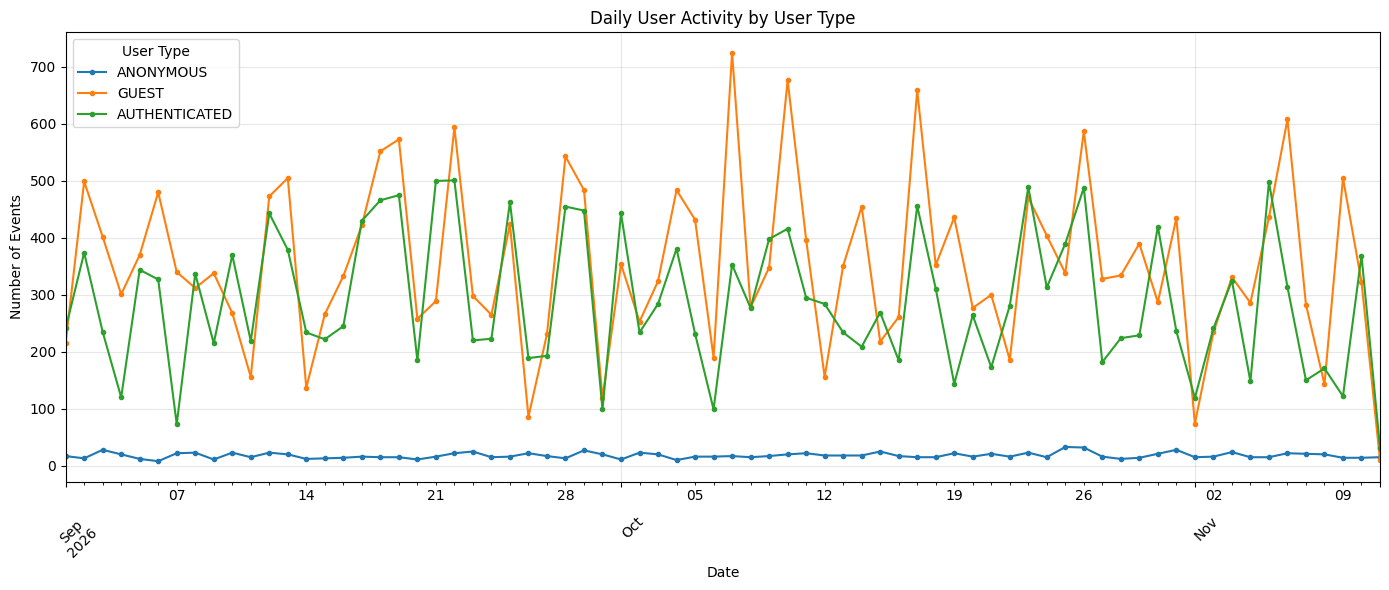

In [146]:
# Візуалізуємо щоденну активність за типами користувачів

import matplotlib.pyplot as plt

daily_pivot[
    ["ANONYMOUS", "GUEST", "AUTHENTICATED"]
].plot(
    figsize=(14, 6),
    marker="o",
    markersize=3
)

plt.title("Daily User Activity by User Type")
plt.xlabel("Date")
plt.ylabel("Number of Events")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend(title="User Type")
plt.tight_layout()
plt.show()

In [147]:
# Перевіряємо часовий розподіл подій за останній день

last_date = temporal_df["event_timestamp"].max().date()

last_day_df = temporal_df[
    temporal_df["event_timestamp"].dt.date == last_date
].copy()

last_day_df["event_hour"] = (
    last_day_df["event_timestamp"].dt.hour
)

last_day_hourly = (
    last_day_df
    .groupby(["user_type", "event_hour"])
    .agg(
        total_events=("event_id", "count")
    )
    .reset_index()
)

print("Остання дата:", last_date)
print("Кількість подій:", len(last_day_df))
print("Перша подія:", last_day_df["event_timestamp"].min())
print("Остання подія:", last_day_df["event_timestamp"].max())

display(last_day_hourly)

Остання дата: 2026-11-11
Кількість подій: 57
Перша подія: 2026-11-11 07:03:54+00:00
Остання подія: 2026-11-11 22:19:08+00:00


,user_type,event_hour,total_events
0,ANONYMOUS,7,3
1,ANONYMOUS,9,1
2,ANONYMOUS,11,1
3,ANONYMOUS,12,1
4,ANONYMOUS,13,1
5,ANONYMOUS,15,1
6,ANONYMOUS,16,1
7,ANONYMOUS,19,4
8,ANONYMOUS,20,2
9,AUTHENTICATED,8,2


In [148]:
# Додаємо назву дня тижня до щоденної активності

weekday_activity = daily_activity.copy()

weekday_activity["event_date"] = pd.to_datetime(
    weekday_activity["event_date"]
)

weekday_activity["weekday"] = (
    weekday_activity["event_date"].dt.day_name()
)

# Визначаємо порядок днів тижня
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

# Розраховуємо середню кількість подій за кожен день тижня
weekday_summary = (
    weekday_activity
    .groupby(["weekday", "user_type"], observed=True)
    .agg(
        total_events=("total_events", "sum"),
        days_observed=("event_date", "nunique"),
        avg_events_per_day=("total_events", "mean"),
        median_events_per_day=("total_events", "median")
    )
    .reset_index()
)

# Сортуємо дні тижня у правильному порядку
weekday_summary["weekday"] = pd.Categorical(
    weekday_summary["weekday"],
    categories=weekday_order,
    ordered=True
)

weekday_summary = weekday_summary.sort_values(
    ["weekday", "user_type"]
)

display(weekday_summary.round(2))

,weekday,user_type,total_events,days_observed,avg_events_per_day,median_events_per_day
3,Monday,ANONYMOUS,181,10,18.10,16.0
4,Monday,AUTHENTICATED,2773,10,277.30,237.5
5,Monday,GUEST,3659,10,365.90,386.0
15,Tuesday,ANONYMOUS,206,11,18.73,17.0
16,Tuesday,AUTHENTICATED,3222,11,292.91,264.0
17,Tuesday,GUEST,3671,11,333.73,323.0
18,Wednesday,ANONYMOUS,181,11,16.45,15.0
19,Wednesday,AUTHENTICATED,2292,11,208.36,215.0
20,Wednesday,GUEST,3697,11,336.09,333.0
12,Thursday,ANONYMOUS,178,10,17.80,15.5


In [149]:
# Виключаємо останній день із порівняння днів тижня

weekday_activity_clean = weekday_activity[
    weekday_activity["event_date"].dt.date < last_date
].copy()

# Розраховуємо середню та медіанну активність
weekday_summary_clean = (
    weekday_activity_clean
    .groupby(["weekday", "user_type"], observed=True)
    .agg(
        total_events=("total_events", "sum"),
        days_observed=("event_date", "nunique"),
        avg_events_per_day=("total_events", "mean"),
        median_events_per_day=("total_events", "median")
    )
    .reset_index()
)

display(
    weekday_summary_clean
    .sort_values(["weekday", "user_type"])
    .round(2)
)

,weekday,user_type,total_events,days_observed,avg_events_per_day,median_events_per_day
0,Friday,ANONYMOUS,189,10,18.90,18.5
1,Friday,AUTHENTICATED,3308,10,330.80,356.0
2,Friday,GUEST,3661,10,366.10,324.5
3,Monday,ANONYMOUS,181,10,18.10,16.0
4,Monday,AUTHENTICATED,2773,10,277.30,237.5
5,Monday,GUEST,3659,10,365.90,386.0
6,Saturday,ANONYMOUS,191,10,19.10,20.0
7,Saturday,AUTHENTICATED,3306,10,330.60,328.5
8,Saturday,GUEST,4284,10,428.40,419.5
9,Sunday,ANONYMOUS,171,10,17.10,16.0


In [150]:
# Виділяємо годину з часової мітки події

temporal_df["event_hour"] = (
    temporal_df["event_timestamp"].dt.hour
)

# Розраховуємо кількість подій за годинами та типами користувачів
hourly_activity = (
    temporal_df
    .groupby(["event_hour", "user_type"])
    .agg(
        total_events=("event_id", "count"),
        unique_visitors=("visitor_id", "nunique")
    )
    .reset_index()
    .sort_values(["event_hour", "user_type"])
)

display(hourly_activity)

,event_hour,user_type,total_events,unique_visitors
0,7,ANONYMOUS,82,75
1,7,AUTHENTICATED,69,52
2,7,GUEST,47,47
3,8,ANONYMOUS,84,81
4,8,AUTHENTICATED,664,92
5,8,GUEST,1253,112
6,9,ANONYMOUS,85,83
7,9,AUTHENTICATED,1218,137
8,9,GUEST,1704,147
9,10,ANONYMOUS,90,85


In [151]:
# Виключаємо перший та останній неповні дні

first_date = temporal_df["event_timestamp"].min().date()
last_date = temporal_df["event_timestamp"].max().date()

weekday_activity_full = weekday_activity[
    (weekday_activity["event_date"].dt.date > first_date) &
    (weekday_activity["event_date"].dt.date < last_date)
].copy()

# Розраховуємо активність за кожен день тижня
weekday_summary_full = (
    weekday_activity_full
    .groupby(["weekday", "user_type"], observed=True)
    .agg(
        total_events=("total_events", "sum"),
        days_observed=("event_date", "nunique"),
        avg_events_per_day=("total_events", "mean"),
        median_events_per_day=("total_events", "median")
    )
    .reset_index()
    .sort_values(["weekday", "user_type"])
)

display(weekday_summary_full.round(2))

,weekday,user_type,total_events,days_observed,avg_events_per_day,median_events_per_day
0,Friday,ANONYMOUS,189,10,18.9,18.5
1,Friday,AUTHENTICATED,3308,10,330.8,356.0
2,Friday,GUEST,3661,10,366.1,324.5
3,Monday,ANONYMOUS,181,10,18.1,16.0
4,Monday,AUTHENTICATED,2773,10,277.3,237.5
5,Monday,GUEST,3659,10,365.9,386.0
6,Saturday,ANONYMOUS,191,10,19.1,20.0
7,Saturday,AUTHENTICATED,3306,10,330.6,328.5
8,Saturday,GUEST,4284,10,428.4,419.5
9,Sunday,ANONYMOUS,171,10,17.1,16.0


In [152]:
# Залишаємо лише повні календарні дні

temporal_full_days = temporal_df[
    (temporal_df["event_timestamp"].dt.date > first_date) &
    (temporal_df["event_timestamp"].dt.date < last_date)
].copy()

# Розраховуємо кількість днів спостереження
n_full_days = temporal_full_days["event_timestamp"].dt.date.nunique()

# Розраховуємо погодинну активність
hourly_summary = (
    temporal_full_days
    .groupby(["event_hour", "user_type"])
    .agg(
        total_events=("event_id", "count"),
        active_days=("event_timestamp", lambda x: x.dt.date.nunique()),
        unique_visitors=("visitor_id", "nunique")
    )
    .reset_index()
)

# Розраховуємо середню кількість подій за годину на один календарний день
hourly_summary["avg_events_per_day"] = (
    hourly_summary["total_events"] / n_full_days
)

display(hourly_summary.round(2))

,event_hour,user_type,total_events,active_days,unique_visitors,avg_events_per_day
0,7,ANONYMOUS,79,47,72,1.13
1,7,AUTHENTICATED,66,36,50,0.94
2,7,GUEST,47,35,47,0.67
3,8,ANONYMOUS,83,51,80,1.19
4,8,AUTHENTICATED,659,48,91,9.41
5,8,GUEST,1243,41,109,17.76
6,9,ANONYMOUS,84,44,82,1.20
7,9,AUTHENTICATED,1207,60,132,17.24
8,9,GUEST,1615,50,143,23.07
9,10,ANONYMOUS,89,50,84,1.27


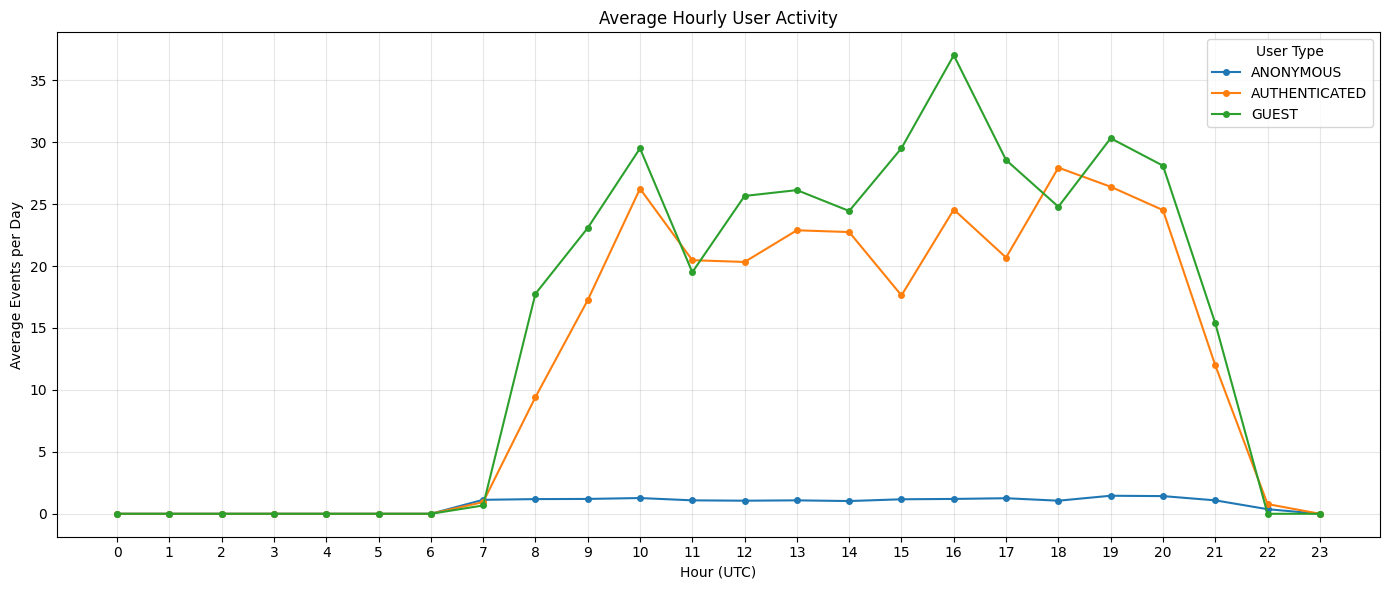

In [153]:
# Формуємо таблицю для погодинного графіка

hourly_pivot = (
    hourly_summary
    .pivot(
        index="event_hour",
        columns="user_type",
        values="avg_events_per_day"
    )
    .reindex(range(24))
    .fillna(0)
)

# Візуалізуємо середню погодинну активність
hourly_pivot.plot(
    figsize=(14, 6),
    marker="o",
    markersize=4
)

plt.title("Average Hourly User Activity")
plt.xlabel("Hour (UTC)")
plt.ylabel("Average Events per Day")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend(title="User Type")
plt.tight_layout()
plt.show()

In [154]:
# Аналізуємо активність користувачів на кожній сторінці

page_activity = (
    activity_df
    .groupby("dataset")
    .agg(
        total_events=("event_id", "count"),
        unique_visitors=("visitor_id", "nunique"),
        unique_users=("user_id", "nunique"),
        page_views=("page_view_id", "nunique")
    )
    .reset_index()
)

# Розраховуємо середню кількість подій на відвідувача
page_activity["avg_events_per_visitor"] = (
    page_activity["total_events"] /
    page_activity["unique_visitors"]
)

# Розраховуємо частку подій кожної сторінки
page_activity["events_share_pct"] = (
    page_activity["total_events"] /
    page_activity["total_events"].sum() * 100
)

# Сортуємо сторінки за кількістю фактичних подій
page_activity = page_activity.sort_values(
    "total_events",
    ascending=False
).reset_index(drop=True)

display(page_activity.round(2))

,dataset,total_events,unique_visitors,unique_users,page_views,avg_events_per_visitor,events_share_pct
0,06_guest_swipe_session,21230,965,0,965,22.00,44.55
1,06_authenticated_swipe_session,16170,373,373,735,43.35,33.93
2,01_landing_page,2083,1679,312,2083,1.24,4.37
3,08_authenticated_results_winners,1475,323,323,530,4.57,3.10
4,08_guest_results_winners,1397,514,0,514,2.72,2.93
5,02_guest_create_room,1375,275,0,275,5.00,2.89
6,02_authenticated_create_room,900,177,177,225,5.08,1.89
7,11_home_signed_in,822,363,381,443,2.26,1.72
8,03_guest_host_room_invite_friends,794,275,0,275,2.89,1.67
9,03_authenticated_host_room_invite_friends,666,177,177,225,3.76,1.40


In [155]:
# Розраховуємо середню кількість подій на один перегляд сторінки

page_activity["avg_events_per_page_view"] = (
    page_activity["total_events"] /
    page_activity["page_views"]
)

# Сортуємо сторінки за інтенсивністю взаємодії
page_activity = page_activity.sort_values(
    "avg_events_per_page_view",
    ascending=False
).reset_index(drop=True)

display(
    page_activity[
        [
            "dataset",
            "total_events",
            "unique_visitors",
            "page_views",
            "avg_events_per_visitor",
            "avg_events_per_page_view",
            "events_share_pct"
        ]
    ].round(2)
)

,dataset,total_events,unique_visitors,page_views,avg_events_per_visitor,avg_events_per_page_view,events_share_pct
0,06_guest_swipe_session,21230,965,965,22.00,22.00,44.55
1,06_authenticated_swipe_session,16170,373,735,43.35,22.00,33.93
2,02_guest_create_room,1375,275,275,5.00,5.00,2.89
3,02_authenticated_create_room,900,177,225,5.08,4.00,1.89
4,03_authenticated_host_room_invite_friends,666,177,225,3.76,2.96,1.40
5,03_guest_host_room_invite_friends,794,275,275,2.89,2.89,1.67
6,08_authenticated_results_winners,1475,323,530,4.57,2.78,3.10
7,08_guest_results_winners,1397,514,514,2.72,2.72,2.93
8,10_sign_up,366,196,196,1.87,1.87,0.77
9,11_home_signed_in,822,363,443,2.26,1.86,1.72


In [156]:
# Аналізуємо розподіл подій усередині кожної сторінки

page_event_distribution = (
    activity_df
    .groupby(["dataset", "event_name"])
    .agg(
        event_count=("event_id", "count"),
        unique_visitors=("visitor_id", "nunique")
    )
    .reset_index()
)

# Розраховуємо загальну кількість подій на кожній сторінці
page_event_distribution["page_total_events"] = (
    page_event_distribution
    .groupby("dataset")["event_count"]
    .transform("sum")
)

# Розраховуємо частку кожної події всередині сторінки
page_event_distribution["event_share_pct"] = (
    page_event_distribution["event_count"] /
    page_event_distribution["page_total_events"] * 100
)

# Сортуємо події за кількістю записів усередині сторінки
page_event_distribution = page_event_distribution.sort_values(
    ["dataset", "event_count"],
    ascending=[True, False]
).reset_index(drop=True)

display(page_event_distribution.round(2))

,dataset,event_name,event_count,unique_visitors,page_total_events,event_share_pct
0,01_landing_page,join_room_clicked,963,780,2083,46.23
1,01_landing_page,guest_start_clicked,452,452,2083,21.70
2,01_landing_page,create_room_submitted,352,315,2083,16.90
3,01_landing_page,sign_up_clicked,120,120,2083,5.76
4,01_landing_page,header_sign_in_clicked,106,106,2083,5.09
5,01_landing_page,account_section_sign_in_clicked,90,90,2083,4.32
6,02_authenticated_create_room,content_type_selected,225,177,900,25.00
7,02_authenticated_create_room,create_room_clicked,225,177,900,25.00
8,02_authenticated_create_room,genres_selected,225,177,900,25.00
9,02_authenticated_create_room,max_duration_selected,225,177,900,25.00


In [157]:
# Відбираємо 5 найчастіших подій для кожної сторінки

top_page_events = (
    page_event_distribution
    .groupby("dataset", group_keys=False)
    .head(5)
    .reset_index(drop=True)
)

display(top_page_events.round(2))

,dataset,event_name,event_count,unique_visitors,page_total_events,event_share_pct
0,01_landing_page,join_room_clicked,963,780,2083,46.23
1,01_landing_page,guest_start_clicked,452,452,2083,21.70
2,01_landing_page,create_room_submitted,352,315,2083,16.90
3,01_landing_page,sign_up_clicked,120,120,2083,5.76
4,01_landing_page,header_sign_in_clicked,106,106,2083,5.09
5,02_authenticated_create_room,content_type_selected,225,177,900,25.00
6,02_authenticated_create_room,create_room_clicked,225,177,900,25.00
7,02_authenticated_create_room,genres_selected,225,177,900,25.00
8,02_authenticated_create_room,max_duration_selected,225,177,900,25.00
9,02_guest_create_room,content_type_selected,275,275,1375,20.00


In [158]:
# Об'єднуємо кількість унікальних відвідувачів сторінки та події

page_event_reach = page_event_distribution.merge(
    page_activity[
        ["dataset", "unique_visitors"]
    ].rename(
        columns={"unique_visitors": "page_unique_visitors"}
    ),
    on="dataset",
    how="left"
)

# Розраховуємо частку відвідувачів сторінки, які виконали подію
page_event_reach["visitor_reach_pct"] = (
    page_event_reach["unique_visitors"] /
    page_event_reach["page_unique_visitors"] * 100
)

# Розраховуємо середню кількість повторень події на одного відвідувача
page_event_reach["events_per_visitor"] = (
    page_event_reach["event_count"] /
    page_event_reach["unique_visitors"]
)

# Сортуємо події за охопленням відвідувачів
page_event_reach = page_event_reach.sort_values(
    ["dataset", "visitor_reach_pct"],
    ascending=[True, False]
).reset_index(drop=True)

display(
    page_event_reach[
        [
            "dataset",
            "event_name",
            "event_count",
            "unique_visitors",
            "page_unique_visitors",
            "visitor_reach_pct",
            "events_per_visitor"
        ]
    ].round(2)
)

,dataset,event_name,event_count,unique_visitors,page_unique_visitors,visitor_reach_pct,events_per_visitor
0,01_landing_page,join_room_clicked,963,780,1679,46.46,1.23
1,01_landing_page,guest_start_clicked,452,452,1679,26.92,1.00
2,01_landing_page,create_room_submitted,352,315,1679,18.76,1.12
3,01_landing_page,sign_up_clicked,120,120,1679,7.15,1.00
4,01_landing_page,header_sign_in_clicked,106,106,1679,6.31,1.00
5,01_landing_page,account_section_sign_in_clicked,90,90,1679,5.36,1.00
6,02_authenticated_create_room,content_type_selected,225,177,177,100.00,1.27
7,02_authenticated_create_room,create_room_clicked,225,177,177,100.00,1.27
8,02_authenticated_create_room,genres_selected,225,177,177,100.00,1.27
9,02_authenticated_create_room,max_duration_selected,225,177,177,100.00,1.27


In [159]:
# Визначаємо етапи Guest та Authenticated воронок

funnel_specs = {
    "GUEST": [
        ("Room Created", "02_guest_create_room", "create_room_submitted"),
        ("Session Started", "03_guest_host_room_invite_friends", "start_session_clicked"),
        ("Swipe Started", "06_guest_swipe_session", "swipe_session_started"),
        ("Swipe Completed", "06_guest_swipe_session", "swipe_session_completed"),
        ("Winner Recorded", "08_guest_results_winners", "movie_won")
    ],
    "AUTHENTICATED": [
        ("Room Created", "02_authenticated_create_room", "create_room_clicked"),
        ("Session Started", "03_authenticated_host_room_invite_friends", "start_session_clicked"),
        ("Swipe Started", "06_authenticated_swipe_session", "swipe_session_started"),
        ("Swipe Completed", "06_authenticated_swipe_session", "swipe_session_completed"),
        ("Winner Recorded", "08_authenticated_results_winners", "movie_won")
    ]
}


# Функція для розрахунку воронки на рівні унікальних кімнат
def build_room_funnel(data, stages):

    funnel_records = []
    previous_rooms = None
    initial_rooms = set()

    for stage_name, dataset_name, event_name in stages:

        stage_df = data[
            (data["dataset"] == dataset_name) &
            (data["event_name"] == event_name) &
            (data["room_id"].notna())
        ]

        current_rooms = set(stage_df["room_id"])

        # Визначаємо кімнати, які послідовно дійшли до поточного етапу
        if previous_rooms is None:
            initial_rooms = current_rooms
            progressed_rooms = current_rooms
            conversion_pct = None
        else:
            progressed_rooms = previous_rooms & current_rooms

            conversion_pct = (
                len(progressed_rooms) / len(previous_rooms) * 100
                if len(previous_rooms) > 0 else 0
            )

        # Розраховуємо загальну конверсію від першого етапу
        cumulative_pct = (
            len(progressed_rooms) / len(initial_rooms) * 100
            if len(initial_rooms) > 0 else 0
        )

        funnel_records.append({
            "stage": stage_name,
            "rooms_with_event": len(current_rooms),
            "rooms_progressing": len(progressed_rooms),
            "conversion_from_previous_pct": conversion_pct,
            "cumulative_conversion_pct": cumulative_pct
        })

        previous_rooms = progressed_rooms

    return pd.DataFrame(funnel_records)


# Формуємо окремі воронки
guest_funnel = build_room_funnel(
    activity_df,
    funnel_specs["GUEST"]
)

authenticated_funnel = build_room_funnel(
    activity_df,
    funnel_specs["AUTHENTICATED"]
)

print("GUEST FUNNEL")
display(guest_funnel.round(2))

print("AUTHENTICATED FUNNEL")
display(authenticated_funnel.round(2))

GUEST FUNNEL


,stage,rooms_with_event,rooms_progressing,conversion_from_previous_pct,cumulative_conversion_pct
0,Room Created,275,275,NaN,100.0
1,Session Started,275,275,100.0,100.0
2,Swipe Started,460,275,100.0,100.0
3,Swipe Completed,460,275,100.0,100.0
4,Winner Recorded,275,275,100.0,100.0


AUTHENTICATED FUNNEL


,stage,rooms_with_event,rooms_progressing,conversion_from_previous_pct,cumulative_conversion_pct
0,Room Created,225,225,NaN,100.00
1,Session Started,225,225,100.00,100.00
2,Swipe Started,416,225,100.00,100.00
3,Swipe Completed,416,225,100.00,100.00
4,Winner Recorded,224,224,99.56,99.56


In [160]:
# Знаходимо кімнати, створені AUTHENTICATED користувачами

auth_created_rooms = set(
    activity_df.loc[
        (activity_df["dataset"] == "02_authenticated_create_room") &
        (activity_df["event_name"] == "create_room_clicked"),
        "room_id"
    ].dropna()
)

# Знаходимо кімнати з подією реєстрації переможця

auth_winner_rooms = set(
    activity_df.loc[
        (activity_df["dataset"] == "08_authenticated_results_winners") &
        (activity_df["event_name"] == "movie_won"),
        "room_id"
    ].dropna()
)

# Визначаємо кімнати без зареєстрованого переможця

auth_rooms_without_winner = (
    auth_created_rooms - auth_winner_rooms
)

print("Кількість кімнат без переможця:",
      len(auth_rooms_without_winner))

print("ID кімнат:", auth_rooms_without_winner)

# Перевіряємо події знайдених кімнат
room_details = activity_df[
    activity_df["room_id"].isin(auth_rooms_without_winner)
].copy()

room_details = room_details[
    room_details["dataset"].isin([
        "02_authenticated_create_room",
        "03_authenticated_host_room_invite_friends",
        "06_guest_swipe_session",
        "06_authenticated_swipe_session",
        "08_authenticated_results_winners"
    ])
]

display(
    room_details[
        [
            "room_id",
            "dataset",
            "event_name",
            "event_timestamp"
        ]
    ].sort_values("event_timestamp")
)

Кількість кімнат без переможця: 1
ID кімнат: {500004.0}


,room_id,dataset,event_name,event_timestamp
15004,500004.0,02_authenticated_create_room,content_type_selected,2026-09-15T14:11:08Z
15005,500004.0,02_authenticated_create_room,genres_selected,2026-09-15T14:11:08Z
15006,500004.0,02_authenticated_create_room,max_duration_selected,2026-09-15T14:11:08Z
15007,500004.0,02_authenticated_create_room,create_room_clicked,2026-09-15T14:11:08Z
17279,500004.0,03_authenticated_host_room_invite_friends,room_invite_link_copied,2026-09-15T14:13:08Z
17281,500004.0,03_authenticated_host_room_invite_friends,start_session_clicked,2026-09-15T14:13:08Z
17282,500004.0,03_authenticated_host_room_invite_friends,participant_count,2026-09-15T14:13:08Z
19363,500004.0,06_authenticated_swipe_session,swipe_session_started,2026-09-15T14:40:03Z
19385,500004.0,06_authenticated_swipe_session,swipe_session_started,2026-09-15T14:40:03Z
19386,500004.0,06_authenticated_swipe_session,movie_disliked,2026-09-15T14:43:38Z


In [161]:
# Перевіряємо голосування в кімнаті 500004

vote_values = {
    "swipe_right": True,
    "Like_button": True,
    "movie_liked": True,
    "swipe_left": False,
    "dislike_button": False,
    "movie_disliked": False
}

room_votes = activity_df[
    (activity_df["room_id"] == 500004) &
    (activity_df["event_name"].isin(vote_values))
].copy()

# Визначаємо позитивні та негативні голоси
room_votes["is_liked"] = room_votes["event_name"].map(vote_values)

print("Загальна кількість голосів:", len(room_votes))
print("Унікальних учасників:", room_votes["participant_id"].nunique())
print("Унікальних карток фільмів:", room_votes["room_title_id"].nunique())
print("Позитивних голосів:", room_votes["is_liked"].sum())
print("Негативних голосів:", (~room_votes["is_liked"]).sum())

# Перевіряємо розподіл голосів за типами подій
display(
    room_votes
    .groupby(["dataset", "event_name"])
    .size()
    .reset_index(name="votes_count")
)

# Перевіряємо голоси за кожним фільмом
votes_by_title = (
    room_votes
    .groupby(["room_title_id", "title_id"])
    .agg(
        total_votes=("event_id", "count"),
        likes=("is_liked", "sum")
    )
    .reset_index()
)

votes_by_title["dislikes"] = (
    votes_by_title["total_votes"] - votes_by_title["likes"]
)

display(votes_by_title.sort_values("likes", ascending=False))

Загальна кількість голосів: 40
Унікальних учасників: 2
Унікальних карток фільмів: 20
Позитивних голосів: 0
Негативних голосів: 40


,dataset,event_name,votes_count
0,06_authenticated_swipe_session,movie_disliked,40


,room_title_id,title_id,total_votes,likes,dislikes
0,3000061.0,800680.0,2,0,2
1,3000062.0,800656.0,2,0,2
2,3000063.0,801762.0,2,0,2
3,3000064.0,802842.0,2,0,2
4,3000065.0,802387.0,2,0,2
5,3000066.0,801457.0,2,0,2
6,3000067.0,802116.0,2,0,2
7,3000068.0,802014.0,2,0,2
8,3000069.0,801779.0,2,0,2
9,3000070.0,802506.0,2,0,2


In [162]:
# Перевіряємо події на сторінці результатів кімнати 500004

room_results = activity_df[
    (activity_df["room_id"] == 500004) &
    (activity_df["dataset"] == "08_authenticated_results_winners")
][
    ["event_name", "event_timestamp"]
].sort_values("event_timestamp")

display(room_results)

,event_name,event_timestamp
56695,explore_taste_clicked,2026-09-15T15:09:28Z
56697,winner_details_clicked,2026-09-15T15:10:17Z
56699,explore_taste_clicked,2026-09-15T15:10:17Z


In [163]:
# Аналізуємо структуру значень параметрів створення кімнати

create_room_datasets = [
    "02_guest_create_room",
    "02_authenticated_create_room"
]

selection_events = [
    "content_type_selected",
    "genres_selected",
    "max_duration_selected"
]

for dataset_name in create_room_datasets:

    print("\n" + "=" * 70)
    print(f"DATASET: {dataset_name}")

    df = cleaned_datasets[dataset_name]

    for event_name in selection_events:

        event_df = df[
            df["event_name"] == event_name
        ]

        print(f"\nEvent: {event_name}")
        print("Кількість записів:", len(event_df))

        print("\nТипи значень:")
        display(
            event_df["event_value_type"]
            .value_counts(dropna=False)
        )

        print("\nПриклади event_value:")
        display(
            event_df["event_value"]
            .dropna()
            .astype(str)
            .drop_duplicates()
            .head(10)
        )


DATASET: 02_guest_create_room

Event: content_type_selected
Кількість записів: 275

Типи значень:


event_value_type
string    275
Name: count, dtype: Int64


Приклади event_value:


1    TV Shows
6      Movies
Name: event_value, dtype: object


Event: genres_selected
Кількість записів: 275

Типи значень:


event_value_type
json    275
Name: count, dtype: Int64

... (14 outputs left out)


Event: max_duration_selected
Кількість записів: 225

Типи значень:


event_value_type
integer    225
Name: count, dtype: Int64


Приклади event_value:


2     120
14    150
18     90
Name: event_value, dtype: object

In [164]:
# Підготовлюємо дані про параметри створення кімнат

create_room_frames = {
    "GUEST": cleaned_datasets["02_guest_create_room"],
    "AUTHENTICATED": cleaned_datasets["02_authenticated_create_room"]
}

content_rows = []
duration_rows = []
genre_rows = []
genre_selection_rows = []


# Обробляємо параметри для кожного типу користувачів
for user_type, df in create_room_frames.items():

    # Отримуємо кількість кімнат
    total_rooms = df["room_id"].nunique()

    # Аналізуємо тип контенту
    content_df = df[
        df["event_name"] == "content_type_selected"
    ][["room_id", "event_value"]].copy()

    content_df["user_type"] = user_type
    content_rows.append(content_df)

    # Аналізуємо максимальну тривалість
    duration_df = df[
        df["event_name"] == "max_duration_selected"
    ][["room_id", "event_value"]].copy()

    duration_df["user_type"] = user_type
    duration_rows.append(duration_df)

    # Аналізуємо вибрані жанри
    genres_df = df[
        df["event_name"] == "genres_selected"
    ][["room_id", "event_value"]].copy()

    # Перетворюємо JSON-рядки на Python-списки
    def parse_genres(value):

        if isinstance(value, list):
            return value

        if pd.isna(value):
            return []

        try:
            result = json.loads(value)

            if isinstance(result, list):
                return result

            return []

        except (ValueError, TypeError):
            return []

    genres_df["genres"] = genres_df["event_value"].apply(parse_genres)

    # Фіксуємо кількість вибраних жанрів у кожній кімнаті
    for _, row in genres_df.iterrows():

        genre_selection_rows.append({
            "user_type": user_type,
            "room_id": row["room_id"],
            "genre_count": len(row["genres"])
        })

        # Додаємо окремий запис для кожного вибраного жанру
        for genre in row["genres"]:

            genre_rows.append({
                "user_type": user_type,
                "room_id": row["room_id"],
                "genre": genre
            })


# Об'єднуємо результати
content_data = pd.concat(content_rows, ignore_index=True)
duration_data = pd.concat(duration_rows, ignore_index=True)

genres_data = pd.DataFrame(genre_rows)
genre_selection_data = pd.DataFrame(genre_selection_rows)

print("Guest rooms:", create_room_frames["GUEST"]["room_id"].nunique())
print("Authenticated rooms:", create_room_frames["AUTHENTICATED"]["room_id"].nunique())
print("Genre selection records:", len(genre_selection_data))
print("Selected genre records:", len(genres_data))

Guest rooms: 275
Authenticated rooms: 225
Genre selection records: 500
Selected genre records: 600


In [165]:
# Аналізуємо популярність типів контенту

content_type_summary = (
    content_data
    .groupby(["user_type", "event_value"])
    .agg(
        rooms=("room_id", "nunique")
    )
    .reset_index()
)

# Розраховуємо частку кожного типу контенту
content_type_summary["share_pct"] = (
    content_type_summary["rooms"] /
    content_type_summary.groupby("user_type")["rooms"].transform("sum") * 100
)

display(content_type_summary.round(2))

,user_type,event_value,rooms,share_pct
0,AUTHENTICATED,Movies,179,79.56
1,AUTHENTICATED,TV Shows,46,20.44
2,GUEST,Movies,214,77.82
3,GUEST,TV Shows,61,22.18


In [167]:
# Аналізуємо кількість вибраних жанрів на одну кімнату

genre_selection_summary = (
    genre_selection_data
    .groupby("user_type")
    .agg(
        total_rooms=("room_id", "nunique"),
        rooms_without_genres=(
            "genre_count",
            lambda x: (x == 0).sum()
        ),
        avg_genres_per_room=("genre_count", "mean"),
        median_genres_per_room=("genre_count", "median"),
        max_genres_per_room=("genre_count", "max")
    )
    .reset_index()
)

# Розраховуємо частку кімнат без вибраних жанрів
genre_selection_summary["empty_genres_pct"] = (
    genre_selection_summary["rooms_without_genres"] /
    genre_selection_summary["total_rooms"] * 100
)

display(genre_selection_summary.round(2))

,user_type,total_rooms,rooms_without_genres,avg_genres_per_room,median_genres_per_room,max_genres_per_room,empty_genres_pct
0,AUTHENTICATED,225,53,1.18,1.0,3,23.56
1,GUEST,275,59,1.21,1.0,3,21.45


In [171]:
# Перетворюємо значення тривалості у числовий формат

duration_data["max_duration"] = pd.to_numeric(
    duration_data["event_value"],
    errors="coerce"
)

# Розраховуємо кількість кімнат для кожного значення тривалості
duration_summary = (
    duration_data
    .groupby(["user_type", "max_duration"])
    .agg(
        rooms=("room_id", "nunique")
    )
    .reset_index()
)

# Розраховуємо частку кожного значення тривалості
duration_summary["share_pct"] = (
    duration_summary["rooms"] /
    duration_summary.groupby("user_type")["rooms"].transform("sum") * 100
)

# Сортуємо результати
duration_summary = duration_summary.sort_values(
    ["user_type", "rooms"],
    ascending=[True, False]
).reset_index(drop=True)

display(duration_summary.round(2))

,user_type,max_duration,rooms,share_pct
0,AUTHENTICATED,120,79,35.11
1,AUTHENTICATED,90,78,34.67
2,AUTHENTICATED,150,68,30.22
3,GUEST,150,95,34.55
4,GUEST,90,90,32.73
5,GUEST,120,90,32.73


In [173]:
# Розраховуємо популярність кожного жанру за кількістю кімнат

genre_summary = (
    genres_data
    .drop_duplicates(["user_type", "room_id", "genre"])
    .groupby(["user_type", "genre"])
    .agg(
        rooms=("room_id", "nunique")
    )
    .reset_index()
)

# Визначаємо загальну кількість кімнат у кожному сегменті
rooms_by_user = {
    user_type: df["room_id"].nunique()
    for user_type, df in create_room_frames.items()
}

# Розраховуємо частку кімнат із вибраним жанром
genre_summary["share_of_rooms_pct"] = (
    genre_summary["rooms"] /
    genre_summary["user_type"].map(rooms_by_user) * 100
)

# Сортуємо жанри за популярністю
genre_summary = genre_summary.sort_values(
    ["user_type", "rooms"],
    ascending=[True, False]
).reset_index(drop=True)

display(genre_summary.round(2))

,user_type,genre,rooms,share_of_rooms_pct
0,AUTHENTICATED,Western,23,10.22
1,AUTHENTICATED,History,20,8.89
2,AUTHENTICATED,Mystery,20,8.89
3,AUTHENTICATED,Documentary,19,8.44
4,AUTHENTICATED,Comedy,18,8.00
5,AUTHENTICATED,Music,17,7.56
6,AUTHENTICATED,Drama,15,6.67
7,AUTHENTICATED,Adventure,14,6.22
8,AUTHENTICATED,Animation,14,6.22
9,AUTHENTICATED,Action,13,5.78


In [174]:
# Виводимо топ-10 жанрів для кожного сегмента

top_genres = (
    genre_summary
    .groupby("user_type", group_keys=False)
    .head(10)
)

display(top_genres.round(2))

,user_type,genre,rooms,share_of_rooms_pct
0,AUTHENTICATED,Western,23,10.22
1,AUTHENTICATED,History,20,8.89
2,AUTHENTICATED,Mystery,20,8.89
3,AUTHENTICATED,Documentary,19,8.44
4,AUTHENTICATED,Comedy,18,8.00
5,AUTHENTICATED,Music,17,7.56
6,AUTHENTICATED,Drama,15,6.67
7,AUTHENTICATED,Adventure,14,6.22
8,AUTHENTICATED,Animation,14,6.22
9,AUTHENTICATED,Action,13,5.78


In [175]:
# Аналізуємо кількість вибраних жанрів на одну кімнату

display(genre_selection_summary.round(2))

,user_type,total_rooms,rooms_without_genres,avg_genres_per_room,median_genres_per_room,max_genres_per_room,empty_genres_pct
0,AUTHENTICATED,225,53,1.18,1.0,3,23.56
1,GUEST,275,59,1.21,1.0,3,21.45


In [176]:
# Визначаємо події голосування для Guest та Authenticated

vote_event_names = [
    "swipe_right",
    "swipe_left",
    "Like_button",
    "dislike_button",
    "movie_liked",
    "movie_disliked"
]

# Формуємо таблицю унікальних пар кімната-учасник
room_participants = (
    activity_df[
        activity_df["event_name"].isin(vote_event_names) &
        activity_df["room_id"].notna() &
        activity_df["participant_id"].notna()
    ][["room_id", "participant_id"]]
    .drop_duplicates()
)

# Розраховуємо кількість учасників у кожній кімнаті
room_group_size = (
    room_participants
    .groupby("room_id")
    .agg(
        participants=("participant_id", "nunique")
    )
    .reset_index()
)

# Перевіряємо результат
print("Кількість кімнат:", room_group_size["room_id"].nunique())
print("Кількість унікальних пар кімната-учасник:", len(room_participants))

display(room_group_size.head(10))

Кількість кімнат: 500
Кількість унікальних пар кімната-учасник: 1700


,room_id,participants
0,500001.0,5
1,500002.0,5
2,500003.0,4
3,500004.0,2
4,500005.0,2
5,500006.0,2
6,500007.0,2
7,500008.0,4
8,500009.0,3
9,500010.0,3


In [177]:
# Аналізуємо розподіл кімнат за кількістю учасників

group_size_summary = (
    room_group_size
    .groupby("participants")
    .agg(
        rooms=("room_id", "nunique")
    )
    .reset_index()
)

# Розраховуємо частку кімнат кожного розміру
group_size_summary["room_share_pct"] = (
    group_size_summary["rooms"] /
    group_size_summary["rooms"].sum() * 100
)

# Розраховуємо кількість учасників у всіх кімнатах кожного розміру
group_size_summary["participant_instances"] = (
    group_size_summary["participants"] *
    group_size_summary["rooms"]
)

display(group_size_summary.round(2))

,participants,rooms,room_share_pct,participant_instances
0,2,100,20.0,200
1,3,175,35.0,525
2,4,150,30.0,600
3,5,75,15.0,375


In [178]:
# Розраховуємо загальні характеристики розміру груп

group_size_statistics = pd.DataFrame({
    "metric": [
        "Total rooms",
        "Total participants",
        "Average participants per room",
        "Median participants per room",
        "Minimum group size",
        "Maximum group size"
    ],
    "value": [
        room_group_size["room_id"].nunique(),
        room_group_size["participants"].sum(),
        room_group_size["participants"].mean(),
        room_group_size["participants"].median(),
        room_group_size["participants"].min(),
        room_group_size["participants"].max()
    ]
})

display(group_size_statistics.round(2))

,metric,value
0,Total rooms,500.0
1,Total participants,1700.0
2,Average participants per room,3.4
3,Median participants per room,3.0
4,Minimum group size,2.0
5,Maximum group size,5.0


In [179]:
# Перевіряємо відповідність кількості учасників у кімнатах

# Отримуємо заявлену кількість учасників із подій participant_count
declared_participants = activity_df[
    (activity_df["event_name"] == "participant_count") &
    (activity_df["room_id"].notna())
][["room_id", "event_value", "dataset"]].copy()

# Перетворюємо значення кількості учасників у числовий формат
declared_participants["declared_count"] = pd.to_numeric(
    declared_participants["event_value"],
    errors="coerce"
)

# Рахуємо фактичну кількість учасників за голосуваннями
observed_participants = (
    room_participants
    .groupby("room_id")
    .agg(
        observed_count=("participant_id", "nunique")
    )
    .reset_index()
)

# Об'єднуємо обидва джерела
participant_validation = declared_participants.merge(
    observed_participants,
    on="room_id",
    how="left"
)

# Перевіряємо відповідність значень
participant_validation["matches"] = (
    participant_validation["declared_count"] ==
    participant_validation["observed_count"]
)

print("Кількість записів:", len(participant_validation))
print("Збігів:", participant_validation["matches"].sum())
print("Розбіжностей:", (~participant_validation["matches"]).sum())

display(
    participant_validation[
        [
            "room_id",
            "dataset",
            "declared_count",
            "observed_count",
            "matches"
        ]
    ].head(15)
)

# Виводимо кімнати з розбіжностями, якщо вони є
display(
    participant_validation[
        participant_validation["matches"] == False
    ]
)

Кількість записів: 500
Збігів: 500
Розбіжностей: 0


,room_id,dataset,declared_count,observed_count,matches
0,500001.0,03_authenticated_host_room_invite_friends,5,5,True
1,500004.0,03_authenticated_host_room_invite_friends,2,2,True
2,500005.0,03_authenticated_host_room_invite_friends,2,2,True
3,500008.0,03_authenticated_host_room_invite_friends,4,4,True
4,500010.0,03_authenticated_host_room_invite_friends,3,3,True
5,500011.0,03_authenticated_host_room_invite_friends,5,5,True
6,500012.0,03_authenticated_host_room_invite_friends,4,4,True
7,500013.0,03_authenticated_host_room_invite_friends,4,4,True
8,500015.0,03_authenticated_host_room_invite_friends,5,5,True
9,500017.0,03_authenticated_host_room_invite_friends,5,5,True


,room_id,event_value,dataset,declared_count,observed_count,matches


In [180]:
# Готуємо події початку та завершення голосування

swipe_datasets = [
    "06_guest_swipe_session",
    "06_authenticated_swipe_session"
]

session_events = activity_df[
    (activity_df["dataset"].isin(swipe_datasets)) &
    (activity_df["event_name"].isin([
        "swipe_session_started",
        "swipe_session_completed"
    ])) &
    (activity_df["room_id"].notna()) &
    (activity_df["participant_id"].notna())
].copy()

# Перетворюємо часові мітки у формат datetime
session_events["event_timestamp"] = pd.to_datetime(
    session_events["event_timestamp"],
    utc=True,
    errors="coerce"
)

# Перетворюємо події початку та завершення у окремі стовпці
participant_sessions = (
    session_events
    .pivot_table(
        index=["dataset", "room_id", "participant_id"],
        columns="event_name",
        values="event_timestamp",
        aggfunc="min"
    )
    .reset_index()
)

# Перейменовуємо стовпці для зручності
participant_sessions = participant_sessions.rename(columns={
    "swipe_session_started": "started_at",
    "swipe_session_completed": "completed_at"
})

# Перевіряємо наявність обох часових міток
print("Кількість записів:", len(participant_sessions))
print(
    "Без початку:",
    participant_sessions["started_at"].isna().sum()
)
print(
    "Без завершення:",
    participant_sessions["completed_at"].isna().sum()
)

# Розраховуємо тривалість голосування у хвилинах
participant_sessions["duration_minutes"] = (
    participant_sessions["completed_at"] -
    participant_sessions["started_at"]
).dt.total_seconds() / 60

# Визначаємо тип користувача
participant_sessions["user_type"] = (
    participant_sessions["dataset"]
    .map({
        "06_guest_swipe_session": "GUEST",
        "06_authenticated_swipe_session": "AUTHENTICATED"
    })
)

# Перевіряємо некоректні значення тривалості
print(
    "Некоректна тривалість:",
    (
        participant_sessions["duration_minutes"].isna() |
        (participant_sessions["duration_minutes"] < 0)
    ).sum()
)

display(participant_sessions.head(10))

Кількість записів: 1700
Без початку: 0
Без завершення: 0
Некоректна тривалість: 0


event_name,dataset,room_id,participant_id,completed_at,started_at,duration_minutes,user_type
0,06_authenticated_swipe_session,500001.0,700001.0,2026-10-21 19:29:09+00:00,2026-10-21 19:06:53+00:00,22.266667,AUTHENTICATED
1,06_authenticated_swipe_session,500002.0,700007.0,2026-09-06 14:31:07+00:00,2026-09-06 14:09:19+00:00,21.800000,AUTHENTICATED
2,06_authenticated_swipe_session,500002.0,700009.0,2026-09-06 14:30:00+00:00,2026-09-06 14:09:19+00:00,20.683333,AUTHENTICATED
3,06_authenticated_swipe_session,500003.0,700013.0,2026-10-28 18:16:08+00:00,2026-10-28 17:51:15+00:00,24.883333,AUTHENTICATED
4,06_authenticated_swipe_session,500004.0,700015.0,2026-09-15 15:04:01+00:00,2026-09-15 14:40:03+00:00,23.966667,AUTHENTICATED
5,06_authenticated_swipe_session,500004.0,700016.0,2026-09-15 15:07:36+00:00,2026-09-15 14:40:03+00:00,27.550000,AUTHENTICATED
6,06_authenticated_swipe_session,500005.0,700017.0,2026-10-03 10:43:15+00:00,2026-10-03 10:22:13+00:00,21.033333,AUTHENTICATED
7,06_authenticated_swipe_session,500008.0,700023.0,2026-10-03 13:36:26+00:00,2026-10-03 13:08:13+00:00,28.216667,AUTHENTICATED
8,06_authenticated_swipe_session,500008.0,700024.0,2026-10-03 13:29:07+00:00,2026-10-03 13:08:13+00:00,20.900000,AUTHENTICATED
9,06_authenticated_swipe_session,500008.0,700025.0,2026-10-03 13:39:27+00:00,2026-10-03 13:08:13+00:00,31.233333,AUTHENTICATED


In [181]:
# Аналізуємо тривалість голосування за типами користувачів

session_duration_summary = (
    participant_sessions
    .groupby("user_type")
    .agg(
        participant_sessions=("participant_id", "count"),
        avg_duration_min=("duration_minutes", "mean"),
        median_duration_min=("duration_minutes", "median"),
        min_duration_min=("duration_minutes", "min"),
        q25=("duration_minutes", lambda x: x.quantile(0.25)),
        q75=("duration_minutes", lambda x: x.quantile(0.75)),
        max_duration_min=("duration_minutes", "max")
    )
    .reset_index()
)

display(session_duration_summary.round(2))

,user_type,participant_sessions,avg_duration_min,median_duration_min,min_duration_min,q25,q75,max_duration_min
0,AUTHENTICATED,735,25.69,25.63,13.6,22.59,28.69,35.27
1,GUEST,965,25.58,25.70,13.2,22.43,28.97,35.62


In [182]:
# Додаємо розмір групи до даних про тривалість голосування

session_duration_by_group = participant_sessions.merge(
    room_group_size[["room_id", "participants"]],
    on="room_id",
    how="left"
)

# Перевіряємо, чи всі сесії мають інформацію про розмір групи
print(
    "Сесій без інформації про розмір групи:",
    session_duration_by_group["participants"].isna().sum()
)

# Аналізуємо тривалість сесій залежно від розміру групи
group_duration_summary = (
    session_duration_by_group
    .groupby(["user_type", "participants"])
    .agg(
        total_sessions=("participant_id", "count"),
        avg_duration_min=("duration_minutes", "mean"),
        median_duration_min=("duration_minutes", "median"),
        min_duration_min=("duration_minutes", "min"),
        max_duration_min=("duration_minutes", "max")
    )
    .reset_index()
    .sort_values(["user_type", "participants"])
)

display(group_duration_summary.round(2))

Сесій без інформації про розмір групи: 0


,user_type,participants,total_sessions,avg_duration_min,median_duration_min,min_duration_min,max_duration_min
0,AUTHENTICATED,2,91,25.18,25.03,16.02,33.37
1,AUTHENTICATED,3,218,25.56,25.47,16.10,34.93
2,AUTHENTICATED,4,264,26.06,26.06,15.40,35.27
3,AUTHENTICATED,5,162,25.54,25.68,13.60,33.78
4,GUEST,2,109,25.94,26.00,17.42,33.33
5,GUEST,3,307,25.11,25.05,13.20,34.93
6,GUEST,4,336,25.64,25.53,16.15,35.62
7,GUEST,5,213,25.98,25.97,15.82,34.65


In [183]:
# Готуємо дані про голосування учасників

vote_event_names = [
    "swipe_right",
    "swipe_left",
    "Like_button",
    "dislike_button",
    "movie_liked",
    "movie_disliked"
]

vote_analysis_df = activity_df[
    activity_df["event_name"].isin(vote_event_names)
].copy()

# Визначаємо позитивні та негативні голоси
vote_mapping = {
    "swipe_right": True,
    "Like_button": True,
    "movie_liked": True,
    "swipe_left": False,
    "dislike_button": False,
    "movie_disliked": False
}

vote_analysis_df["is_liked"] = (
    vote_analysis_df["event_name"].map(vote_mapping)
)

# Розраховуємо кількість голосів для кожного учасника в кожній кімнаті
participant_vote_summary = (
    vote_analysis_df
    .groupby(["user_type", "room_id", "participant_id"])
    .agg(
        total_votes=("event_id", "count"),
        unique_movies=("room_title_id", "nunique"),
        likes=("is_liked", "sum")
    )
    .reset_index()
)

# Розраховуємо кількість негативних голосів
participant_vote_summary["dislikes"] = (
    participant_vote_summary["total_votes"] -
    participant_vote_summary["likes"]
)

print("Загальна кількість голосів:", len(vote_analysis_df))
print("Кількість записів учасник-кімната:", len(participant_vote_summary))

display(participant_vote_summary.head(10))

Загальна кількість голосів: 34000
Кількість записів учасник-кімната: 1700


,user_type,room_id,participant_id,total_votes,unique_movies,likes,dislikes
0,AUTHENTICATED,500001.0,700001.0,20,20,7,13
1,AUTHENTICATED,500002.0,700007.0,20,20,10,10
2,AUTHENTICATED,500002.0,700009.0,20,20,11,9
3,AUTHENTICATED,500003.0,700013.0,20,20,8,12
4,AUTHENTICATED,500004.0,700015.0,20,20,0,20
5,AUTHENTICATED,500004.0,700016.0,20,20,0,20
6,AUTHENTICATED,500005.0,700017.0,20,20,2,18
7,AUTHENTICATED,500008.0,700023.0,20,20,12,8
8,AUTHENTICATED,500008.0,700024.0,20,20,10,10
9,AUTHENTICATED,500008.0,700025.0,20,20,5,15


In [184]:
# Аналізуємо кількість голосів на одного учасника

participant_vote_stats = (
    participant_vote_summary
    .groupby("user_type")
    .agg(
        participants=("participant_id", "nunique"),
        avg_votes=("total_votes", "mean"),
        median_votes=("total_votes", "median"),
        min_votes=("total_votes", "min"),
        max_votes=("total_votes", "max"),
        avg_unique_movies=("unique_movies", "mean"),
        participants_with_20_votes=(
            "total_votes",
            lambda x: (x == 20).sum()
        )
    )
    .reset_index()
)

display(participant_vote_stats.round(2))

,user_type,participants,avg_votes,median_votes,min_votes,max_votes,avg_unique_movies,participants_with_20_votes
0,AUTHENTICATED,735,20.0,20.0,20,20,20.0,735
1,GUEST,965,20.0,20.0,20,20,20.0,965


In [185]:
# Аналізуємо кількість голосів у кожній кімнаті

room_vote_summary = (
    vote_analysis_df
    .groupby("room_id")
    .agg(
        total_votes=("event_id", "count"),
        participants=("participant_id", "nunique"),
        unique_movies=("room_title_id", "nunique"),
        likes=("is_liked", "sum")
    )
    .reset_index()
)

# Розраховуємо кількість негативних голосів
room_vote_summary["dislikes"] = (
    room_vote_summary["total_votes"] -
    room_vote_summary["likes"]
)

# Розраховуємо кількість голосів на одного учасника
room_vote_summary["votes_per_participant"] = (
    room_vote_summary["total_votes"] /
    room_vote_summary["participants"]
)

# Аналізуємо кімнати за розміром групи
room_vote_stats = (
    room_vote_summary
    .groupby("participants")
    .agg(
        rooms=("room_id", "nunique"),
        avg_total_votes=("total_votes", "mean"),
        avg_votes_per_participant=("votes_per_participant", "mean"),
        avg_unique_movies=("unique_movies", "mean")
    )
    .reset_index()
)

display(room_vote_stats.round(2))

,participants,rooms,avg_total_votes,avg_votes_per_participant,avg_unique_movies
0,2,100,40.0,20.0,20.0
1,3,175,60.0,20.0,20.0
2,4,150,80.0,20.0,20.0
3,5,75,100.0,20.0,20.0


In [186]:
# Аналізуємо співвідношення позитивних та негативних голосів

vote_segment_summary = (
    participant_vote_summary
    .groupby("user_type")
    .agg(
        participants=("participant_id", "count"),
        total_votes=("total_votes", "sum"),
        total_likes=("likes", "sum"),
        total_dislikes=("dislikes", "sum"),
        avg_likes_per_participant=("likes", "mean"),
        avg_dislikes_per_participant=("dislikes", "mean")
    )
    .reset_index()
)

# Розраховуємо частки позитивних та негативних голосів
vote_segment_summary["like_rate_pct"] = (
    vote_segment_summary["total_likes"] /
    vote_segment_summary["total_votes"] * 100
)

vote_segment_summary["dislike_rate_pct"] = (
    vote_segment_summary["total_dislikes"] /
    vote_segment_summary["total_votes"] * 100
)

display(vote_segment_summary.round(2))

,user_type,participants,total_votes,total_likes,total_dislikes,avg_likes_per_participant,avg_dislikes_per_participant,like_rate_pct,dislike_rate_pct
0,AUTHENTICATED,735,14700,7995,6705,10.88,9.12,54.39,45.61
1,GUEST,965,19300,10511,8789,10.89,9.11,54.46,45.54


In [187]:
# Додаємо розмір групи до даних про голосування

participant_votes_by_group = participant_vote_summary.merge(
    room_group_size[["room_id", "participants"]].rename(
        columns={"participants": "group_size"}
    ),
    on="room_id",
    how="left"
)

# Аналізуємо голосування за типом користувача та розміром групи
vote_group_summary = (
    participant_votes_by_group
    .groupby(["user_type", "group_size"])
    .agg(
        participants=("participant_id", "count"),
        total_votes=("total_votes", "sum"),
        likes=("likes", "sum"),
        dislikes=("dislikes", "sum")
    )
    .reset_index()
)

# Розраховуємо частку лайків
vote_group_summary["like_rate_pct"] = (
    vote_group_summary["likes"] /
    vote_group_summary["total_votes"] * 100
)

# Розраховуємо частку дизлайків
vote_group_summary["dislike_rate_pct"] = (
    vote_group_summary["dislikes"] /
    vote_group_summary["total_votes"] * 100
)

display(vote_group_summary.round(2))

,user_type,group_size,participants,total_votes,likes,dislikes,like_rate_pct,dislike_rate_pct
0,AUTHENTICATED,2,91,1820,942,878,51.76,48.24
1,AUTHENTICATED,3,218,4360,2418,1942,55.46,44.54
2,AUTHENTICATED,4,264,5280,2872,2408,54.39,45.61
3,AUTHENTICATED,5,162,3240,1763,1477,54.41,45.59
4,GUEST,2,109,2180,1168,1012,53.58,46.42
5,GUEST,3,307,6140,3404,2736,55.44,44.56
6,GUEST,4,336,6720,3613,3107,53.76,46.24
7,GUEST,5,213,4260,2326,1934,54.60,45.40


In [188]:
# Визначаємо кількість фільмів-переможців у кожній кімнаті

winner_events = activity_df[
    (activity_df["dataset"].isin([
        "08_guest_results_winners",
        "08_authenticated_results_winners"
    ])) &
    (activity_df["event_name"] == "movie_won")
].copy()

winner_counts = (
    winner_events
    .groupby("room_id")
    .agg(
        winner_count=("event_id", "count"),
        unique_winners=("title_id", "nunique")
    )
    .reset_index()
)

# Об'єднуємо результати з усіма ігровими кімнатами
room_outcomes = room_group_size.merge(
    winner_counts,
    on="room_id",
    how="left"
)

# Для кімнат без переможців встановлюємо нуль
room_outcomes[["winner_count", "unique_winners"]] = (
    room_outcomes[["winner_count", "unique_winners"]]
    .fillna(0)
    .astype(int)
)

# Визначаємо результат кожної кімнати
room_outcomes["outcome"] = np.select(
    [
        room_outcomes["unique_winners"] == 0,
        room_outcomes["unique_winners"] == 1
    ],
    [
        "NO_WINNER",
        "SINGLE_WINNER"
    ],
    default="TIE"
)

display(room_outcomes.head(10))

print("Кількість кімнат:", len(room_outcomes))

,room_id,participants,winner_count,unique_winners,outcome
0,500001.0,5,2,2,TIE
1,500002.0,5,1,1,SINGLE_WINNER
2,500003.0,4,1,1,SINGLE_WINNER
3,500004.0,2,0,0,NO_WINNER
4,500005.0,2,2,2,TIE
5,500006.0,2,4,4,TIE
6,500007.0,2,6,6,TIE
7,500008.0,4,5,5,TIE
8,500009.0,3,2,2,TIE
9,500010.0,3,3,3,TIE


Кількість кімнат: 500


In [189]:
# Аналізуємо розподіл результатів ігрових кімнат

outcome_summary = (
    room_outcomes
    .groupby("outcome")
    .agg(
        rooms=("room_id", "nunique")
    )
    .reset_index()
)

# Розраховуємо частку кожного результату
outcome_summary["room_share_pct"] = (
    outcome_summary["rooms"] /
    outcome_summary["rooms"].sum() * 100
)

display(
    outcome_summary
    .sort_values("rooms", ascending=False)
    .round(2)
)

,outcome,rooms,room_share_pct
2,TIE,391,78.2
1,SINGLE_WINNER,108,21.6
0,NO_WINNER,1,0.2


In [190]:
# Аналізуємо результати залежно від розміру групи

outcome_by_group = (
    room_outcomes
    .groupby(["participants", "outcome"])
    .agg(
        rooms=("room_id", "nunique")
    )
    .reset_index()
)

# Розраховуємо частку результатів у межах кожного розміру групи
outcome_by_group["share_pct"] = (
    outcome_by_group["rooms"] /
    outcome_by_group.groupby("participants")["rooms"].transform("sum") * 100
)

display(outcome_by_group.round(2))

,participants,outcome,rooms,share_pct
0,2,NO_WINNER,1,1.00
1,2,SINGLE_WINNER,3,3.00
2,2,TIE,96,96.00
3,3,SINGLE_WINNER,20,11.43
4,3,TIE,155,88.57
5,4,SINGLE_WINNER,56,37.33
6,4,TIE,94,62.67
7,5,SINGLE_WINNER,29,38.67
8,5,TIE,46,61.33


In [191]:
# Перевіряємо кількість унікальних фільмів-переможців

print(
    "Кількість кімнат, де winner_count відрізняється від unique_winners:",
    (
        room_outcomes["winner_count"] !=
        room_outcomes["unique_winners"]
    ).sum()
)

# Аналізуємо кількість переможців у кімнатах
winner_distribution = (
    room_outcomes
    .groupby("unique_winners")
    .agg(
        rooms=("room_id", "nunique")
    )
    .reset_index()
)

winner_distribution["share_pct"] = (
    winner_distribution["rooms"] /
    winner_distribution["rooms"].sum() * 100
)

display(winner_distribution.round(2))

Кількість кімнат, де winner_count відрізняється від unique_winners: 0


,unique_winners,rooms,share_pct
0,0,1,0.2
1,1,108,21.6
2,2,76,15.2
3,3,83,16.6
4,4,59,11.8
5,5,55,11.0
6,6,45,9.0
7,7,30,6.0
8,8,19,3.8
9,9,16,3.2


In [192]:
# Розраховуємо кількість голосів за кожен фільм у кожній кімнаті

votes_by_movie_room = (
    vote_analysis_df
    .groupby(["room_id", "room_title_id", "title_id"])
    .agg(
        total_votes=("event_id", "count"),
        likes=("is_liked", "sum")
    )
    .reset_index()
)

# Отримуємо інформацію про фільми-переможці
winner_analysis = winner_events.merge(
    votes_by_movie_room,
    on=["room_id", "room_title_id", "title_id"],
    how="left",
    validate="one_to_one"
)

# Додаємо кількість учасників кімнати
winner_analysis = winner_analysis.merge(
    room_group_size[["room_id", "participants"]],
    on="room_id",
    how="left"
)

# Розраховуємо частку учасників, які вподобали фільм-переможець
winner_analysis["like_rate_pct"] = (
    winner_analysis["likes"] /
    winner_analysis["participants"] * 100
)

print("Кількість записів про переможців:", len(winner_analysis))
print("Записів без інформації про голоси:", winner_analysis["likes"].isna().sum())

display(winner_analysis.head(10))

Кількість записів про переможців: 1881
Записів без інформації про голоси: 0


,event_id,page_view_id,event_timestamp,event_name,event_value,event_value_type,capture_side,visitor_id,user_id,user_type,...,runtime_minutes,vote_average,likes_count,dataset,type_valid,event_value_bool,total_votes,likes,participants,like_rate_pct
0,EV00056676,PV_RESULTS_700001,2026-10-21T19:36:35Z,movie_won,"{""movie"":""title_800002"",""title_id"":800002,""roo...",json,BACKEND,visitor_000190,10190.0,AUTHENTICATED,...,NaN,NaN,4.0,08_authenticated_results_winners,True,NaN,5,4,5,80.0
1,EV00056677,PV_RESULTS_700001,2026-10-21T19:36:35Z,movie_won,"{""movie"":""title_801021"",""title_id"":801021,""roo...",json,BACKEND,visitor_000190,10190.0,AUTHENTICATED,...,NaN,NaN,4.0,08_authenticated_results_winners,True,NaN,5,4,5,80.0
2,EV00056734,PV_RESULTS_700017,2026-10-03T10:44:54Z,movie_won,"{""movie"":""title_801053"",""title_id"":801053,""roo...",json,BACKEND,visitor_000213,10213.0,AUTHENTICATED,...,NaN,NaN,2.0,08_authenticated_results_winners,True,NaN,2,2,2,100.0
3,EV00056735,PV_RESULTS_700017,2026-10-03T10:44:54Z,movie_won,"{""movie"":""title_801496"",""title_id"":801496,""roo...",json,BACKEND,visitor_000213,10213.0,AUTHENTICATED,...,NaN,NaN,2.0,08_authenticated_results_winners,True,NaN,2,2,2,100.0
4,EV00056765,PV_RESULTS_700023,2026-10-03T13:39:49Z,movie_won,"{""movie"":""title_800666"",""title_id"":800666,""roo...",json,BACKEND,visitor_000348,10348.0,AUTHENTICATED,...,NaN,NaN,3.0,08_authenticated_results_winners,True,NaN,4,3,4,75.0
5,EV00056766,PV_RESULTS_700023,2026-10-03T13:39:49Z,movie_won,"{""movie"":""title_801055"",""title_id"":801055,""roo...",json,BACKEND,visitor_000348,10348.0,AUTHENTICATED,...,NaN,NaN,3.0,08_authenticated_results_winners,True,NaN,4,3,4,75.0
6,EV00056767,PV_RESULTS_700023,2026-10-03T13:39:49Z,movie_won,"{""movie"":""title_801227"",""title_id"":801227,""roo...",json,BACKEND,visitor_000348,10348.0,AUTHENTICATED,...,NaN,NaN,3.0,08_authenticated_results_winners,True,NaN,4,3,4,75.0
7,EV00056768,PV_RESULTS_700023,2026-10-03T13:39:49Z,movie_won,"{""movie"":""title_801646"",""title_id"":801646,""roo...",json,BACKEND,visitor_000348,10348.0,AUTHENTICATED,...,NaN,NaN,3.0,08_authenticated_results_winners,True,NaN,4,3,4,75.0
8,EV00056769,PV_RESULTS_700023,2026-10-03T13:39:49Z,movie_won,"{""movie"":""title_800521"",""title_id"":800521,""roo...",json,BACKEND,visitor_000348,10348.0,AUTHENTICATED,...,NaN,NaN,3.0,08_authenticated_results_winners,True,NaN,4,3,4,75.0
9,EV00056798,PV_RESULTS_700030,2026-10-29T13:57:41Z,movie_won,"{""movie"":""title_800783"",""title_id"":800783,""roo...",json,BACKEND,visitor_000194,10194.0,AUTHENTICATED,...,NaN,NaN,3.0,08_authenticated_results_winners,True,NaN,3,3,3,100.0


In [199]:
# Розраховуємо загальну статистику лайків фільмів-переможців

likes = winner_analysis["likes"]

winner_likes_summary = pd.DataFrame({
    "value": [
        winner_analysis["title_id"].count(),
        likes.mean(),
        likes.median(),
        likes.min(),
        likes.quantile(0.25),
        likes.quantile(0.75),
        likes.max()
    ]
}, index=[
    "winner_movies",
    "avg_likes",
    "median_likes",
    "min_likes",
    "q25",
    "q75",
    "max_likes"
])

display(winner_likes_summary.round(2))

,value
winner_movies,1881.00
avg_likes,2.94
median_likes,3.00
min_likes,2.00
q25,2.00
q75,3.00
max_likes,5.00


In [198]:
# Аналізуємо кількість лайків у переможців залежно від розміру групи

winner_likes_by_group = (
    winner_analysis
    .groupby("participants")
    .agg(
        winner_movies=("title_id", "count"),
        avg_likes=("likes", "mean"),
        median_likes=("likes", "median"),
        min_likes=("likes", "min"),
        max_likes=("likes", "max"),
        avg_like_rate_pct=("like_rate_pct", "mean")
    )
    .reset_index()
)

display(winner_likes_by_group.round(2))

,participants,winner_movies,avg_likes,median_likes,min_likes,max_likes,avg_like_rate_pct
0,2,550,2.00,2.0,2,2,100.00
1,3,661,2.89,3.0,2,3,96.27
2,4,445,3.52,4.0,3,4,88.09
3,5,225,4.21,4.0,3,5,84.27


In [200]:
# Розраховуємо кількість кімнат та середню кількість переможців

winner_rooms_by_group = (
    room_outcomes
    .groupby("participants")
    .agg(
        rooms=("room_id", "nunique"),
        total_winners=("unique_winners", "sum"),
        avg_winners=("unique_winners", "mean")
    )
    .reset_index()
)

display(winner_rooms_by_group.round(2))

,participants,rooms,total_winners,avg_winners
0,2,100,550,5.50
1,3,175,661,3.78
2,4,150,445,2.97
3,5,75,225,3.00


In [201]:
# Отбираємо події створення кімнат

room_creation_events = activity_df[
    (
        (activity_df["dataset"] == "02_guest_create_room") &
        (activity_df["event_name"] == "create_room_submitted")
    ) |
    (
        (activity_df["dataset"] == "02_authenticated_create_room") &
        (activity_df["event_name"] == "create_room_clicked")
    )
].copy()


# Відбираємо події завершення голосування учасниками

room_completion_events = activity_df[
    (
        activity_df["dataset"].isin([
            "06_guest_swipe_session",
            "06_authenticated_swipe_session"
        ])
    ) &
    (activity_df["event_name"] == "swipe_session_completed")
].copy()


# Перевіряємо повноту та кількість подій

print("Події створення кімнат:")
print("Кількість записів:", len(room_creation_events))
print("Унікальних кімнат:", room_creation_events["room_id"].nunique())
print("Пропущено room_id:", room_creation_events["room_id"].isna().sum())
print("Пропущено event_timestamp:", room_creation_events["event_timestamp"].isna().sum())

print("\nПодії завершення голосування:")
print("Кількість записів:", len(room_completion_events))
print("Унікальних кімнат:", room_completion_events["room_id"].nunique())
print("Пропущено room_id:", room_completion_events["room_id"].isna().sum())
print("Пропущено event_timestamp:", room_completion_events["event_timestamp"].isna().sum())


# Переглядаємо приклади подій
display(
    room_creation_events[
        ["dataset", "event_name", "room_id", "event_timestamp"]
    ].head()
)

display(
    room_completion_events[
        ["dataset", "event_name", "room_id", "participant_id", "event_timestamp"]
    ].head()
)

Події створення кімнат:
Кількість записів: 500
Унікальних кімнат: 500
Пропущено room_id: 0
Пропущено event_timestamp: 0

Події завершення голосування:
Кількість записів: 1700
Унікальних кімнат: 500
Пропущено room_id: 0
Пропущено event_timestamp: 0


,dataset,event_name,room_id,event_timestamp
15003,02_authenticated_create_room,create_room_clicked,500001.0,2026-10-21T18:52:02Z
15007,02_authenticated_create_room,create_room_clicked,500004.0,2026-09-15T14:11:08Z
15011,02_authenticated_create_room,create_room_clicked,500005.0,2026-10-03T10:14:30Z
15015,02_authenticated_create_room,create_room_clicked,500008.0,2026-10-03T12:47:36Z
15019,02_authenticated_create_room,create_room_clicked,500010.0,2026-10-29T13:03:48Z


,dataset,event_name,room_id,participant_id,event_timestamp
19296,06_authenticated_swipe_session,swipe_session_completed,500001.0,700001.0,2026-10-21T19:29:09Z
19318,06_authenticated_swipe_session,swipe_session_completed,500002.0,700007.0,2026-09-06T14:31:07Z
19340,06_authenticated_swipe_session,swipe_session_completed,500002.0,700009.0,2026-09-06T14:30:00Z
19362,06_authenticated_swipe_session,swipe_session_completed,500003.0,700013.0,2026-10-28T18:16:08Z
19384,06_authenticated_swipe_session,swipe_session_completed,500004.0,700015.0,2026-09-15T15:04:01Z


In [202]:
# Перетворюємо часові мітки у формат datetime

room_creation_events["event_timestamp"] = pd.to_datetime(
    room_creation_events["event_timestamp"],
    utc=True
)

room_completion_events["event_timestamp"] = pd.to_datetime(
    room_completion_events["event_timestamp"],
    utc=True
)


# Отримуємо час створення кожної кімнати

room_created = (
    room_creation_events[
        ["room_id", "event_timestamp"]
    ]
    .rename(columns={"event_timestamp": "created_at"})
)


# Отримуємо час завершення голосування останнім учасником

room_completed = (
    room_completion_events
    .groupby("room_id")
    .agg(completed_at=("event_timestamp", "max"))
    .reset_index()
)


# Об'єднуємо час створення та завершення кімнат

room_duration = room_created.merge(
    room_completed,
    on="room_id",
    how="inner",
    validate="one_to_one"
)


# Розраховуємо тривалість кімнати у хвилинах

room_duration["duration_minutes"] = (
    room_duration["completed_at"] - room_duration["created_at"]
).dt.total_seconds() / 60


# Перевіряємо коректність розрахунків

print("Кількість кімнат:", len(room_duration))
print("Пропущено тривалість:", room_duration["duration_minutes"].isna().sum())
print(
    "Кімнат із від'ємною тривалістю:",
    (room_duration["duration_minutes"] < 0).sum()
)

display(room_duration.head(10))

Кількість кімнат: 500
Пропущено тривалість: 0
Кімнат із від'ємною тривалістю: 0


,room_id,created_at,completed_at,duration_minutes
0,500001.0,2026-10-21 18:52:02+00:00,2026-10-21 19:35:55+00:00,43.883333
1,500004.0,2026-09-15 14:11:08+00:00,2026-09-15 15:07:36+00:00,56.466667
2,500005.0,2026-10-03 10:14:30+00:00,2026-10-03 10:44:38+00:00,30.133333
3,500008.0,2026-10-03 12:47:36+00:00,2026-10-03 13:39:27+00:00,51.850000
4,500010.0,2026-10-29 13:03:48+00:00,2026-10-29 13:57:00+00:00,53.200000
5,500011.0,2026-09-18 11:34:06+00:00,2026-09-18 12:15:41+00:00,41.583333
6,500012.0,2026-09-19 13:35:41+00:00,2026-09-19 14:25:24+00:00,49.716667
7,500013.0,2026-09-08 12:27:35+00:00,2026-09-08 13:17:19+00:00,49.733333
8,500015.0,2026-10-17 17:17:23+00:00,2026-10-17 17:50:21+00:00,32.966667
9,500017.0,2026-10-25 12:48:10+00:00,2026-10-25 13:38:15+00:00,50.083333


In [203]:
# Розраховуємо загальну статистику тривалості кімнат

room_duration_summary = room_duration["duration_minutes"].agg(
    ["count", "mean", "median", "min", "max", "std"]
)

room_duration_summary = room_duration_summary.to_frame(name="value")

room_duration_summary.loc["q25"] = room_duration["duration_minutes"].quantile(0.25)
room_duration_summary.loc["q75"] = room_duration["duration_minutes"].quantile(0.75)

display(room_duration_summary.round(2))

,value
count,500.00
mean,46.99
median,47.52
min,29.30
max,64.23
std,7.93
q25,40.56
q75,53.39


In [204]:
# Додаємо кількість учасників до даних про тривалість кімнат

room_duration_by_group = room_duration.merge(
    room_group_size[["room_id", "participants"]],
    on="room_id",
    how="left",
    validate="one_to_one"
)


# Порівнюємо тривалість кімнат залежно від кількості учасників

room_duration_group_summary = (
    room_duration_by_group
    .groupby("participants")
    .agg(
        rooms=("room_id", "nunique"),
        avg_duration=("duration_minutes", "mean"),
        median_duration=("duration_minutes", "median"),
        min_duration=("duration_minutes", "min"),
        max_duration=("duration_minutes", "max")
    )
    .reset_index()
)

display(room_duration_group_summary.round(2))

,participants,rooms,avg_duration,median_duration,min_duration,max_duration
0,2,100,45.31,46.08,29.38,62.18
1,3,175,46.57,46.87,29.30,63.03
2,4,150,48.33,48.61,31.23,64.23
3,5,75,47.50,48.10,31.43,61.42


In [205]:
# Перевіряємо зв'язки між основними сутностями

relationship_specs = [
    ("room_id", "archive_session_id"),
    ("archive_session_id", "room_id"),
    ("participant_id", "room_id"),
    ("room_title_id", "room_id"),
    ("room_title_id", "title_id")
]

relationship_results = []

for left_col, right_col in relationship_specs:
    relationship_data = (
        activity_df[[left_col, right_col]]
        .dropna()
        .drop_duplicates()
    )

    unique_values = (
        relationship_data
        .groupby(left_col)[right_col]
        .nunique()
    )

    violations = int((unique_values > 1).sum())

    relationship_results.append({
        "relationship": f"{left_col} → {right_col}",
        "unique_keys": len(unique_values),
        "violations": violations,
        "status": "PASS" if violations == 0 else "CHECK"
    })


# Перевіряємо складений зв'язок room_id + title_id → room_title_id

composite_data = (
    activity_df[["room_id", "title_id", "room_title_id"]]
    .dropna()
    .drop_duplicates()
)

composite_unique_values = (
    composite_data
    .groupby(["room_id", "title_id"])["room_title_id"]
    .nunique()
)

composite_violations = int(
    (composite_unique_values > 1).sum()
)

relationship_results.append({
    "relationship": "room_id + title_id → room_title_id",
    "unique_keys": len(composite_unique_values),
    "violations": composite_violations,
    "status": "PASS" if composite_violations == 0 else "CHECK"
})

relationship_summary = pd.DataFrame(relationship_results)

display(relationship_summary)

,relationship,unique_keys,violations,status
0,room_id → archive_session_id,500,0,PASS
1,archive_session_id → room_id,500,0,PASS
2,participant_id → room_id,1700,0,PASS
3,room_title_id → room_id,10000,0,PASS
4,room_title_id → title_id,10000,0,PASS
5,room_id + title_id → room_title_id,10000,0,PASS


# Підсумки дослідницького аналізу даних (EDA)

## 1. Загальний огляд датасету (Dataset Overview)

Аналіз було проведено на основі 13 синтетичних датасетів подій, які відображають різні етапи взаємодії користувачів із продуктом Movie Match.

Датасети містять:
- 69 431 запис подій до очищення.
- 29 стовпців у кожному датасеті.
- 38 унікальних назв подій.
- 500 кімнат.
- 1 700 учасників.
- 10 000 записів карток фільмів у кімнатах.
- 34 000 голосів.

Дані охоплюють період із 1 вересня 2026 року до 11 листопада 2026 року, що становить 72 календарні дні.

Під час підготовки даних 21 774 записи з неактивними (False) прапорцями подій було виключено з аналізу активності. У результаті датафрейм `activity_df` містить 47 657 фактичних подій.

Перевірки якості даних підтвердили:
- Відсутність дублікатів значень `event_id`.
- Відсутність пропущених часових міток подій.
- Усі непорожні часові мітки успішно перетворені у формат datetime.
- 8 042 унікальні перегляди сторінок.
- 2 294 унікальні значення `visitor_id`.
- Відсутність пропущених значень у `page_view_id` та `visitor_id`.
- У середньому 8,63 події на один перегляд сторінки, медіана — 6.

Також було виявлено 21 `visitor_id`, пов'язаний із декількома типами користувачів. Це може свідчити про перехід користувачів між анонімним станом, гостьовим використанням та авторизованим станом.

Тому кількість відвідувачів у різних сегментах не слід трактувати як кількість повністю незалежних груп користувачів.

Загалом датасет має узгоджену структуру та містить достатньо інформації для аналізу основних користувацьких сценаріїв, створення кімнат, процесу голосування та результатів сесій.

---

## 2. Аналіз активності користувачів (User Activity Analysis)

Загалом було зафіксовано 47 657 фактичних подій у трьох сегментах користувачів.

### Активність за типами користувачів

| Тип користувача | Кількість подій | Відвідувачі | Середня кількість подій на відвідувача |
|---|---:|---:|---:|
| Guest | 25 453 | 965 | 26,38 |
| Authenticated | 20 907 | 522 | 40,05 |
| Anonymous | 1 297 | 1 162 | 1,12 |
| Загалом | 47 657 | 2 294 унікальні visitor_id | — |

Авторизовані користувачі згенерували найбільшу середню кількість подій на одного відвідувача — 40,05. Далі йдуть Guest-користувачі з показником 26,38.

Анонімні відвідувачі продемонстрували найнижчу активність — у середньому лише 1,12 події на відвідувача.

Медіанна кількість подій на відвідувача:
- Anonymous: 1 подія.
- Guest: 23 події.
- Authenticated: 30,5 події.

Ці результати свідчать про те, що авторизовані користувачі взаємодіють із продуктом активніше, ніж гостьові користувачі, тоді як більшість анонімних відвідувачів залишають продукт після невеликої кількості взаємодій.

Водночас `visitor_id` може зберігатися під час переходу користувача між різними станами, тому ці сегменти не можна вважати повністю незалежними групами.

### Основний висновок

Авторизовані користувачі демонструють найвищий рівень активності на одного відвідувача, тоді як анонімні відвідувачі мають найнижчу активність.

Це створює підстави для подальшого дослідження переходів від анонімного перегляду до створення гостьових кімнат і реєстрації облікового запису.

---

## 3. Часовий аналіз (Temporal Analysis)

Дані охоплюють 72 календарні дні — з 1 вересня до 11 листопада 2026 року.

Не було виявлено жодного календарного дня без зафіксованої активності.

### Активність залежно від часу доби

Найвища загальна активність спостерігалася в період із 16:00 до 20:00 UTC.

Пікові години активності за типами користувачів:
- Guest: 16:00 UTC — 2 591 подія.
- Authenticated: 18:00 UTC — 1 956 подій.
- Anonymous: 19:00 UTC — 102 події.

Середня щоденна активність також відрізнялася залежно від дня тижня.

Приклади найвищої середньої щоденної активності:
- Guest: субота — 428,4 події на день.
- Authenticated: п'ятниця — 330,8 події на день.
- Anonymous: субота — 19,1 події на день.

Отримані результати свідчать про концентрацію активності користувачів у другій половині дня та ввечері.

### Обмеження даних

11 листопада містить лише 57 подій, що може свідчити про неповноту даних за цей день.

Тому його кількість подій не слід безпосередньо порівнювати з повністю охопленими календарними днями.

Усі часові мітки зберігаються в UTC. Для аналізу активності за місцевим часом необхідно виконати відповідне перетворення часової зони.

### Основний висновок

Післяобідній та вечірній час є періодами найвищої активності в синтетичному датасеті.

Ці результати можуть стати початковою гіпотезою для планування реальних продуктових експериментів, наприклад, щодо часу надсилання сповіщень або проведення маркетингових активностей.

---

## 4. Аналіз активності на сторінках (Page Activity Analysis)

Аналіз активності на рівні сторінок допоміг визначити найбільш активні етапи взаємодії користувачів із продуктом Movie Match.

### Основна активність на сторінках

| Сторінка | Кількість подій | Відвідувачі | Основне спостереження |
|---|---:|---:|---|
| Guest Swipe Session | 21 230 | 965 | Найвища активність серед гостьових користувачів |
| Authenticated Swipe Session | 16 170 | 373 | Найвища активність серед авторизованих користувачів |
| Landing Page | 2 083 | 1 679 | Основна точка входу |
| Authenticated Results | 1 475 | 323 | Активність після голосування |
| Guest Results | 1 397 | 514 | Активність після голосування |
| Guest Create Room | 1 375 | 275 | Налаштування кімнати |
| Authenticated Create Room | 900 | 177 | Налаштування кімнати |
| Signed-in Home | 822 | 363 | Навігація авторизованих користувачів |
| Guest Host and Invite Friends | 794 | 275 | Запрошення учасників до кімнати |
| Authenticated Host and Invite Friends | 666 | 177 | Запрошення учасників до кімнати |
| Sign Up | 366 | 196 | Реєстрація |
| Sign In | 356 | 222 | Авторизація |
| Settings | 23 | 21 | Налаштування облікового запису |

Сторінки голосування Swipe Session згенерували найбільшу кількість подій, що свідчить про центральну роль процесу голосування в продукті.

Для авторизованих користувачів було зафіксовано приблизно 22 події на один перегляд сторінки та 43,35 події на одного відвідувача.

Для гостьових користувачів зафіксовано приблизно 22 події на одного відвідувача.

На Landing Page було зафіксовано:
- 963 події `join_room_clicked` (46,23% усіх подій цієї сторінки).
- 452 події `guest_start_clicked` (21,70%).
- 352 події `create_room_submitted` (16,90%).

На етапі запрошення учасників:
- Guest-користувачі копіювали посилання для запрошення у 198 випадках (приблизно 72% гостьових кімнат).
- Authenticated-користувачі копіювали посилання у 173 випадках (приблизно 76,89% авторизованих кімнат).
- Кількість переходів для запрошення через Telegram становила 46 серед Guest-користувачів і 43 серед Authenticated-користувачів.

Отримані результати свідчать про важливість сценаріїв приєднання до наявної кімнати та початку використання продукту як гостя.

### Основний висновок

Swipe Session є найбільш насиченим подіями етапом взаємодії з продуктом.

Landing Page також демонструє значну активність, особливо щодо дій приєднання до кімнати та початку використання продукту як гостя.

Копіювання посилань для запрошення є досить поширеним серед обох сегментів користувачів, тоді як поширення через Telegram використовується рідше.

---

## 5. Аналіз воронки конверсії (Funnel Analysis)

Аналіз воронки охоплював основний життєвий цикл кімнати:

Створення кімнати → Початок сесії → Початок голосування → Завершення голосування → Формування результатів.

### Воронка Guest-користувачів

| Етап воронки | Кількість кімнат |
|---|---:|
| Створення кімнати | 275 |
| Початок сесії | 275 |
| Початок голосування | 275 |
| Завершення голосування | 275 |
| Зафіксовано переможця | 275 |

Усі 275 гостьових кімнат пройшли всі проаналізовані етапи.

### Воронка Authenticated-користувачів

| Етап воронки | Кількість кімнат |
|---|---:|
| Створення кімнати | 225 |
| Початок сесії | 225 |
| Початок голосування | 225 |
| Завершення голосування | 225 |
| Зафіксовано переможця | 224 |

В одній авторизованій кімнаті не було сформовано переможця.

Це була кімната `500004`. У ній брали участь двоє авторизованих користувачів, кожен з яких проголосував за 20 фільмів. Усі 40 голосів були негативними, тому жоден фільм не отримав позитивного голосу.

Таким чином, частка кімнат із зафіксованим переможцем серед авторизованих кімнат становила 99,56%.

### Основний висновок

Синтетичні дані демонструють послідовне проходження основних етапів життєвого циклу кімнати.

Єдина кімната без переможця виникла через те, що всі учасники відхилили запропоновані фільми.

Це важливий продуктовий сценарій, оскільки система повинна пропонувати користувачам зрозумілий наступний крок у ситуації, коли жоден фільм не отримав позитивних оцінок.

---

## 6. Аналіз створення кімнат (Room Creation Analysis)

Загалом було створено 500 кімнат:
- Guest: 275 кімнат (55%).
- Authenticated: 225 кімнат (45%).

### Вподобання щодо типу контенту

| Тип користувача | Movies | TV Shows |
|---|---:|---:|
| Authenticated | 179 (79,56%) | 46 (20,44%) |
| Guest | 214 (77,82%) | 61 (22,18%) |

Фільми були найпопулярнішим типом контенту в обох сегментах, становлячи приблизно 78–80% усіх налаштувань кімнат.

### Вподобання щодо максимальної тривалості

Authenticated:
- 90 хвилин: 78 кімнат (34,67%).
- 120 хвилин: 79 кімнат (35,11%).
- 150 хвилин: 68 кімнат (30,22%).

Guest:
- 90 хвилин: 90 кімнат (32,73%).
- 120 хвилин: 90 кімнат (32,73%).
- 150 хвилин: 95 кімнат (34,55%).

Вподобання щодо максимальної тривалості контенту розподілені відносно рівномірно між трьома доступними варіантами.

### Вподобання щодо жанрів

Загалом було зафіксовано 600 виборів жанрів у 500 кімнатах, що становить у середньому 1,2 обраного жанру на одну кімнату.

Найчастіше обиралися такі жанри:

**Authenticated:**
- Western: 23 кімнати (10,22%).
- History: 20 кімнат (8,89%).
- Mystery: 20 кімнат (8,89%).
- Documentary: 19 кімнат (8,44%).
- Comedy: 18 кімнат (8,00%).

**Guest:**
- Horror: 24 кімнати (8,73%).
- Science Fiction: 24 кімнати (8,73%).
- Comedy: 23 кімнати (8,36%).
- Mystery: 22 кімнати (8,00%).
- Animation: 21 кімната (7,64%).

Comedy, Mystery, Animation, Drama та Action увійшли до переліку популярних жанрів в обох сегментах.

Кімнати без обраних жанрів:
- Authenticated: 53 кімнати (23,56%).
- Guest: 59 кімнат (21,45%).

Середня кількість обраних жанрів на одну кімнату:
- Authenticated: 1,18.
- Guest: 1,21.

Медіанне значення становило один жанр, максимальне — три.

### Основний висновок

Guest- та Authenticated-користувачі демонструють схожі вподобання під час налаштування кімнат.

Фільми є домінуючим типом контенту, тоді як вибір тривалості розподілений відносно рівномірно.

Приблизно 22–24% кімнат не мають обраного жанру.

Це свідчить про те, що вибір жанру не є обов'язковим для кожного користувача, тому його доцільно залишити необов'язковим елементом налаштування.

---

## 7. Аналіз кімнат та сесій (Room & Session Analysis)

Датасет містить:
- 500 кімнат.
- 1 700 сесій учасників.
- 965 Guest-користувачів.
- 735 Authenticated-користувачів.

### Розподіл кімнат за кількістю учасників

| Кількість учасників | Кількість кімнат | Частка |
|---:|---:|---:|
| 2 | 100 | 20% |
| 3 | 175 | 35% |
| 4 | 150 | 30% |
| 5 | 75 | 15% |

Середній розмір групи становив 3,4 учасника, медіана — 3.

Заявлена кількість учасників відповідала фактичній кількості унікальних учасників у всіх 500 кімнатах.

### Тривалість індивідуальних сесій

| Тип користувача | Кількість сесій | Середня тривалість | Медіана |
|---|---:|---:|---:|
| Authenticated | 735 | 25,69 хв | 25,63 хв |
| Guest | 965 | 25,58 хв | 25,70 хв |

Індивідуальні сесії голосування тривали приблизно 25,6 хвилини в обох сегментах.

Різниця між Guest- та Authenticated-користувачами була незначною.

### Тривалість існування кімнат

Середня тривалість життєвого циклу кімнати становила 46,99 хвилини, медіана — 47,52 хвилини.

Додаткові статистичні показники:
- Мінімум: 29,30 хвилини.
- Максимум: 64,23 хвилини.
- Стандартне відхилення: 7,93 хвилини.
- 25-й перцентиль: 40,56 хвилини.
- 75-й перцентиль: 53,39 хвилини.

### Тривалість кімнат залежно від кількості учасників

| Кількість учасників | Кількість кімнат | Середня тривалість | Медіана |
|---:|---:|---:|---:|
| 2 | 100 | 45,31 хв | 46,08 хв |
| 3 | 175 | 46,57 хв | 46,87 хв |
| 4 | 150 | 48,33 хв | 48,61 хв |
| 5 | 75 | 47,50 хв | 48,10 хв |

Найдовша середня тривалість спостерігалася в кімнатах із чотирма учасниками, найкоротша — у кімнатах із двома учасниками.

Однак різниця між показниками є відносно невеликою, тому чіткої залежності між розміром групи та тривалістю існування кімнати не виявлено.

### Основний висновок

Типова індивідуальна сесія голосування триває приблизно 25,6 хвилини, тоді як повний життєвий цикл кімнати займає близько 47 хвилин.

Тривалість кімнат залишається відносно стабільною незалежно від кількості учасників.

---

## 8. Аналіз голосування (Voting Analysis)

Загалом було зафіксовано 34 000 голосів.

Кожен учасник проголосував рівно за 20 унікальних фільмів.

Дублікатів голосів для однієї комбінації учасника та картки фільму не виявлено.

### Загальний розподіл голосів

| Тип голосу | Кількість голосів | Частка |
|---|---:|---:|
| Likes | 18 506 | 54,43% |
| Dislikes | 15 494 | 45,57% |
| Загалом | 34 000 | 100% |

Загальна частка позитивних оцінок становила 54,43%, негативних — 45,57%.

### Голосування за типами користувачів

| Тип користувача | Усього голосів | Likes | Частка Likes | Dislikes | Частка Dislikes |
|---|---:|---:|---:|---:|---:|
| Authenticated | 14 700 | 7 995 | 54,39% | 6 705 | 45,61% |
| Guest | 19 300 | 10 511 | 54,46% | 8 789 | 45,54% |

Поведінка під час голосування була практично однаковою в обох сегментах користувачів.

У середньому на одного учасника припадало:
- Приблизно 10,9 позитивних оцінок.
- Приблизно 9,1 негативних оцінок.

### Голосування залежно від розміру групи

Частка позитивних оцінок залишалася відносно стабільною для різних розмірів груп.

Наприклад:
- Guest, групи з трьох учасників: 55,44%.
- Authenticated, групи з трьох учасників: 55,46%.
- Guest, групи з чотирьох учасників: 53,76%.
- Authenticated, групи з чотирьох учасників: 54,39%.

Групи з трьох учасників демонстрували дещо вищу частку позитивних оцінок, але різниця була незначною.

### Основний висновок

Guest- та Authenticated-користувачі демонструють майже ідентичну поведінку під час голосування.

Загальний розподіл голосів дещо зміщений у бік позитивних оцінок: приблизно 54% Likes та 46% Dislikes.

Це свідчить про відносно збалансований розподіл позитивних і негативних оцінок у синтетичних даних.

---

## 9. Аналіз результатів та переможців (Results & Winners Analysis)

Загалом у 500 кімнатах було ідентифіковано 1 881 запис про фільми-переможці.

Записи про переможців було перевірено шляхом порівняння з розрахованими результатами голосування. Фактичні переможці збіглися з фільмами, які отримали максимальну кількість лайків, а значення `likes_count` відповідали повторно розрахованим результатам.

### Розподіл результатів кімнат

| Результат | Кількість кімнат | Частка |
|---|---:|---:|
| Нічия (Tie) | 391 | 78,2% |
| Один переможець (Single Winner) | 108 | 21,6% |
| Без переможця (No Winner) | 1 | 0,2% |

Найпоширенішим результатом була нічия, яка виникла у 78,2% кімнат.

Лише в одній кімнаті не було визначено переможця.

### Кількість фільмів-переможців у кімнатах

| Кількість переможців | Кількість кімнат | Частка |
|---:|---:|---:|
| 0 | 1 | 0,2% |
| 1 | 108 | 21,6% |
| 2 | 76 | 15,2% |
| 3 | 83 | 16,6% |
| 4 | 59 | 11,8% |
| 5 | 55 | 11,0% |
| 6 | 45 | 9,0% |
| 7 | 30 | 6,0% |
| 8 | 19 | 3,8% |
| 9 | 16 | 3,2% |
| 10 | 5 | 1,0% |
| 11 | 1 | 0,2% |
| 12 | 2 | 0,4% |

Середня кількість фільмів-переможців становила приблизно 3,76 на одну кімнату.

Максимальна кількість переможців в одній кімнаті — 12.

### Кількість переможців залежно від розміру групи

| Кількість учасників | Кількість кімнат | Загальна кількість переможців | Середня кількість переможців на кімнату |
|---:|---:|---:|---:|
| 2 | 100 | 550 | 5,50 |
| 3 | 175 | 661 | 3,78 |
| 4 | 150 | 445 | 2,97 |
| 5 | 75 | 225 | 3,00 |

Менші групи загалом мали більше фільмів-переможців на одну кімнату.

У кімнатах із двома учасниками середня кількість переможців була найвищою — 5,50. У кімнатах із чотирма та п'ятьма учасниками цей показник становив приблизно три переможці на кімнату.

### Кількість лайків у фільмів-переможців

За всіма 1 881 записами про фільми-переможці:
- Середня кількість лайків: 2,94.
- Медіана: 3 лайки.
- Мінімум: 2 лайки.
- 25-й перцентиль: 2 лайки.
- 75-й перцентиль: 3 лайки.
- Максимум: 5 лайків.

### Кількість лайків у фільмів-переможців залежно від розміру групи

| Кількість учасників | Кількість фільмів-переможців | Середня кількість лайків | Середня частка лайків |
|---:|---:|---:|---:|
| 2 | 550 | 2,00 | 100% |
| 3 | 661 | 2,89 | 96,27% |
| 4 | 445 | 3,52 | 88,09% |
| 5 | 225 | 4,21 | 84,27% |

Середня частка позитивних оцінок серед фільмів-переможців зменшувалася зі збільшенням розміру групи.

Це певною мірою очікувано, оскільки більша кількість учасників створює більше можливих комбінацій голосування, а для перемоги фільму вже не обов'язково отримувати позитивну оцінку від кожного учасника.

### Основний висновок

У синтетичному датасеті досить часто зустрічаються ситуації з декількома переможцями та нічиїми.

Менші групи зазвичай мають більше переможців на одну кімнату, тоді як фільми-переможці у більших групах отримують більшу абсолютну кількість лайків, але меншу середню частку схвалення учасників.

Отримані результати підкреслюють важливість коректної обробки ситуацій із нічиєю та декількома переможцями в користувацькому інтерфейсі продукту.

---

## 10. Аналіз зв'язків між сутностями (Entity Relationships Analysis)

Було перевірено основні зв'язки між сутностями для оцінки структурної узгодженості даних.

| Зв'язок | Унікальні ключі | Порушення | Статус |
|---|---:|---:|---|
| `room_id → archive_session_id` | 500 | 0 | PASS |
| `archive_session_id → room_id` | 500 | 0 | PASS |
| `participant_id → room_id` | 1 700 | 0 | PASS |
| `room_title_id → room_id` | 10 000 | 0 | PASS |
| `room_title_id → title_id` | 10 000 | 0 | PASS |
| `room_id + title_id → room_title_id` | 10 000 | 0 | PASS |

Усі шість перевірок зв'язків завершилися успішно.

Результати підтверджують, що:
- Кожна кімната пов'язана рівно з однією архівною сесією.
- Кожен учасник належить лише до однієї кімнати.
- Кожен запис картки фільму пов'язаний з однією кімнатою та одним фільмом із каталогу.
- Комбінація `room_id` і `title_id` однозначно визначає `room_title_id`.

Порушень у перевірених зв'язках не виявлено.

### Основний висновок

Основні зв'язки між сутностями є узгодженими, що підтверджує надійність об'єднання таблиць та агрегування даних, використаних у межах аналізу.

---

## 11. Якість даних та обмеження дослідження (Data Quality and Limitations)

Попри те, що датасет успішно пройшов основні структурні перевірки та перевірки зв'язків між сутностями, необхідно враховувати декілька обмежень.

### Синтетичні дані

Датасет є змодельованим. Тому отримані показники та закономірності не можна трактувати як фактичну поведінку користувачів реального продукту Movie Match.

Результати можна використовувати для:
- Перевірки аналітичної логіки.
- Валідації системи збору подій.
- Демонстрації методів продуктової аналітики.
- Формування гіпотез щодо потенційних особливостей продукту.

Однак їх не слід використовувати як реальні продуктові KPI або статистично репрезентативні показники поведінки користувачів.

### Переходи між типами користувачів

Деякі `visitor_id` пов'язані з декількома типами користувачів.

Це може відображати перехід користувача від анонімного перегляду до гостьового використання продукту, а згодом — до авторизації.

Тому кількість відвідувачів у сегментах Guest, Anonymous та Authenticated не можна підсумовувати як кількість незалежних користувачів.

### Обмеження відстеження подій

Одна назва події відрізняється від назви, зазначеної в документації:
- У датасеті: `sign_in_from_signup_clicked`.
- У документації: `sign_in_from_sign_up_clicked`.

Подія `delete_account_clicked` не містить жодного фактичного спрацювання (True).

Для деяких проміжних сторінок продукту, зокрема Join Room, Waiting Room та Finished / Waiting, у поточній специфікації не передбачено відповідних подій.

Ці прогалини необхідно переглянути перед аналізом повного користувацького шляху на реальних даних.

### Інтерпретація прапорців подій

Неактивні (False) булеві прапорці означають, що відповідна дія не відбулася. Їх не можна враховувати як фактичні взаємодії користувачів.

Деякі стовпці є структурно порожніми на окремих сторінках. Такі пропущені значення не слід автоматично вважати проблемами якості даних.

### Часова інтерпретація

Останній календарний день у датасеті містить лише 57 подій, що може свідчити про неповноту збору даних за цей день.

Усі часові мітки зберігаються в UTC. Перед аналізом активності за місцевим часом необхідно враховувати відповідну часову зону.

### Сценарій без переможця

В одній авторизованій кімнаті не було визначено переможця, оскільки всі учасники відхилили кожен із 20 запропонованих фільмів.

У цій самій кімнаті також була зафіксована подія `winner_details_clicked`.

Необхідно додатково перевірити її значення, щоб з'ясувати, чи передбачає інтерфейс можливість перегляду деталей результатів навіть за відсутності переможця.

---

## 12. Основні результати та продуктові висновки (Key Findings and Product Implications)

У результаті аналізу було визначено декілька важливих спостережень.

### 1. Гостьовий сценарій є важливою частиною продукту

Guest-користувачі згенерували 25 453 події та становили 965 відвідувачів у своєму сегменті.

Гостьовий сценарій охоплює створення кімнати, запрошення учасників, голосування та перегляд результатів без обов'язкової реєстрації.

Продуктова аналітика має й надалі відстежувати, чи переходять Guest-користувачі до реєстрації та стають авторизованими користувачами.

### 2. Авторизовані користувачі демонструють вищу активність на одного відвідувача

Середня кількість подій на одного Authenticated-користувача становить 40,05, тоді як для Guest цей показник дорівнює 26,38.

Це може свідчити про те, що авторизовані користувачі взаємодіють із ширшим набором функцій продукту.

Подальший аналіз реальних даних має допомогти визначити, які саме функції найбільше впливають на цю різницю.

### 3. Голосування є центральною взаємодією в продукті

Сторінки Swipe Session згенерували найбільшу кількість подій.

Кожен учасник проголосував за 20 унікальних фільмів, що сформувало загалом 34 000 голосів.

Розподіл лайків і дизлайків був відносно збалансованим, що підтверджує важливість як позитивного, так і негативного зворотного зв'язку в процесі підбору фільмів.

### 4. Вподобання щодо створення кімнат схожі між типами користувачів

Приблизно 78–80% кімнат були налаштовані для перегляду Movies, а не TV Shows.

Вподобання щодо тривалості контенту були розподілені відносно рівномірно.

Guest- та Authenticated-користувачі також мали схожі показники середньої кількості обраних жанрів.

Це свідчить про те, що базовий процес налаштування кімнати є досить схожим для обох сегментів.

### 5. Обробка нічиїх є важливою частиною користувацького досвіду

Нічия виникла у 78,2% кімнат.

Інтерфейс результатів повинен зрозуміло відображати декількох переможців і допомагати учасникам обрати фільм для спільного перегляду, коли декілька фільмів отримують однакову максимальну кількість лайків.

Також необхідно передбачити зрозумілий наступний крок для сценарію без переможця, наприклад, можливість розпочати новий раунд або змінити вподобання.

### 6. Тривалість використання продукту залишається відносно стабільною

Середня тривалість кімнати становила 46,99 хвилини, тоді як індивідуальні сесії голосування тривали приблизно 25,6 хвилини.

Чіткого зв'язку між розміром групи та тривалістю існування кімнати не було виявлено.

Ці показники можуть стати початковою точкою для оцінювання поведінки користувачів під час завершення кімнат на реальних даних.

### 7. Узгодженість відстеження подій має залишатися пріоритетом

Аналіз підтвердив узгодженість основних зв'язків між сутностями.

Водночас відмінності в назвах подій та відсутність інструментування для деяких проміжних сторінок необхідно переглянути для забезпечення більш повного аналізу воронки користувацького шляху.

---

## 13. Загальний висновок (Final Conclusion)

Проведений дослідницький аналіз даних (EDA) дозволив отримати комплексне уявлення про синтетичні дані продукту Movie Match, зокрема про активність користувачів, часові закономірності, взаємодію зі сторінками, воронки конверсії, налаштування кімнат, поведінку під час голосування, тривалість сесій та формування результатів.

Датасет містить 47 657 фактичних подій, 500 кімнат, 1 700 учасників та 34 000 голосів.

Аналіз показав, що голосування є центральною взаємодією в продукті, Guest-користувачі становлять важливий сегмент активності, а Authenticated-користувачі демонструють вищу середню активність на одного відвідувача.

Вподобання щодо налаштування кімнат є схожими між Guest- та Authenticated-користувачами. При цьому Movies становлять приблизно 78–80% обраних типів контенту.

Результати голосування є відносно збалансованими: 54,43% позитивних оцінок та 45,57% негативних. Нічиї виникають у 78,2% кімнат, що робить коректну обробку декількох переможців важливою складовою користувацького досвіду.

Середня тривалість індивідуальної сесії голосування становить приблизно 25,6 хвилини, тоді як середній життєвий цикл кімнати триває близько 47 хвилин.

Усі шість перевірок зв'язків між сутностями завершилися успішно, без виявлених порушень. Крім того, розрахунки голосування та визначення переможців були успішно перевірені на відповідність фактичним даним.

Загалом проведений аналіз демонструє, що синтетичний датасет має узгоджену структуру та підходить для перевірки аналітичних процесів і методів продуктової аналітики.

Водночас усі висновки щодо поведінки користувачів слід розглядати як дослідницькі гіпотези, а не як підтверджені характеристики реальної аудиторії. Такі гіпотези необхідно перевірити на основі фактичних виробничих даних перед прийняттям продуктових або бізнес-рішень.